# 1. Title and Summary

# Project Title:
Agent-Based Simulation of Spectator Dispersal after the Kandy Esala Perahera

# Summary
Large public events can attract substantial crowds, and the movement of spectators after an event may create congestion around available exit routes. This project develops an agent-based simulation to investigate spectator dispersal after the Kandy Esala Perahera. A simplified two-dimensional environment is used to represent a spectator gathering area, where individual pedestrians are modelled as agents with different initial positions and walking speeds.

A simplified Social Force Model is implemented to represent pedestrian movement, including desired movement towards exits, interactions between pedestrians and interactions with environmental boundaries. The Euler numerical integration method is used to update pedestrian positions and velocities over time.

The simulation investigates how different crowd sizes and exit configurations affect pedestrian dispersal. Experiments compare one, two and three exit arrangements. Monte Carlo simulations and sensitivity analysis are also used to examine variation in the results under uncertain crowd sizes. The main performance measures include T95 dispersal time, total clearance time and peak local crowd density.

The project uses synthetic and assumed parameters to represent the simplified environment and pedestrian behaviour. The results are intended to provide an understanding of how exit availability may influence pedestrian flow under the assumptions of the simulation.


# 2. Problem and Question

## 2.1 Problem Background

The Kandy Esala Perahera is a major public cultural procession in Sri Lanka that attracts spectators who gather along the procession routes to observe the event. When the procession ends, spectators begin leaving the viewing areas. If many people attempt to leave through a limited number of exit routes, pedestrian congestion may occur, potentially increasing the time required for the crowd to disperse.

The movement of a crowd depends on several factors, including the number of pedestrians, their initial positions, individual walking speeds, interactions with nearby pedestrians and the availability of exit routes. A change in the number or arrangement of exits may influence how pedestrians distribute themselves and how quickly they leave the area.

Investigating these factors through a simulation provides a controlled way to compare different crowd conditions and exit arrangements. It also allows repeated experiments to be conducted without requiring access to actual spectator movement records.

## 2.2 Research Problem

This project investigates how spectator crowd size and exit availability influence pedestrian dispersal after the Kandy Esala Perahera. In particular, it examines whether providing additional exit routes can reduce dispersal time and local pedestrian congestion within a simplified viewing-area environment.

The simulation represents individual spectators as agents and uses a simplified two-dimensional Social Force Model to calculate their movement. Different crowd sizes and exit configurations are tested while accounting for variations in initial pedestrian positions and walking speeds.

## 2.3 Research Question

**How do uncertain spectator crowd sizes and the availability of additional exit routes affect crowd dispersal time and pedestrian congestion after the Kandy Esala Perahera?**

## 2.4 Research Objectives

The main objectives of this project are:

1. To develop an agent-based pedestrian simulation using a simplified two-dimensional Social Force Model.
2. To investigate how changes in spectator crowd size affect pedestrian dispersal time and local crowd density.
3. To compare pedestrian dispersal under one-exit, two-exit and three-exit configurations.
4. To use Monte Carlo simulation to examine the variation in results across repeated experiments.
5. To investigate the effects of uncertain crowd sizes through sensitivity and uncertainty analysis.

## 2.5 Scope and Assumptions

The project uses a simplified rectangular two-dimensional environment measuring 40 m × 20 m to represent a hypothetical spectator gathering area. Pedestrians are initially distributed within a smaller region of this environment and move towards exits located along the right boundary.

Individual pedestrian positions, walking speeds and interactions are represented using assumed parameters. The crowd sizes are also treated as uncertain inputs and are investigated using synthetic values and probability distributions.

The simulation focuses on pedestrian movement after the procession has concluded. It does not reproduce the actual geographical layout of Kandy, the complete procession route, road networks, buildings, emergency behaviour or all real-world crowd-management factors. Therefore, the results represent the behaviour of the proposed simplified model rather than measured outcomes of an actual Perahera event.

# 3. Model, Assumptions and Equations

## 3.1 Model Description

This project uses an agent-based modelling approach to simulate spectator dispersal after the Kandy Esala Perahera. Each spectator is represented as an individual pedestrian agent with a position, velocity, desired walking speed and physical radius. The agents move independently towards available exits while responding to the presence of nearby pedestrians and the boundaries of the environment.

The simulation environment is represented as a two-dimensional rectangular area measuring 40 m × 20 m. Pedestrians are initially placed within a smaller spectator gathering region inside this environment. The right boundary contains the exit openings through which pedestrians leave the simulated area.

A simplified Social Force Model-inspired approach is used to calculate pedestrian movement. Three acceleration components are considered: desired acceleration towards an exit, repulsive acceleration caused by nearby pedestrians, and repulsive acceleration caused by the environment boundaries. These components are combined to determine the total acceleration of each pedestrian.

The model compares three exit configurations: one exit, two exits and three exits. When multiple exits are available, each pedestrian selects the nearest exit based on the distance to its centre.

## 3.2 Model Assumptions

The following assumptions are used to keep the simulation manageable:

1. The environment is a fixed rectangular area measuring 40 m × 20 m.
2. Pedestrians are represented as circular agents with a radius of 0.3 m.
3. Each pedestrian has an individual desired walking speed, sampled from an assumed uniform distribution between 0.8 m/s and 1.6 m/s.
4. All pedestrians initially have zero velocity.
5. Pedestrians attempt to move towards the nearest available exit.
6. Pedestrians maintain distance from other pedestrians through a simplified repulsive interaction.
7. The environment boundaries prevent pedestrians from moving outside the permitted area, except through designated exit openings.
8. Pedestrians are considered to have exited when they cross the right boundary within an available exit opening.
9. The model does not include pedestrian groups, family relationships, obstacles, individual route preferences or emergency behaviour.
10. The model uses assumed and synthetic input parameters rather than measured pedestrian data from the actual Kandy Esala Perahera.

These assumptions provide a simplified environment for comparing the effects of crowd size and exit availability.

## 3.3 Mathematical Formulation

Let pedestrian $i$ have position and velocity vectors at time $t$, represented by:

$$\mathbf{x}_i(t) = \begin{bmatrix} x_i(t) \\ y_i(t) \end{bmatrix}$$

$$\mathbf{v}_i(t) = \begin{bmatrix} v_{x,i}(t) \\ v_{y,i}(t) \end{bmatrix}$$

Each pedestrian also has an individual desired walking speed $v_i^0$ and radius $r_i$.

### 3.3.1 Desired Acceleration

Each pedestrian attempts to move towards the centre of the nearest available exit. The desired direction is calculated using the difference between the selected exit position and the pedestrian's current position.

The desired direction is:

$$\mathbf{e}_i = \frac{\mathbf{g}_i-\mathbf{x}_i}{\|\mathbf{g}_i-\mathbf{x}_i\|}$$

where $\mathbf{g}_i$ represents the centre of the selected exit.

The desired velocity is:

$$\mathbf{v}_i^0 = v_i^0\mathbf{e}_i$$

The desired acceleration is calculated as:

$$\mathbf{a}_i^{des} = \frac{\mathbf{v}_i^0-\mathbf{v}_i}{\tau}$$

where $\tau$ is the relaxation time, set to 0.5 seconds in the simulation. This parameter controls how quickly a pedestrian adjusts their current velocity towards the desired velocity.

### 3.3.2 Pedestrian Interaction

Pedestrians influence one another through repulsive interactions. When two pedestrians are close to each other, the model produces an acceleration that pushes them apart.

The distance between pedestrians $i$ and $j$ is:

$$d_{ij} = \|\mathbf{x}_i-\mathbf{x}_j\|$$

The combined pedestrian radius is:

$$R_{ij}=r_i+r_j$$

The repulsive interaction strength is calculated as:

$$f_{ij}=A\exp\left(\frac{R_{ij}-d_{ij}}{B}\right)$$

The total pedestrian interaction acceleration for pedestrian $i$ is:

$$\mathbf{a}_i^{ped} = \sum_{j\ne i} f_{ij} \frac{\mathbf{x}_i-\mathbf{x}_j}{d_{ij}}$$

where $A=2.0$ and $B=0.5$ are assumed interaction parameters. The summation excludes the pedestrian's interaction with themselves.

### 3.3.3 Wall Interaction

Repulsive interactions are also applied near the environment boundaries. These interactions prevent pedestrians from moving through solid walls.

The wall interaction strength follows an exponential relationship:

$$f_{iw}=A_w\exp\left(\frac{r_i-d_{iw}}{B_w}\right)$$

where:

* $d_{iw}$ is the distance between pedestrian $i$ and a wall.
* $A_w=2.0$ is the wall interaction strength parameter.
* $B_w=0.5$ controls how quickly the interaction decreases with distance.

The wall interaction acceleration is calculated by combining the repulsive effects of the relevant boundaries:

$$\mathbf{a}_i^{wall} = \sum_w f_{iw}\mathbf{n}_{iw}$$

where $\mathbf{n}_{iw}$ is a unit vector pointing away from the relevant wall.

The right boundary applies repulsion only along sections where no exit opening is available. This allows pedestrians to leave through the designated exits.

### 3.3.4 Total Acceleration

The total acceleration of each pedestrian is calculated by combining the three acceleration components:

$$\mathbf{a}_i = \mathbf{a}_i^{des} + \mathbf{a}_i^{ped} + \mathbf{a}_i^{wall}$$

To maintain numerical stability and prevent unrealistic acceleration values, the magnitude of the total acceleration is limited to a maximum of 4.0 m/s².

The pedestrian's speed is also limited to a maximum of 2.0 m/s.

### 3.3.5 Numerical Integration

The simulation uses the Euler numerical integration method with a time step of:

$$\Delta t=0.05\text{ seconds}$$

Velocity is updated using the calculated acceleration:

$$\mathbf{v}_i(t+\Delta t)=\mathbf{v}_i(t)+\mathbf{a}_i(t)\Delta t$$

Position is updated using the velocity at the beginning of the time step:

$$\mathbf{x}_i(t+\Delta t)=\mathbf{x}_i(t)+\mathbf{v}_i(t)\Delta t$$

This process is repeated until all pedestrians have exited or the maximum simulation duration is reached.

### 3.3.6 Exit Detection

A pedestrian is considered to have exited when their updated horizontal position reaches or exceeds the right boundary of the environment and their vertical position falls within one of the available exit openings.

The simulation records the exit time and the exit used by each pedestrian. Once an agent exits, it is removed from the active pedestrian calculations.

### 3.3.7 Crowd Density

The environment is divided into smaller grid cells measuring 2 m × 2 m. The local pedestrian density within each cell is calculated as:

$$\rho_k(t)=\frac{N_k(t)}{A_k}$$

where:

* $N_k(t)$ is the number of pedestrians in cell $k$ at time $t$.
* $A_k$ is the area of the cell, equal to 4 m².

The peak local density is defined as the maximum density observed across all grid cells and simulation time steps:

$$\rho_{peak}=\max_{k,t}\rho_k(t)$$

This measure is used to compare pedestrian congestion under different crowd sizes and exit configurations.

## 3.4 Model Parameters

The main simulation parameters are summarised below.

| Parameter | Value | Description |
|---|---:|---|
| Environment width | 40 m | Horizontal dimension |
| Environment height | 20 m | Vertical dimension |
| Pedestrian radius | 0.3 m | Assumed pedestrian radius |
| Desired walking speed | 0.8-1.6 m/s | Individual walking speed range |
| Relaxation time ($\tau$) | 0.5 s | Desired velocity adjustment time |
| Pedestrian interaction strength (A) | 2.0 | Repulsion parameter |
| Pedestrian interaction range (B) | 0.5 | Exponential decay parameter |
| Wall interaction strength ($A_w$) | 2.0 | Wall repulsion parameter |
| Wall interaction range ($B_w$) | 0.5 | Wall interaction decay parameter |
| Time step ($\Delta t$) | 0.05 s | Numerical integration interval |
| Maximum speed | 2.0 m/s | Speed limit |
| Maximum acceleration | 4.0 m/s² | Acceleration limit |
| Density grid cell | 2 m × 2 m | Local density measurement area |

## 3.5 Exit Configurations

Three exit configurations are investigated:

* **One exit:** A single opening between 8 m and 12 m along the right boundary.
* **Two exits:** Two openings between 4 m and 8 m, and between 12 m and 16 m.
* **Three exits:** Three openings between 2 m and 6 m, 8 m and 12 m, and 14 m and 18 m.

For configurations with multiple exits, pedestrians select the nearest exit centre based on their current position. These configurations allow the simulation to examine how increasing the number of available exit routes affects dispersal time and pedestrian congestion.

## 3.6 Connection to Module Topics

The simulation applies several concepts covered in the Modelling and Simulation module:

1. **Particle-Based Simulation:** Each pedestrian is represented as an individual agent with position, velocity and interaction properties.
2. **Numerical ODE Solvers:** Euler integration is used to update pedestrian velocities and positions over discrete time steps.
3. **Random Variate Generation:** Random pedestrian positions and desired walking speeds are generated to represent variation between simulation runs.
4. **Monte Carlo Simulation:** Repeated simulations are conducted using different random seeds to investigate the variability of the results.
5. **Sensitivity and Uncertainty Analysis:** Different crowd sizes and exit configurations are tested to examine their influence on the simulation outputs.

# 4. Implementation

## 4.1 Implementation Overview

The pedestrian dispersal model was implemented using Python in Google Colab. NumPy was used for numerical calculations and array operations, while Matplotlib was used to visualise pedestrian positions, movement patterns and simulation results. Pandas was used to organise and analyse experimental results.

The implementation is divided into several components. These include environment configuration, random crowd generation, pedestrian movement calculations, exit management, density measurement and Monte Carlo experiments. Each component contributes to the overall simulation process.

## 4.2 Environment Configuration

The simulation environment is defined using a rectangular area with a width of 40 metres and a height of 20 metres. The exit configurations are defined along the right boundary of the environment.

The simulation uses a time step of 0.05 seconds and a maximum duration of 100 seconds. The relaxation time is set to 0.5 seconds, while maximum pedestrian speed and acceleration are limited to 2.0 m/s and 4.0 m/s², respectively.

For local density calculations, the environment is divided into grid cells measuring 2 m × 2 m.

## 4.3 Random Crowd Generation

A crowd generation function is implemented to create pedestrians with different initial positions and desired walking speeds.

The function uses NumPy's random number generator with a specified seed to ensure reproducibility. Initial pedestrian positions are generated within the smaller spectator gathering region. A minimum separation of 0.65 metres is maintained between pedestrians to prevent unrealistic overlap at the beginning of the simulation.

Each pedestrian is assigned:
- An initial position within the spectator region.
- An initial velocity of zero.
- A desired walking speed sampled uniformly between 0.8 m/s and 1.6 m/s.
- A pedestrian radius of 0.3 metres.

The crowd generator supports different crowd sizes, allowing the simulation to investigate scenarios containing 100 to 500 pedestrians.

## 4.4 Pedestrian Movement and Interaction

The movement calculations are implemented using separate functions for desired acceleration, pedestrian interactions and wall interactions.

The desired acceleration function calculates the movement direction towards the nearest available exit. When multiple exits are available, the function compares the distances between each pedestrian and the exit centres before selecting the nearest one.

The pedestrian interaction function calculates repulsive acceleration between nearby pedestrians using their positions and radii. The wall interaction function calculates repulsive effects from the environment boundaries while allowing movement through designated exit openings.

The resulting acceleration components are combined to determine the total acceleration of each active pedestrian. Maximum acceleration and speed limits are applied before updating the pedestrian states.

## 4.5 Simulation Execution and Exit Management

The main simulation is implemented through the `run_exit_scenario()` function. It receives an exit configuration as input and executes the pedestrian movement process.

At the beginning of each scenario, the initial crowd positions, velocities, desired speeds and radii are copied into independent simulation arrays. This ensures that the same initial crowd can be used when comparing different exit configurations.

During each time step, the simulation:
1. Identifies pedestrians who have not yet exited.
2. Calculates their desired acceleration towards the selected exits.
3. Calculates pedestrian and wall interaction accelerations.
4. Combines the acceleration components and applies speed and acceleration limits.
5. Updates pedestrian velocities and positions.
6. Checks whether pedestrians have crossed an available exit.
7. Records exit times, exit usage and pedestrian density.

Pedestrians who successfully leave the environment are marked as exited and excluded from subsequent movement calculations. The simulation stops when all pedestrians have exited or the maximum number of time steps is reached.

## 4.6 Performance Measures

Three main performance measures are calculated to evaluate the simulation outcomes.

**Time to 95% dispersal (T95):** The time required for 95% of the initial crowd to exit the environment. This is calculated from the recorded individual exit times.

**Total clearance time:** The time required for the final pedestrian to leave the environment.

**Peak local density:** The maximum number of pedestrians per square metre recorded in any density grid cell during the simulation.

These measures are stored for each simulation run and used to compare the different crowd sizes and exit configurations.

## 4.7 Monte Carlo Simulation and Experimental Data

Monte Carlo experiments are conducted to investigate the variability caused by uncertain initial pedestrian positions and walking speeds.

For each replication, a new random crowd is generated using a reproducible random seed. The same generated crowd is then used for the one-exit, two-exit and three-exit scenarios. This paired experimental design allows the exit configurations to be compared under equivalent initial crowd conditions.

The simulation records the T95, clearance time, peak local density and exit utilisation for each run. The collected results are organised using Pandas DataFrames for further statistical analysis.

The experiments include different crowd sizes and an additional uncertainty analysis in which crowd size is sampled from an assumed probability distribution. Repeated simulation results are summarised using means, standard deviations and 95% confidence intervals.

In [1]:
#Lesson 1
agent = {
    "id": 1,
    "x": 2.0,
    "y": 3.0,
    "desired_speed": 1.2,
    "target_exit": "Exit_1",
    "status": "inside"
}

print(agent)

{'id': 1, 'x': 2.0, 'y': 3.0, 'desired_speed': 1.2, 'target_exit': 'Exit_1', 'status': 'inside'}


In [2]:
agents = [
    {"id": 1, "x": 2.0, "y": 3.0, "desired_speed": 1.2},
    {"id": 2, "x": 4.0, "y": 5.0, "desired_speed": 1.0},
    {"id": 3, "x": 6.0, "y": 2.0, "desired_speed": 1.4},
    {"id": 4, "x": 3.0, "y": 7.0, "desired_speed": 0.9},
    {"id": 5, "x": 7.0, "y": 6.0, "desired_speed": 1.1}
]

print("Number of pedestrians:", len(agents))

Number of pedestrians: 5


In [3]:
#Lesson 2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Simulation environment dimensions

WIDTH = 40
HEIGHT = 20

# Exit position
EXIT_X = WIDTH
EXIT_Y_MIN = 8
EXIT_Y_MAX = 12

print("Environment width:", WIDTH, "metres")
print("Environment height:", HEIGHT, "metres")
print("Exit opening:", EXIT_Y_MIN, "to", EXIT_Y_MAX, "metres")

Environment width: 40 metres
Environment height: 20 metres
Exit opening: 8 to 12 metres


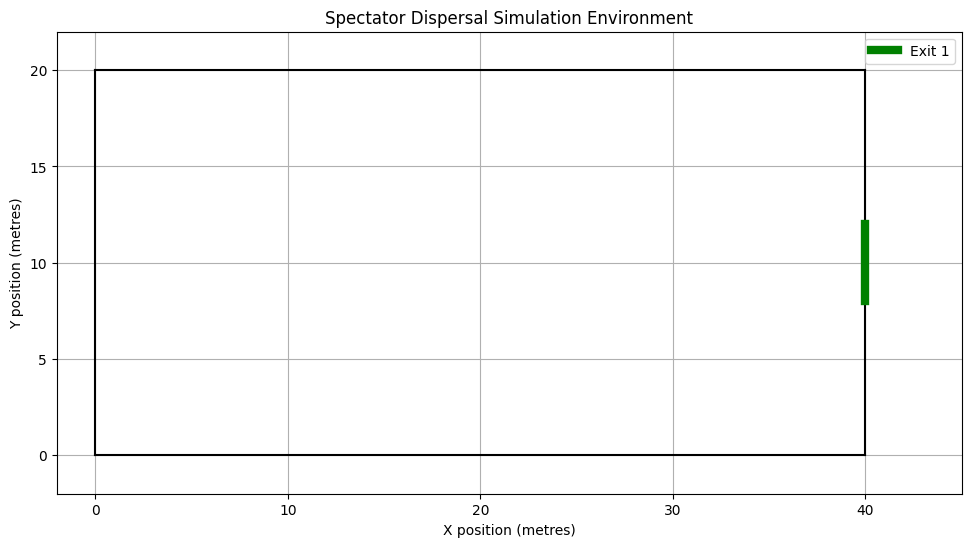

In [5]:
# Create the simulation environment

fig, ax = plt.subplots(figsize=(12, 6))

# Draw the top boundary
ax.plot([0, WIDTH], [HEIGHT, HEIGHT], color="black")

# Draw the bottom boundary
ax.plot([0, WIDTH], [0, 0], color="black")

# Draw the left boundary
ax.plot([0, 0], [0, HEIGHT], color="black")

# Draw the right boundary below the exit
ax.plot([WIDTH, WIDTH], [0, EXIT_Y_MIN], color="black")

# Draw the right boundary above the exit
ax.plot([WIDTH, WIDTH], [EXIT_Y_MAX, HEIGHT], color="black")

# Draw the exit opening
ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MIN, EXIT_Y_MAX],
    color="green",
    linewidth=6,
    label="Exit 1"
)

# Configure the coordinate system
ax.set_xlim(-2, WIDTH + 5)
ax.set_ylim(-2, HEIGHT + 2)

ax.set_xlabel("X position (metres)")
ax.set_ylabel("Y position (metres)")
ax.set_title("Spectator Dispersal Simulation Environment")

ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.show()

In [6]:
# Initial positions of five example pedestrians

agents = np.array([
    [5, 4],
    [10, 8],
    [15, 5],
    [20, 12],
    [30, 15]
])

print("Number of pedestrians:", len(agents))
print("Pedestrian positions:")
print(agents)

Number of pedestrians: 5
Pedestrian positions:
[[ 5  4]
 [10  8]
 [15  5]
 [20 12]
 [30 15]]


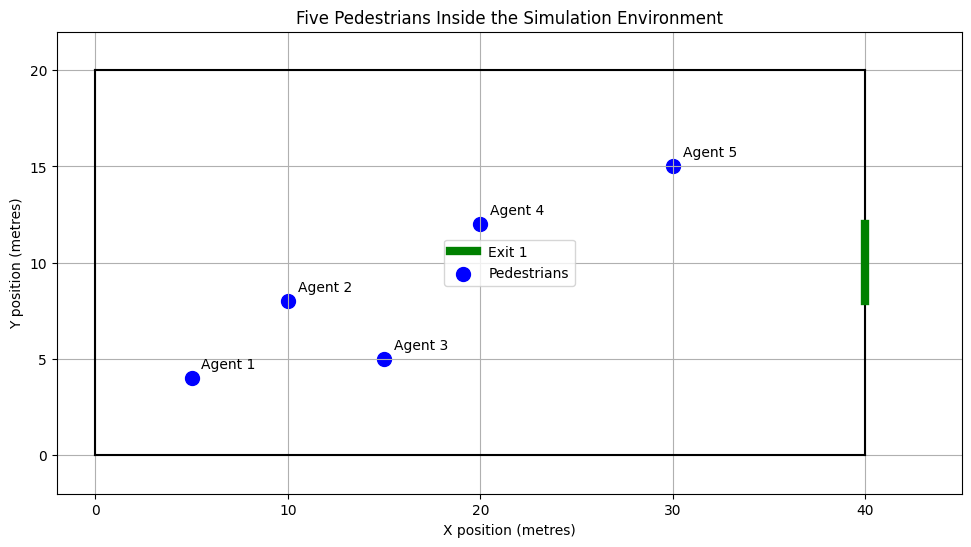

In [7]:
# Draw the environment
fig, ax = plt.subplots(figsize=(12, 6))

# Draw boundaries
ax.plot([0, WIDTH], [HEIGHT, HEIGHT], color="black")
ax.plot([0, WIDTH], [0, 0], color="black")
ax.plot([0, 0], [0, HEIGHT], color="black")
ax.plot([WIDTH, WIDTH], [0, EXIT_Y_MIN], color="black")
ax.plot([WIDTH, WIDTH], [EXIT_Y_MAX, HEIGHT], color="black")

# Draw the exit
ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MIN, EXIT_Y_MAX],
    color="green",
    linewidth=6,
    label="Exit 1"
)

# Draw pedestrians
ax.scatter(
    agents[:, 0],
    agents[:, 1],
    color="blue",
    s=100,
    label="Pedestrians"
)

# Add pedestrian labels
for i, position in enumerate(agents):
    ax.text(
        position[0] + 0.5,
        position[1] + 0.5,
        f"Agent {i + 1}"
    )

# Configure graph
ax.set_xlim(-2, WIDTH + 5)
ax.set_ylim(-2, HEIGHT + 2)
ax.set_xlabel("X position (metres)")
ax.set_ylabel("Y position (metres)")
ax.set_title("Five Pedestrians Inside the Simulation Environment")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.show()

In [8]:
# Check whether all pedestrians are inside the environment

for i, position in enumerate(agents):

    x = position[0]
    y = position[1]

    if 0 <= x <= WIDTH and 0 <= y <= HEIGHT:
        print(f"Agent {i + 1}: Valid position")
    else:
        print(f"Agent {i + 1}: Invalid position")

Agent 1: Valid position
Agent 2: Valid position
Agent 3: Valid position
Agent 4: Valid position
Agent 5: Valid position


In [9]:
#Lesson 3
#Create the pedestrian's initial information
import numpy as np
import matplotlib.pyplot as plt

# Initial pedestrian information

position = np.array([5.0, 4.0])

velocity = np.array([1.0, 0.0])

acceleration = np.array([0.5, 0.0])

print("Initial position:", position)
print("Initial velocity:", velocity)
print("Initial acceleration:", acceleration)

Initial position: [5. 4.]
Initial velocity: [1. 0.]
Initial acceleration: [0.5 0. ]


In [10]:
#Define the time step and Simulation time settings

dt = 0.1
total_steps = 10

print("Time step:", dt, "seconds")
print("Total simulation steps:", total_steps)

Time step: 0.1 seconds
Total simulation steps: 10


In [11]:
# Store the movement history

position_history = [position.copy()]
velocity_history = [velocity.copy()]

# Simulate pedestrian movement

for step in range(total_steps):

    # Update position using the current velocity
    position = position + velocity * dt

    # Update velocity using acceleration
    velocity = velocity + acceleration * dt

    # Save the new values
    position_history.append(position.copy())
    velocity_history.append(velocity.copy())

print("Final position:", position)
print("Final velocity:", velocity)

Final position: [6.225 4.   ]
Final velocity: [1.5 0. ]


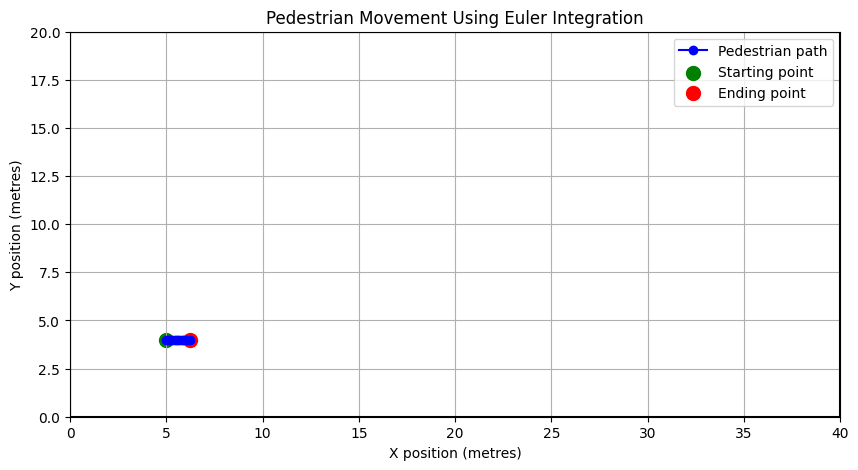

In [12]:
#Draw the pedestrian's movement
# Convert the movement history into an array

position_history = np.array(position_history)

# Draw the environment
fig, ax = plt.subplots(figsize=(10, 5))

# Draw boundaries
ax.plot([0, WIDTH], [0, 0], color="black")
ax.plot([0, WIDTH], [HEIGHT, HEIGHT], color="black")
ax.plot([0, 0], [0, HEIGHT], color="black")
ax.plot([WIDTH, WIDTH], [0, HEIGHT], color="black")

# Draw the pedestrian's path
ax.plot(
    position_history[:, 0],
    position_history[:, 1],
    marker="o",
    color="blue",
    label="Pedestrian path"
)

# Mark the starting point
ax.scatter(5, 4, color="green", s=100, label="Starting point")

# Mark the ending point
ax.scatter(
    position_history[-1, 0],
    position_history[-1, 1],
    color="red",
    s=100,
    label="Ending point"
)

ax.set_xlim(0, WIDTH)
ax.set_ylim(0, HEIGHT)
ax.set_xlabel("X position (metres)")
ax.set_ylabel("Y position (metres)")
ax.set_title("Pedestrian Movement Using Euler Integration")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.show()

In [13]:
#Lesson 4
#Enter the pedestrian information
import numpy as np

# Pedestrian's current position
position = np.array([5.0, 4.0])

# Pedestrian's current velocity
velocity = np.array([0.5, 0.0])

# Target exit position
exit_position = np.array([40.0, 10.0])

# Desired walking speed
desired_speed = 1.2

# Relaxation time
tau = 0.5

In [14]:
#Calculate the direction towards the exit
# Calculate direction vector
direction = exit_position - position

# Calculate distance to the exit
distance = np.linalg.norm(direction)

# Calculate unit direction vector
desired_direction = direction / distance

print("Direction vector:", direction)
print("Distance to exit:", distance)
print("Desired direction:", desired_direction)

Direction vector: [35.  6.]
Distance to exit: 35.510561809129406
Desired direction: [0.98562225 0.16896382]


In [15]:
#Calculate desired velocity
desired_velocity = desired_speed * desired_direction

print("Desired velocity:", desired_velocity)

Desired velocity: [1.18274671 0.20275658]


In [16]:
# Calculate desired acceleration
desired_acceleration = (desired_velocity - velocity) / tau

print("Current velocity:", velocity)
print("Desired velocity:", desired_velocity)
print("Desired acceleration:", desired_acceleration)

Current velocity: [0.5 0. ]
Desired velocity: [1.18274671 0.20275658]
Desired acceleration: [1.36549341 0.40551316]


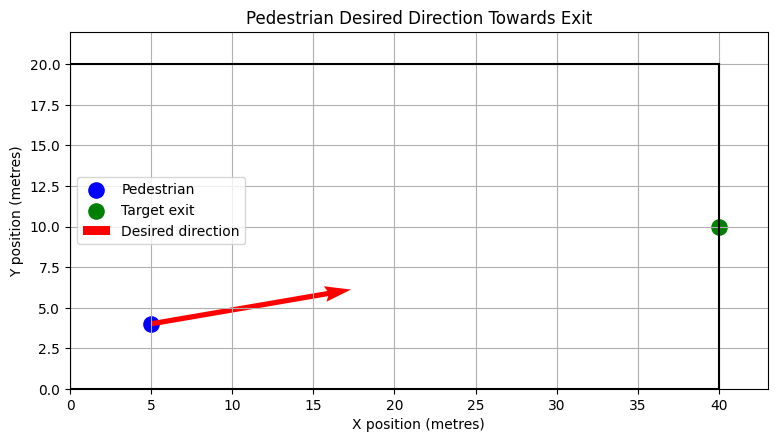

In [17]:
#Visualise the desired direction
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

# Draw the viewing area
ax.plot([0, WIDTH], [0, 0], color="black")
ax.plot([0, WIDTH], [HEIGHT, HEIGHT], color="black")
ax.plot([0, 0], [0, HEIGHT], color="black")
ax.plot([WIDTH, WIDTH], [0, HEIGHT], color="black")

# Draw the pedestrian
ax.scatter(
    position[0], position[1],
    color="blue", s=120, label="Pedestrian"
)

# Draw the target exit
ax.scatter(
    exit_position[0], exit_position[1],
    color="green", s=120, label="Target exit"
)

# Draw the desired direction
ax.quiver(
    position[0], position[1],
    desired_direction[0], desired_direction[1],
    angles="xy", scale_units="xy", scale=0.08,
    color="red", label="Desired direction"
)

ax.set_xlim(0, WIDTH + 3)
ax.set_ylim(0, HEIGHT + 2)
ax.set_xlabel("X position (metres)")
ax.set_ylabel("Y position (metres)")
ax.set_title("Pedestrian Desired Direction Towards Exit")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.show()

In [18]:
print("Desired direction:", desired_direction)
print("Desired velocity:", desired_velocity)
print("Desired acceleration:", desired_acceleration)

Desired direction: [0.98562225 0.16896382]
Desired velocity: [1.18274671 0.20275658]
Desired acceleration: [1.36549341 0.40551316]


In [19]:
#Lesson 5
# Set up our three pedestrians
import numpy as np
import matplotlib.pyplot as plt

# Environment dimensions
WIDTH = 40
HEIGHT = 20

# Exit opening
EXIT_Y_MIN = 8
EXIT_Y_MAX = 12

# Target point for the pedestrians
target_exit = np.array([40.0, 10.0])

# Initial positions of three example pedestrians
demo_positions = np.array([
    [10.0, 10.0],   # Pedestrian 1
    [10.8, 10.0],   # Pedestrian 2 (close to pedestrian 1)
    [20.0, 19.2]    # Pedestrian 3 (close to top wall)
])

# Initial velocities
demo_velocities = np.array([
    [0.5, 0.0],
    [0.5, 0.0],
    [0.5, 0.0]
])

# Pedestrian parameters
radii = np.array([0.3, 0.3, 0.3])
desired_speed = 1.2
tau = 0.5

print("Number of pedestrians:", len(demo_positions))
print("Initial positions:")
print(demo_positions)

Number of pedestrians: 3
Initial positions:
[[10.  10. ]
 [10.8 10. ]
 [20.  19.2]]


In [20]:
#Calculate desired movement acceleration
def calculate_desired_acceleration(position, velocity):

    # Direction towards the target exit
    direction = target_exit - position

    # Distance to the target
    distance = np.linalg.norm(direction)

    # Avoid division by zero
    if distance < 1e-12:
        return np.zeros(2)

    # Unit direction vector
    desired_direction = direction / distance

    # Desired velocity
    desired_velocity = desired_speed * desired_direction

    # Desired acceleration
    desired_acceleration = (
        desired_velocity - velocity
    ) / tau

    return desired_acceleration

In [21]:
#Calculate pedestrian interactions
def calculate_pedestrian_interactions(positions, radii):

    number_of_agents = len(positions)

    # Initially, no pedestrian interaction
    interaction_accelerations = np.zeros_like(positions)

    # Illustrative interaction parameters
    A = 2.0
    B = 0.5

    # Compare every pedestrian with every other pedestrian
    for i in range(number_of_agents):

        for j in range(number_of_agents):

            # A pedestrian should not interact with themselves
            if i == j:
                continue

            # Difference between pedestrian positions
            difference = positions[i] - positions[j]

            # Distance between pedestrians
            distance = np.linalg.norm(difference)

            # Avoid division by zero
            if distance < 1e-12:
                continue

            # Direction pointing away from pedestrian j
            direction_away = difference / distance

            # Repulsion strength
            strength = A * np.exp(
                (radii[i] + radii[j] - distance) / B
            )

            # Add interaction acceleration
            interaction_accelerations[i] += (
                strength * direction_away
            )

    return interaction_accelerations

In [22]:
# Calculate wall interactions
def calculate_wall_interactions(positions, radii):

    number_of_agents = len(positions)

    # Initially, no wall interaction
    wall_accelerations = np.zeros_like(positions)

    # Illustrative wall interaction parameters
    A_wall = 2.0
    B_wall = 0.5

    for i in range(number_of_agents):

        x = positions[i, 0]
        y = positions[i, 1]
        radius = radii[i]

        # Each wall is represented by:
        # distance from wall and direction away from wall

        walls = [
            (x, np.array([1.0, 0.0])),                 # Left
            (y, np.array([0.0, 1.0])),                 # Bottom
            (HEIGHT - y, np.array([0.0, -1.0]))        # Top
        ]

        # Right wall exists only outside the exit opening
        if not (EXIT_Y_MIN <= y <= EXIT_Y_MAX):

            walls.append((
                WIDTH - x,
                np.array([-1.0, 0.0])
            ))

        # Calculate the influence of each wall
        for distance, direction_away in walls:

            strength = A_wall * np.exp(
                (radius - distance) / B_wall
            )

            wall_accelerations[i] += (
                strength * direction_away
            )

    return wall_accelerations

In [23]:
#Combine all three acceleration components
# Calculate desired movement acceleration
desired_accelerations = np.array([
    calculate_desired_acceleration(
        demo_positions[i],
        demo_velocities[i]
    )
    for i in range(len(demo_positions))
])

# Calculate pedestrian interaction acceleration
pedestrian_accelerations = calculate_pedestrian_interactions(
    demo_positions,
    radii
)

# Calculate wall interaction acceleration
wall_accelerations = calculate_wall_interactions(
    demo_positions,
    radii
)

# Combine all acceleration components
total_accelerations = (
    desired_accelerations
    + pedestrian_accelerations
    + wall_accelerations
)

# Display the results
for i in range(len(demo_positions)):

    print(f"\nPedestrian {i + 1}")

    print("Desired acceleration:",
          desired_accelerations[i])

    print("Pedestrian interaction:",
          pedestrian_accelerations[i])

    print("Wall interaction:",
          wall_accelerations[i])

    print("Total acceleration:",
          total_accelerations[i])


Pedestrian 1
Desired acceleration: [1.4 0. ]
Pedestrian interaction: [-1.34064009e+00 -7.08306970e-12]
Wall interaction: [7.51133353e-09 0.00000000e+00]
Total acceleration: [ 5.93599154e-02 -7.08306970e-12]

Pedestrian 2
Desired acceleration: [1.4 0. ]
Pedestrian interaction: [ 1.34064009e+00 -2.34780316e-11]
Wall interaction: [1.51651209e-09 0.00000000e+00]
Total acceleration: [ 2.74064009e+00 -2.34780316e-11]

Pedestrian 3
Desired acceleration: [ 1.18037709 -1.00297346]
Pedestrian interaction: [3.11770204e-11 3.05611013e-11]
Wall interaction: [ 0.         -0.73575888]
Total acceleration: [ 1.18037709 -1.73873234]


In [24]:
#Update pedestrian movement using Euler integration
# Simulation time step
dt = 0.1

# Store the original positions and velocities
updated_positions = demo_positions.copy()
updated_velocities = demo_velocities.copy()

# Update positions using the current velocities
updated_positions = (
    updated_positions + updated_velocities * dt
)

# Update velocities using total acceleration
updated_velocities = (
    updated_velocities + total_accelerations * dt
)

print("Updated positions:")
print(updated_positions)

print("\nUpdated velocities:")
print(updated_velocities)

Updated positions:
[[10.05 10.  ]
 [10.85 10.  ]
 [20.05 19.2 ]]

Updated velocities:
[[ 5.05935992e-01 -7.08306970e-13]
 [ 7.74064009e-01 -2.34780316e-12]
 [ 6.18037709e-01 -1.73873234e-01]]


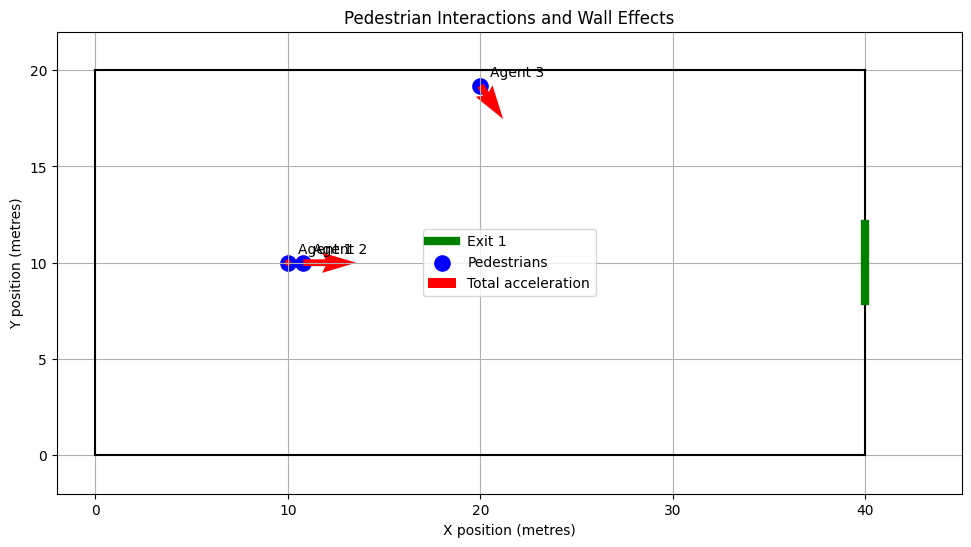

In [25]:
#Visualise the pedestrian interactions
# Draw the environment
fig, ax = plt.subplots(figsize=(12, 6))

# Draw the boundaries
ax.plot([0, WIDTH], [0, 0], color="black")
ax.plot([0, WIDTH], [HEIGHT, HEIGHT], color="black")
ax.plot([0, 0], [0, HEIGHT], color="black")

# Draw right boundary below and above the exit
ax.plot(
    [WIDTH, WIDTH],
    [0, EXIT_Y_MIN],
    color="black"
)

ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MAX, HEIGHT],
    color="black"
)

# Draw exit opening
ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MIN, EXIT_Y_MAX],
    color="green",
    linewidth=6,
    label="Exit 1"
)

# Draw pedestrian positions
ax.scatter(
    demo_positions[:, 0],
    demo_positions[:, 1],
    color="blue",
    s=120,
    label="Pedestrians"
)

# Draw total acceleration directions
ax.quiver(
    demo_positions[:, 0],
    demo_positions[:, 1],
    total_accelerations[:, 0],
    total_accelerations[:, 1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="red",
    label="Total acceleration"
)

# Add pedestrian labels
for i, position in enumerate(demo_positions):

    ax.text(
        position[0] + 0.5,
        position[1] + 0.5,
        f"Agent {i + 1}"
    )

ax.set_xlim(-2, WIDTH + 5)
ax.set_ylim(-2, HEIGHT + 2)

ax.set_xlabel("X position (metres)")
ax.set_ylabel("Y position (metres)")

ax.set_title("Pedestrian Interactions and Wall Effects")

ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.show()

In [26]:
#Verify our calculations
# Verification checks

# Check that every pedestrian has an acceleration vector
assert total_accelerations.shape == (3, 2)

# Check that all acceleration values are finite
assert np.all(np.isfinite(total_accelerations))

# Check that the updated positions are finite
assert np.all(np.isfinite(updated_positions))

# Check that the updated velocities are finite
assert np.all(np.isfinite(updated_velocities))

print("Verification results:")
print("Number of pedestrians:", len(demo_positions))
print("Acceleration dimensions:", total_accelerations.shape)
print("All acceleration values are finite: PASS")
print("All updated positions are finite: PASS")
print("All updated velocities are finite: PASS")

Verification results:
Number of pedestrians: 3
Acceleration dimensions: (3, 2)
All acceleration values are finite: PASS
All updated positions are finite: PASS
All updated velocities are finite: PASS


In [27]:
# Lesson 6: Simulating multiple pedestrians over time

import numpy as np
import matplotlib.pyplot as plt

# Environment dimensions
WIDTH = 40
HEIGHT = 20

# Exit opening
EXIT_Y_MIN = 8
EXIT_Y_MAX = 12

# Target exit
target_exit = np.array([40.0, 10.0])

# Initial pedestrian positions
simulation_positions = demo_positions.copy()

# Initial pedestrian velocities
simulation_velocities = demo_velocities.copy()

# Pedestrian radii
simulation_radii = radii.copy()

# Track whether each pedestrian has exited
exited = np.zeros(len(simulation_positions), dtype=bool)

# Store exit times
exit_times = np.full(len(simulation_positions), np.nan)

print("Simulation prepared successfully!")
print("Number of pedestrians:", len(simulation_positions))
print("Initial positions:")
print(simulation_positions)

Simulation prepared successfully!
Number of pedestrians: 3
Initial positions:
[[10.  10. ]
 [10.8 10. ]
 [20.  19.2]]


In [28]:
#Define simulation time settings
# Simulation time settings

dt = 0.05

total_steps = 2000

# Numerical safety limits (assumed)
MAX_SPEED = 2.0
MAX_ACCELERATION = 4.0

# Maximum simulation duration
MAX_SIMULATION_TIME = dt * total_steps

print("Time step:", dt, "seconds")
print("Total steps:", total_steps)
print("Maximum simulation time:", MAX_SIMULATION_TIME, "seconds")

Time step: 0.05 seconds
Total steps: 2000
Maximum simulation time: 100.0 seconds


In [29]:
#Understand the simulation history
# Store the initial positions

simulation_history = [simulation_positions.copy()]

# Store the number of pedestrians who have exited
exit_count_history = [0]

# Store simulation time
time_history = [0.0]

print("Initial positions stored.")
print("Initial exit count:", exit_count_history[0])

Initial positions stored.
Initial exit count: 0


In [30]:
#Create the simulation loop
# Run the pedestrian simulation

for step in range(total_steps):

    # Find pedestrians who are still inside
    active_indices = np.where(~exited)[0]

    # Stop if everybody has exited
    if len(active_indices) == 0:
        print("All pedestrians have exited!")
        break

    # Get the current information of active pedestrians
    active_positions = simulation_positions[active_indices]
    active_velocities = simulation_velocities[active_indices]
    active_radii = simulation_radii[active_indices]

    # 1. Calculate desired movement acceleration
    desired_acc = np.array([
        calculate_desired_acceleration(
            active_positions[i],
            active_velocities[i]
        )
        for i in range(len(active_indices))
    ])

    # 2. Calculate pedestrian interaction acceleration
    pedestrian_acc = calculate_pedestrian_interactions(
        active_positions,
        active_radii
    )

    # 3. Calculate wall interaction acceleration
    wall_acc = calculate_wall_interactions(
        active_positions,
        active_radii
    )

    # 4. Combine all acceleration components
    total_acc = desired_acc + pedestrian_acc + wall_acc

    # Limit acceleration for numerical stability
    acceleration_magnitudes = np.linalg.norm(total_acc, axis=1)

    acceleration_scales = np.minimum(
        1.0,
        MAX_ACCELERATION / np.maximum(
            acceleration_magnitudes, 1e-12
        )
    )

    total_acc = total_acc * acceleration_scales[:, None]

    # 5. Update velocity using acceleration
    new_velocities = active_velocities + total_acc * dt

    # Limit maximum speed
    speed_magnitudes = np.linalg.norm(new_velocities, axis=1)

    speed_scales = np.minimum(
        1.0,
        MAX_SPEED / np.maximum(speed_magnitudes, 1e-12)
    )

    new_velocities = new_velocities * speed_scales[:, None]

    # Update position using the old velocity
    new_positions = active_positions + active_velocities * dt

    # 6. Check boundaries and exit conditions
    for local_index, agent_index in enumerate(active_indices):

        x = new_positions[local_index, 0]
        y = new_positions[local_index, 1]

        radius = simulation_radii[agent_index]

        # Check whether the pedestrian has reached the exit
        if x >= WIDTH and EXIT_Y_MIN <= y <= EXIT_Y_MAX:

            exited[agent_index] = True
            exit_times[agent_index] = (step + 1) * dt

            # Keep the pedestrian at the exit after leaving
            simulation_positions[agent_index] = [WIDTH, y]
            simulation_velocities[agent_index] = [0.0, 0.0]

        else:

            # Keep pedestrian inside the left boundary
            if x < radius:
                x = radius
                new_velocities[local_index, 0] = max(
                    0.0, new_velocities[local_index, 0]
                )

            # Keep pedestrian inside the bottom boundary
            if y < radius:
                y = radius
                new_velocities[local_index, 1] = max(
                    0.0, new_velocities[local_index, 1]
                )

            # Keep pedestrian inside the top boundary
            if y > HEIGHT - radius:
                y = HEIGHT - radius
                new_velocities[local_index, 1] = min(
                    0.0, new_velocities[local_index, 1]
                )

            # Keep pedestrian away from the solid part of right wall
            if not (EXIT_Y_MIN <= y <= EXIT_Y_MAX):
                if x > WIDTH - radius:
                    x = WIDTH - radius
                    new_velocities[local_index, 0] = min(
                        0.0, new_velocities[local_index, 0]
                    )

            new_positions[local_index] = [x, y]

            # Save the updated position and velocity
            simulation_positions[agent_index] = new_positions[local_index]
            simulation_velocities[agent_index] = new_velocities[local_index]

    # Save the state after this time step
    simulation_history.append(simulation_positions.copy())

    # Record the number of pedestrians who have exited
    exit_count_history.append(np.sum(exited))

    # Record the current simulation time
    time_history.append((step + 1) * dt)


print("Simulation finished.")
print("Pedestrians who exited:", np.sum(exited))
print("Total pedestrians:", len(simulation_positions))

All pedestrians have exited!
Simulation finished.
Pedestrians who exited: 3
Total pedestrians: 3


In [31]:
#Display the exit results
print("EXIT RESULTS")
print("---------------------------")

for i in range(len(exited)):

    if exited[i]:
        print(
            f"Pedestrian {i + 1}: Exited at "
            f"{exit_times[i]:.2f} seconds"
        )
    else:
        print(f"Pedestrian {i + 1}: Still inside")

print("---------------------------")
print("Total exited:", np.sum(exited))
print("Total remaining:", np.sum(~exited))

EXIT RESULTS
---------------------------
Pedestrian 1: Exited at 26.20 seconds
Pedestrian 2: Exited at 23.75 seconds
Pedestrian 3: Exited at 18.55 seconds
---------------------------
Total exited: 3
Total remaining: 0


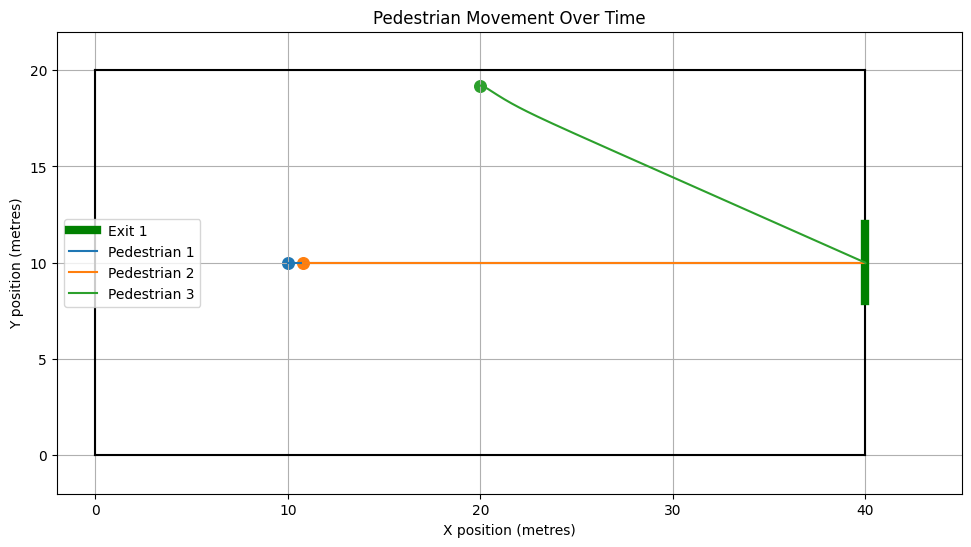

In [32]:
#Visualise pedestrian movement over time
# Convert history into a NumPy array
history_array = np.array(simulation_history)

# Create the graph
fig, ax = plt.subplots(figsize=(12, 6))

# Draw the environment boundaries
ax.plot([0, WIDTH], [0, 0], color="black")
ax.plot([0, WIDTH], [HEIGHT, HEIGHT], color="black")
ax.plot([0, 0], [0, HEIGHT], color="black")

# Draw the right boundary around the exit
ax.plot(
    [WIDTH, WIDTH],
    [0, EXIT_Y_MIN],
    color="black"
)

ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MAX, HEIGHT],
    color="black"
)

# Draw the exit
ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MIN, EXIT_Y_MAX],
    color="green",
    linewidth=6,
    label="Exit 1"
)

# Draw each pedestrian's path
for i in range(len(simulation_positions)):

    ax.plot(
        history_array[:, i, 0],
        history_array[:, i, 1],
        label=f"Pedestrian {i + 1}"
    )

    # Mark the starting point
    ax.scatter(
        history_array[0, i, 0],
        history_array[0, i, 1],
        marker="o",
        s=70
    )

# Graph settings
ax.set_xlim(-2, WIDTH + 5)
ax.set_ylim(-2, HEIGHT + 2)

ax.set_xlabel("X position (metres)")
ax.set_ylabel("Y position (metres)")

ax.set_title("Pedestrian Movement Over Time")

ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.show()

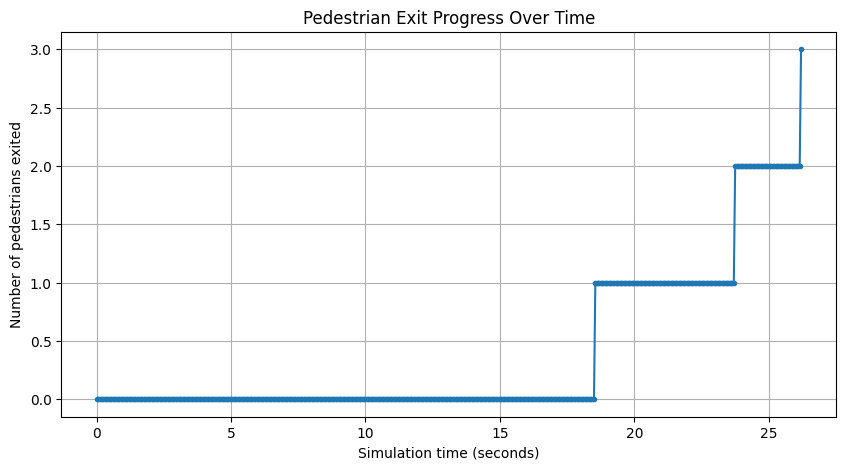

In [33]:
#Draw the number of pedestrians who have exited
# Plot the number of pedestrians who have exited over time

plt.figure(figsize=(10, 5))

plt.plot(
    time_history,
    exit_count_history,
    marker="o",
    markersize=3
)

plt.xlabel("Simulation time (seconds)")
plt.ylabel("Number of pedestrians exited")

plt.title("Pedestrian Exit Progress Over Time")

plt.grid(True)
plt.show()

In [34]:
# Simulation verification checks

history_array = np.array(simulation_history)

# Check the number of pedestrians
assert len(simulation_positions) == 3

# Check the dimensions of the stored history
assert history_array.shape[1:] == (3, 2)

# Check that all recorded positions are finite
assert np.all(np.isfinite(history_array))

# Check that exit count never decreases
assert np.all(np.diff(exit_count_history) >= 0)

# Check that every pedestrian is either inside or exited
assert np.sum(exited) + np.sum(~exited) == 3

# Check that pedestrians who have exited are at the exit
for i in range(len(exited)):
    if exited[i]:
        assert simulation_positions[i, 0] == WIDTH

print("SIMULATION VERIFICATION")
print("-----------------------------")
print("Pedestrian count: PASS")
print("Position history dimensions: PASS")
print("All recorded positions are finite: PASS")
print("Exit count is non-decreasing: PASS")
print("Agent status conservation: PASS")
print("Exited pedestrians are at the exit: PASS")

SIMULATION VERIFICATION
-----------------------------
Pedestrian count: PASS
Position history dimensions: PASS
All recorded positions are finite: PASS
Exit count is non-decreasing: PASS
Agent status conservation: PASS
Exited pedestrians are at the exit: PASS


In [35]:
#Calculate the dispersal time

if np.all(exited):

    clearance_time = np.max(exit_times)

    print(
        "All pedestrians exited successfully."
    )

    print(
        "Total clearance time:",
        round(clearance_time, 2),
        "seconds"
    )

else:

    remaining = np.sum(~exited)

    print("Simulation reached its time limit.")
    print("Pedestrians still inside:", remaining)
    print("Clearance time: Not reached")

All pedestrians exited successfully.
Total clearance time: 26.2 seconds


In [36]:
# Lesson 7: Random Crowd Generation

import numpy as np
import matplotlib.pyplot as plt

# Create a random number generator
random_seed = 42
rng = np.random.default_rng(random_seed)

print("Random generator created successfully!")
print("Random seed:", random_seed)


Random generator created successfully!
Random seed: 42


In [37]:
#Choose the number of pedestrians
# Number of pedestrians in our crowd
NUMBER_OF_PEDESTRIANS = 100

# Pedestrian radius
CROWD_RADIUS = 0.3

# Walking speed range (assumed values)
MIN_WALKING_SPEED = 0.8
MAX_WALKING_SPEED = 1.6

# Initial crowd placement region
START_X_MIN = 2.0
START_X_MAX = 30.0

START_Y_MIN = 1.0
START_Y_MAX = 19.0

print("Number of pedestrians:", NUMBER_OF_PEDESTRIANS)
print("Pedestrian radius:", CROWD_RADIUS, "metres")
print("Walking speed range:",
      MIN_WALKING_SPEED, "to", MAX_WALKING_SPEED, "m/s")

Number of pedestrians: 100
Pedestrian radius: 0.3 metres
Walking speed range: 0.8 to 1.6 m/s


In [38]:
#Generate random pedestrian positions
# Generate random pedestrian positions without initial overlap

MINIMUM_DISTANCE = 0.65

crowd_positions = []

for i in range(NUMBER_OF_PEDESTRIANS):

    placed = False

    # Try different random positions
    for attempt in range(10000):

        x = rng.uniform(START_X_MIN, START_X_MAX)
        y = rng.uniform(START_Y_MIN, START_Y_MAX)

        candidate = np.array([x, y])

        # First pedestrian can be placed immediately
        if len(crowd_positions) == 0:
            crowd_positions.append(candidate)
            placed = True
            break

        # Calculate distances from existing pedestrians
        existing_positions = np.array(crowd_positions)

        distances = np.linalg.norm(
            existing_positions - candidate,
            axis=1
        )

        # Accept only if sufficiently far from all existing agents
        if np.all(distances >= MINIMUM_DISTANCE):

            crowd_positions.append(candidate)
            placed = True
            break

    if not placed:
        raise RuntimeError(
            f"Could not place pedestrian {i + 1}. "
            "Try a larger starting area or a smaller minimum distance."
        )

# Convert the positions into a NumPy array
crowd_positions = np.array(crowd_positions)

print("Crowd positions generated successfully!")
print("Position array shape:", crowd_positions.shape)
print("First five pedestrian positions:")
print(crowd_positions[:5])

Crowd positions generated successfully!
Position array shape: (100, 2)
First five pedestrian positions:
[[23.67076936  8.89981192]
 [26.04074176 13.55262452]
 [ 4.63696574 18.56120233]
 [23.31191166 15.14915749]
 [ 5.58718171  9.10694688]]


In [39]:
# Generate an individual desired walking speed for each pedestrian

crowd_desired_speeds = rng.uniform(
    MIN_WALKING_SPEED,
    MAX_WALKING_SPEED,
    NUMBER_OF_PEDESTRIANS
)

print("Individual walking speeds generated!")
print("First ten walking speeds:")
print(crowd_desired_speeds[:10])

print("Minimum generated speed:",
      np.min(crowd_desired_speeds))

print("Maximum generated speed:",
      np.max(crowd_desired_speeds))

print("Average walking speed:",
      np.mean(crowd_desired_speeds))

Individual walking speeds generated!
First ten walking speeds:
[0.91227168 1.13529146 1.57298553 1.27683404 1.54641858 1.44348873
 1.17390528 1.42781076 0.81426943 0.8873152 ]
Minimum generated speed: 0.8142694271815902
Maximum generated speed: 1.5836565444692743
Average walking speed: 1.185034926197093


In [40]:
#Generate pedestrian velocities
# Initialise pedestrian velocities

crowd_velocities = np.zeros(
    (NUMBER_OF_PEDESTRIANS, 2)
)

print("Initial velocities created!")
print("Velocity array shape:", crowd_velocities.shape)
print("First five velocities:")
print(crowd_velocities[:5])

Initial velocities created!
Velocity array shape: (100, 2)
First five velocities:
[[0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]


In [41]:
#Give every pedestrian a radius
# Assign a radius to every pedestrian

crowd_radii = np.full(
    NUMBER_OF_PEDESTRIANS,
    CROWD_RADIUS
)

print("Radius array shape:", crowd_radii.shape)
print("First five radii:")
print(crowd_radii[:5])

Radius array shape: (100,)
First five radii:
[0.3 0.3 0.3 0.3 0.3]


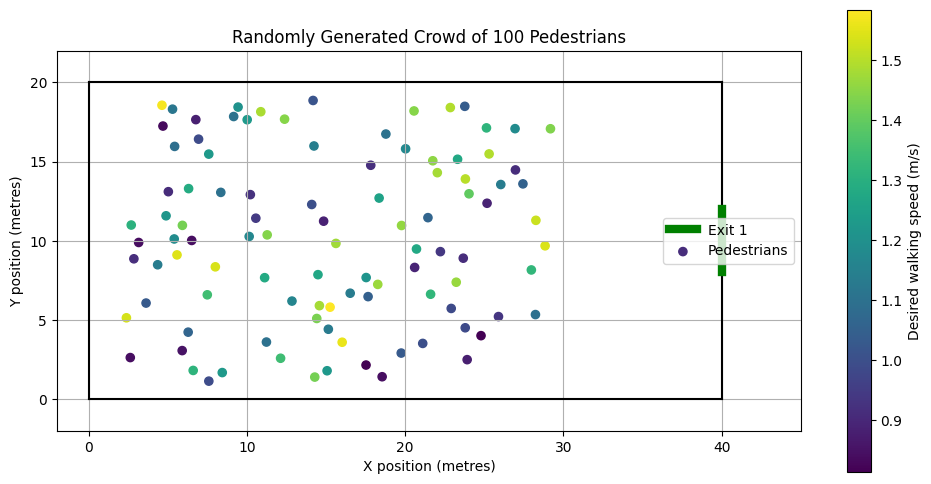

In [42]:
#Draw all 100 pedestrians
# Visualise the generated crowd

fig, ax = plt.subplots(figsize=(12, 6))

# Draw environment boundaries
ax.plot([0, WIDTH], [0, 0], color="black")
ax.plot([0, WIDTH], [HEIGHT, HEIGHT], color="black")
ax.plot([0, 0], [0, HEIGHT], color="black")

# Draw the right boundary around the exit
ax.plot(
    [WIDTH, WIDTH],
    [0, EXIT_Y_MIN],
    color="black"
)

ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MAX, HEIGHT],
    color="black"
)

# Draw the exit
ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MIN, EXIT_Y_MAX],
    color="green",
    linewidth=6,
    label="Exit 1"
)

# Draw pedestrians
scatter = ax.scatter(
    crowd_positions[:, 0],
    crowd_positions[:, 1],
    c=crowd_desired_speeds,
    cmap="viridis",
    s=35,
    label="Pedestrians"
)

# Show walking speed using a colour bar
colour_bar = plt.colorbar(scatter, ax=ax)
colour_bar.set_label("Desired walking speed (m/s)")

ax.set_xlim(-2, WIDTH + 5)
ax.set_ylim(-2, HEIGHT + 2)

ax.set_xlabel("X position (metres)")
ax.set_ylabel("Y position (metres)")

ax.set_title("Randomly Generated Crowd of 100 Pedestrians")

ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.show()

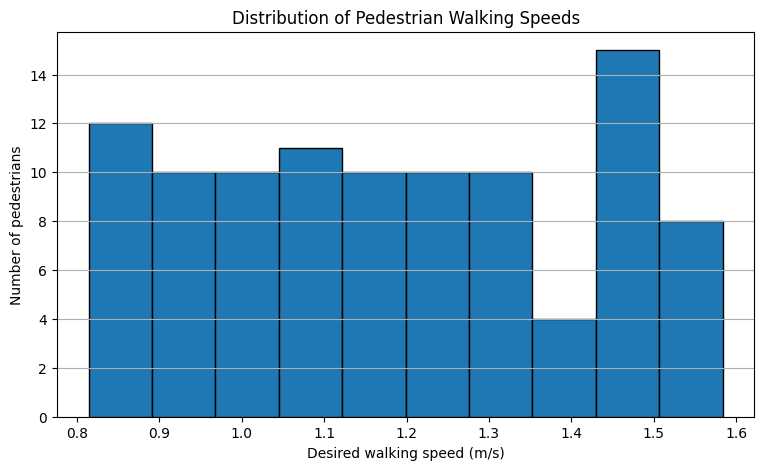

In [43]:
#Analyse walking-speed variation
# Visualise the walking speed distribution

plt.figure(figsize=(9, 5))

plt.hist(
    crowd_desired_speeds,
    bins=10,
    edgecolor="black"
)

plt.xlabel("Desired walking speed (m/s)")
plt.ylabel("Number of pedestrians")

plt.title("Distribution of Pedestrian Walking Speeds")

plt.grid(axis="y")
plt.show()

In [44]:
# Calculate desired acceleration for an individual pedestrian

def calculate_crowd_desired_acceleration(
    position,
    velocity,
    individual_desired_speed
):

    # Calculate direction towards the target exit
    direction = target_exit - position

    # Calculate distance to the exit
    distance = np.linalg.norm(direction)

    # Avoid division by zero
    if distance < 1e-12:
        return np.zeros(2)

    # Calculate unit direction
    desired_direction = direction / distance

    # Calculate individual desired velocity
    desired_velocity = (
        individual_desired_speed * desired_direction
    )

    # Calculate desired acceleration
    desired_acceleration = (
        desired_velocity - velocity
    ) / tau

    return desired_acceleration


In [45]:
# Test individual desired acceleration calculations

for i in range(5):

    acceleration = calculate_crowd_desired_acceleration(
        crowd_positions[i],
        crowd_velocities[i],
        crowd_desired_speeds[i]
    )

    print(f"\nPedestrian {i + 1}")

    print("Position:", crowd_positions[i])
    print("Desired speed:", crowd_desired_speeds[i])
    print("Desired acceleration:", acceleration)


Pedestrian 1
Position: [23.67076936  8.89981192]
Desired speed: 0.9122716776511302
Desired acceleration: [1.8204162  0.12265123]

Pedestrian 2
Position: [26.04074176 13.55262452]
Desired speed: 1.135291455453043
Desired acceleration: [ 2.20043964 -0.56001083]

Pedestrian 3
Position: [ 4.63696574 18.56120233]
Desired speed: 1.5729855297145454
Desired acceleration: [ 3.05764289 -0.74023907]

Pedestrian 4
Position: [23.31191166 15.14915749]
Desired speed: 1.2768340425874984
Desired acceleration: [ 2.44015136 -0.7529157 ]

Pedestrian 5
Position: [5.58718171 9.10694688]
Desired speed: 1.546418577280169
Desired acceleration: [3.09179622 0.08023575]


In [46]:
# Lesson 7 verification checks

# Check the number of generated pedestrians
assert len(crowd_positions) == NUMBER_OF_PEDESTRIANS

# Check position dimensions
assert crowd_positions.shape == (NUMBER_OF_PEDESTRIANS, 2)

# Check velocity dimensions
assert crowd_velocities.shape == (NUMBER_OF_PEDESTRIANS, 2)

# Check walking speed dimensions
assert crowd_desired_speeds.shape == (NUMBER_OF_PEDESTRIANS,)

# Check radius dimensions
assert crowd_radii.shape == (NUMBER_OF_PEDESTRIANS,)

# Check that all positions are within the placement region
assert np.all(crowd_positions[:, 0] >= START_X_MIN)
assert np.all(crowd_positions[:, 0] <= START_X_MAX)
assert np.all(crowd_positions[:, 1] >= START_Y_MIN)
assert np.all(crowd_positions[:, 1] <= START_Y_MAX)

# Check walking speeds are within the selected range
assert np.all(crowd_desired_speeds >= MIN_WALKING_SPEED)
assert np.all(crowd_desired_speeds <= MAX_WALKING_SPEED)

# Check that all values are finite
assert np.all(np.isfinite(crowd_positions))
assert np.all(np.isfinite(crowd_velocities))
assert np.all(np.isfinite(crowd_desired_speeds))

# Check minimum distance between different pedestrians
pairwise_distances = np.linalg.norm(
    crowd_positions[:, None, :] - crowd_positions[None, :, :],
    axis=2
)

np.fill_diagonal(pairwise_distances, np.inf)

minimum_actual_distance = np.min(pairwise_distances)

assert minimum_actual_distance >= MINIMUM_DISTANCE

print("LESSON 7 VERIFICATION")
print("------------------------------")
print("Pedestrian count: PASS")
print("Position dimensions: PASS")
print("Velocity dimensions: PASS")
print("Walking speed dimensions: PASS")
print("Initial position boundaries: PASS")
print("Walking speed limits: PASS")
print("All generated values are finite: PASS")
print("Minimum separation check: PASS")

print(
    "Minimum pedestrian distance:",
    round(minimum_actual_distance, 4),
    "metres"
)

LESSON 7 VERIFICATION
------------------------------
Pedestrian count: PASS
Position dimensions: PASS
Velocity dimensions: PASS
Walking speed dimensions: PASS
Initial position boundaries: PASS
Walking speed limits: PASS
All generated values are finite: PASS
Minimum separation check: PASS
Minimum pedestrian distance: 0.6577 metres


In [47]:
# Lesson 8: Integrating the random crowd into the Social Force Model

import numpy as np
import matplotlib.pyplot as plt

# Environment dimensions
WIDTH = 40
HEIGHT = 20

# Exit opening
EXIT_Y_MIN = 8
EXIT_Y_MAX = 12

# Target exit
target_exit = np.array([40.0, 10.0])

# Social Force Model parameter
tau = 0.5

# Simulation time settings
dt = 0.05
total_steps = 2000

# Numerical safety limits (assumed)
MAX_SPEED = 2.0
MAX_ACCELERATION = 4.0

print("Lesson 8 environment prepared!")
print("Environment:", WIDTH, "x", HEIGHT, "metres")
print("Number of pedestrians:", len(crowd_positions))
print("Time step:", dt, "seconds")

Lesson 8 environment prepared!
Environment: 40 x 20 metres
Number of pedestrians: 100
Time step: 0.05 seconds


In [48]:
#Copy the 100 pedestrians into the new simulation
# Create independent simulation arrays

simulation_positions = crowd_positions.copy()

simulation_velocities = crowd_velocities.copy()

simulation_desired_speeds = crowd_desired_speeds.copy()

simulation_radii = crowd_radii.copy()

# Track whether pedestrians have exited
exited = np.zeros(
    len(simulation_positions),
    dtype=bool
)

# Store exit times
exit_times = np.full(
    len(simulation_positions),
    np.nan
)

print("Crowd copied into simulation successfully!")

print("Positions:", simulation_positions.shape)
print("Velocities:", simulation_velocities.shape)
print("Desired speeds:", simulation_desired_speeds.shape)
print("Radii:", simulation_radii.shape)

print("Initial exited pedestrians:", np.sum(exited))

Crowd copied into simulation successfully!
Positions: (100, 2)
Velocities: (100, 2)
Desired speeds: (100,)
Radii: (100,)
Initial exited pedestrians: 0


In [49]:
#Calculate desired acceleration for all pedestrians
# Calculate desired acceleration for all pedestrians

desired_accelerations = np.array([

    calculate_crowd_desired_acceleration(
        simulation_positions[i],
        simulation_velocities[i],
        simulation_desired_speeds[i]
    )

    for i in range(len(simulation_positions))

])

print("Desired accelerations calculated!")

print("Acceleration array shape:",
      desired_accelerations.shape)

print("\nFirst five desired accelerations:")

print(desired_accelerations[:5])

Desired accelerations calculated!
Acceleration array shape: (100, 2)

First five desired accelerations:
[[ 1.8204162   0.12265123]
 [ 2.20043964 -0.56001083]
 [ 3.05764289 -0.74023907]
 [ 2.44015136 -0.7529157 ]
 [ 3.09179622  0.08023575]]


In [50]:
#Calculate pedestrian interactions efficiently
# Calculate pedestrian interactions using vectorised NumPy operations

def calculate_crowd_interactions(positions, radii):

    number_of_agents = len(positions)

    # Calculate differences between every pair of pedestrians
    differences = (
        positions[:, np.newaxis, :]
        - positions[np.newaxis, :, :]
    )

    # Calculate distances between pedestrians
    distances = np.linalg.norm(
        differences,
        axis=2
    )

    # Prevent self-interaction
    np.fill_diagonal(distances, np.inf)

    # Avoid division by zero
    safe_distances = np.where(
        np.isfinite(distances),
        distances,
        1.0
    )

    # Calculate direction away from other pedestrians
    directions = (
        differences / safe_distances[:, :, np.newaxis]
    )

    # Social Force Model-inspired parameters
    A = 2.0
    B = 0.5

    # Combined pedestrian radii
    combined_radii = (
        radii[:, np.newaxis]
        + radii[np.newaxis, :]
    )

    # Calculate repulsion strength
    strengths = A * np.exp(
        (combined_radii - distances) / B
    )

    # Remove self-interaction
    np.fill_diagonal(strengths, 0.0)

    # Combine the influences from all other pedestrians
    interaction_accelerations = np.sum(
        strengths[:, :, np.newaxis] * directions,
        axis=1
    )

    return interaction_accelerations

In [51]:
#Calculate wall interactions for all pedestrians
# Calculate wall interactions for all pedestrians

def calculate_crowd_wall_interactions(positions, radii):

    A_wall = 2.0
    B_wall = 0.5

    wall_accelerations = np.zeros_like(positions)

    x = positions[:, 0]
    y = positions[:, 1]

    # Left wall: pushes towards the right
    left_strength = A_wall * np.exp(
        (radii - x) / B_wall
    )

    wall_accelerations[:, 0] += left_strength

    # Bottom wall: pushes upwards
    bottom_strength = A_wall * np.exp(
        (radii - y) / B_wall
    )

    wall_accelerations[:, 1] += bottom_strength

    # Top wall: pushes downwards
    top_strength = A_wall * np.exp(
        (radii - (HEIGHT - y)) / B_wall
    )

    wall_accelerations[:, 1] -= top_strength

    # Right wall: only applies outside the exit opening
    blocked_right = ~(
        (y >= EXIT_Y_MIN) & (y <= EXIT_Y_MAX)
    )

    right_strength = A_wall * np.exp(
        (radii - (WIDTH - x)) / B_wall
    )

    wall_accelerations[blocked_right, 0] -= (
        right_strength[blocked_right]
    )

    return wall_accelerations

In [52]:
# Test the acceleration calculations

desired_acc = np.array([
    calculate_crowd_desired_acceleration(
        simulation_positions[i],
        simulation_velocities[i],
        simulation_desired_speeds[i]
    )
    for i in range(len(simulation_positions))
])

pedestrian_acc = calculate_crowd_interactions(
    simulation_positions,
    simulation_radii
)

wall_acc = calculate_crowd_wall_interactions(
    simulation_positions,
    simulation_radii
)

# Combine the acceleration components
total_acc = desired_acc + pedestrian_acc + wall_acc

print("ACCELERATION TEST")
print("-----------------------------")

print("Desired acceleration shape:", desired_acc.shape)
print("Pedestrian interaction shape:", pedestrian_acc.shape)
print("Wall interaction shape:", wall_acc.shape)
print("Total acceleration shape:", total_acc.shape)

print("\nFirst five total accelerations:")
print(total_acc[:5])

ACCELERATION TEST
-----------------------------
Desired acceleration shape: (100, 2)
Pedestrian interaction shape: (100, 2)
Wall interaction shape: (100, 2)
Total acceleration shape: (100, 2)

First five total accelerations:
[[ 2.25746179  0.31138905]
 [ 1.87197978 -0.71823657]
 [ 1.45669376  0.14954029]
 [ 2.6484968  -0.1248629 ]
 [ 3.28013756 -1.09370892]]


In [53]:
# Store initial simulation information

simulation_history = [
    simulation_positions.copy()
]

exit_count_history = [0]

time_history = [0.0]

print("Initial crowd positions stored.")
print("Initial exit count:", exit_count_history[0])
print("Initial simulation time:", time_history[0])

Initial crowd positions stored.
Initial exit count: 0
Initial simulation time: 0.0


In [54]:
# Lesson 8: Run the 100-pedestrian Social Force Simulation

for step in range(total_steps):

    # Find pedestrians who are still inside
    active_indices = np.where(~exited)[0]

    # Stop if everyone has exited
    if len(active_indices) == 0:
        print("All pedestrians have exited!")
        break

    # Get information about active pedestrians
    active_positions = simulation_positions[active_indices]

    active_velocities = simulation_velocities[active_indices]

    active_speeds = simulation_desired_speeds[active_indices]

    active_radii = simulation_radii[active_indices]

    # 1. Calculate desired acceleration
    desired_acc = np.array([
        calculate_crowd_desired_acceleration(
            active_positions[i],
            active_velocities[i],
            active_speeds[i]
        )
        for i in range(len(active_indices))
    ])

    # 2. Calculate pedestrian interactions
    pedestrian_acc = calculate_crowd_interactions(
        active_positions,
        active_radii
    )

    # 3. Calculate wall interactions
    wall_acc = calculate_crowd_wall_interactions(
        active_positions,
        active_radii
    )

    # 4. Combine all acceleration components
    total_acc = (
        desired_acc
        + pedestrian_acc
        + wall_acc
    )

    # Limit maximum acceleration
    acceleration_magnitudes = np.linalg.norm(
        total_acc,
        axis=1
    )

    acceleration_scales = np.minimum(
        1.0,
        MAX_ACCELERATION / np.maximum(
            acceleration_magnitudes,
            1e-12
        )
    )

    total_acc = (
        total_acc
        * acceleration_scales[:, np.newaxis]
    )

    # 5. Update velocity using acceleration
    new_velocities = (
        active_velocities + total_acc * dt
    )

    # Limit maximum speed
    speed_magnitudes = np.linalg.norm(
        new_velocities,
        axis=1
    )

    speed_scales = np.minimum(
        1.0,
        MAX_SPEED / np.maximum(
            speed_magnitudes,
            1e-12
        )
    )

    new_velocities = (
        new_velocities
        * speed_scales[:, np.newaxis]
    )

    # Update position using the old velocity
    new_positions = (
        active_positions + active_velocities * dt
    )

    # 6. Check exit and boundary conditions
    for local_index, agent_index in enumerate(active_indices):

        x = new_positions[local_index, 0]
        y = new_positions[local_index, 1]

        radius = simulation_radii[agent_index]

        # Check whether the pedestrian exits
        if x >= WIDTH and EXIT_Y_MIN <= y <= EXIT_Y_MAX:

            exited[agent_index] = True

            exit_times[agent_index] = (step + 1) * dt

            # Keep the exited pedestrian at the exit
            simulation_positions[agent_index] = [WIDTH, y]

            simulation_velocities[agent_index] = [0.0, 0.0]

        else:

            # Left boundary
            if x < radius:
                x = radius

                new_velocities[local_index, 0] = max(
                    0.0,
                    new_velocities[local_index, 0]
                )

            # Bottom boundary
            if y < radius:
                y = radius

                new_velocities[local_index, 1] = max(
                    0.0,
                    new_velocities[local_index, 1]
                )

            # Top boundary
            if y > HEIGHT - radius:
                y = HEIGHT - radius

                new_velocities[local_index, 1] = min(
                    0.0,
                    new_velocities[local_index, 1]
                )

            # Solid part of the right boundary
            if not (EXIT_Y_MIN <= y <= EXIT_Y_MAX):

                if x > WIDTH - radius:
                    x = WIDTH - radius

                    new_velocities[local_index, 0] = min(
                        0.0,
                        new_velocities[local_index, 0]
                    )

            # Save updated information
            simulation_positions[agent_index] = [x, y]

            simulation_velocities[agent_index] = (
                new_velocities[local_index]
            )

    # 7. Store the updated positions
    simulation_history.append(
        simulation_positions.copy()
    )

    # Store the exit count
    exit_count_history.append(
        np.sum(exited)
    )

    # Store simulation time
    time_history.append(
        (step + 1) * dt
    )


print("Simulation finished.")

print("Total pedestrians:", len(simulation_positions))

print("Pedestrians who exited:", np.sum(exited))

print("Pedestrians remaining:", np.sum(~exited))

All pedestrians have exited!
Simulation finished.
Total pedestrians: 100
Pedestrians who exited: 100
Pedestrians remaining: 0


In [55]:
# Display pedestrian exit results

print("PEDESTRIAN EXIT RESULTS")
print("-----------------------------")

for i in range(len(exited)):

    if exited[i]:

        print(
            f"Pedestrian {i + 1}: "
            f"Exited at {exit_times[i]:.2f} seconds"
        )

    else:

        print(f"Pedestrian {i + 1}: Still inside")

print("-----------------------------")

print("Total pedestrians:", len(exited))
print("Total exited:", np.sum(exited))
print("Total remaining:", np.sum(~exited))

PEDESTRIAN EXIT RESULTS
-----------------------------
Pedestrian 1: Exited at 16.05 seconds
Pedestrian 2: Exited at 11.75 seconds
Pedestrian 3: Exited at 29.15 seconds
Pedestrian 4: Exited at 13.75 seconds
Pedestrian 5: Exited at 24.45 seconds
Pedestrian 6: Exited at 21.70 seconds
Pedestrian 7: Exited at 19.65 seconds
Pedestrian 8: Exited at 21.05 seconds
Pedestrian 9: Exited at 26.15 seconds
Pedestrian 10: Exited at 14.55 seconds
Pedestrian 11: Exited at 12.60 seconds
Pedestrian 12: Exited at 9.40 seconds
Pedestrian 13: Exited at 19.55 seconds
Pedestrian 14: Exited at 22.95 seconds
Pedestrian 15: Exited at 30.05 seconds
Pedestrian 16: Exited at 14.85 seconds
Pedestrian 17: Exited at 22.80 seconds
Pedestrian 18: Exited at 22.05 seconds
Pedestrian 19: Exited at 31.75 seconds
Pedestrian 20: Exited at 25.05 seconds
Pedestrian 21: Exited at 15.35 seconds
Pedestrian 22: Exited at 12.25 seconds
Pedestrian 23: Exited at 25.60 seconds
Pedestrian 24: Exited at 20.95 seconds
Pedestrian 25: Exite

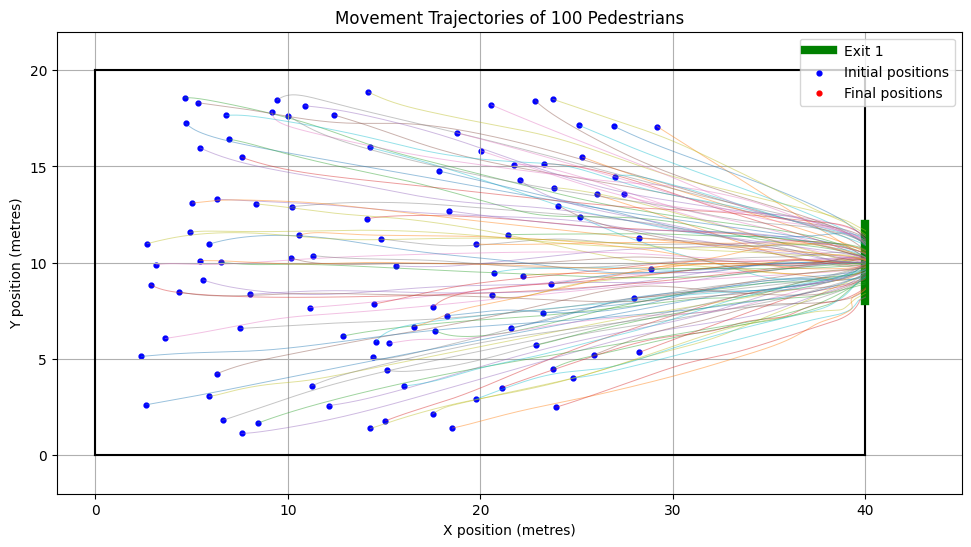

In [56]:
#Visualise all 100 pedestrian trajectories
# Convert movement history into a NumPy array

history_array = np.array(simulation_history)

# Create the graph
fig, ax = plt.subplots(figsize=(12, 6))

# Draw environment boundaries
ax.plot([0, WIDTH], [0, 0], color="black")
ax.plot([0, WIDTH], [HEIGHT, HEIGHT], color="black")
ax.plot([0, 0], [0, HEIGHT], color="black")

# Draw right boundary around the exit
ax.plot(
    [WIDTH, WIDTH],
    [0, EXIT_Y_MIN],
    color="black"
)

ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MAX, HEIGHT],
    color="black"
)

# Draw exit opening
ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MIN, EXIT_Y_MAX],
    color="green",
    linewidth=6,
    label="Exit 1"
)

# Draw pedestrian trajectories
for i in range(len(simulation_positions)):

    ax.plot(
        history_array[:, i, 0],
        history_array[:, i, 1],
        linewidth=0.7,
        alpha=0.45
    )

# Draw initial pedestrian positions
ax.scatter(
    history_array[0, :, 0],
    history_array[0, :, 1],
    color="blue",
    s=12,
    label="Initial positions"
)

# Draw final pedestrian positions
ax.scatter(
    history_array[-1, :, 0],
    history_array[-1, :, 1],
    color="red",
    s=12,
    label="Final positions"
)

ax.set_xlim(-2, WIDTH + 5)
ax.set_ylim(-2, HEIGHT + 2)

ax.set_xlabel("X position (metres)")
ax.set_ylabel("Y position (metres)")

ax.set_title("Movement Trajectories of 100 Pedestrians")

ax.set_aspect("equal")
ax.grid(True)
ax.legend()

plt.show()

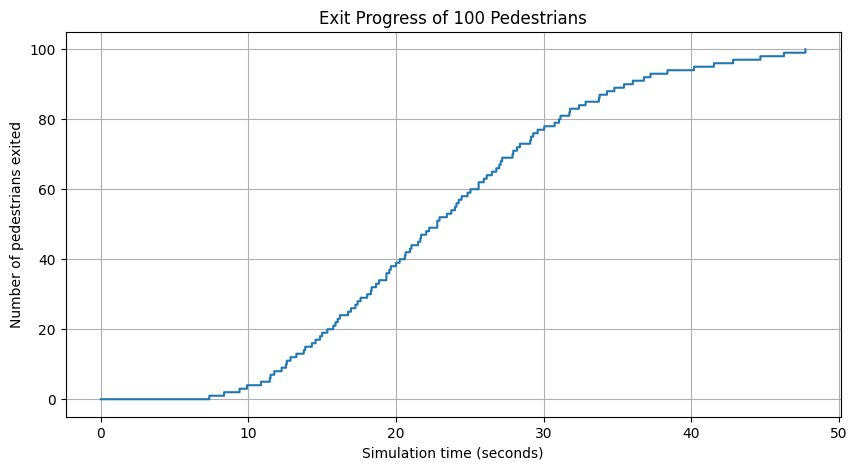

In [57]:
# Plot pedestrian exit progress

plt.figure(figsize=(10, 5))

plt.step(
    time_history,
    exit_count_history,
    where="post"
)

plt.xlabel("Simulation time (seconds)")
plt.ylabel("Number of pedestrians exited")

plt.title("Exit Progress of 100 Pedestrians")

plt.grid(True)

plt.show()

In [58]:
# Calculate total clearance time

if np.all(exited):

    clearance_time = np.max(exit_times)

    print("All pedestrians exited successfully.")

    print(
        "Total clearance time:",
        round(clearance_time, 2),
        "seconds"
    )

else:

    print("Not all pedestrians exited.")

    print("Pedestrians remaining:", np.sum(~exited))

    print("Total clearance time: Not reached")

All pedestrians exited successfully.
Total clearance time: 47.75 seconds


In [59]:
# Calculate T95

number_of_pedestrians = len(simulation_positions)

required_exits = int(
    np.ceil(0.95 * number_of_pedestrians)
)

# Find the first time when the required number exited
t95_indices = np.where(
    np.array(exit_count_history) >= required_exits
)[0]

if len(t95_indices) > 0:

    t95 = time_history[t95_indices[0]]

    print("T95 successfully calculated.")

    print("Required exits:", required_exits)

    print("T95:", round(t95, 2), "seconds")

else:

    print("T95 was not reached.")

    print("Required exits:", required_exits)

    print("Actual exits:", np.sum(exited))

T95 successfully calculated.
Required exits: 95
T95: 40.2 seconds


In [60]:
# Lesson 8: Simulation verification

history_array = np.array(simulation_history)

number_of_agents = len(simulation_positions)

# Check pedestrian count
assert number_of_agents == 100

# Check history dimensions
assert history_array.shape[1:] == (100, 2)

# Check all recorded positions are finite
assert np.all(np.isfinite(history_array))

# Check that exit count never decreases
assert np.all(
    np.diff(exit_count_history) >= 0
)

# Check exit count is within valid limits
assert np.all(
    np.array(exit_count_history) <= number_of_agents
)

# Check agent status conservation
assert (
    np.sum(exited) + np.sum(~exited)
    == number_of_agents
)

# Check active pedestrians remain within the environment
active_positions = simulation_positions[~exited]

if len(active_positions) > 0:

    assert np.all(active_positions[:, 0] >= simulation_radii[~exited])

    assert np.all(active_positions[:, 0] <= WIDTH - simulation_radii[~exited])

    assert np.all(active_positions[:, 1] >= simulation_radii[~exited])

    assert np.all(active_positions[:, 1] <= HEIGHT - simulation_radii[~exited])

# Check exited pedestrians have recorded exit times
assert np.all(np.isfinite(exit_times[exited]))

print("LESSON 8 VERIFICATION")
print("-----------------------------")
print("Pedestrian count: PASS")
print("Position history dimensions: PASS")
print("All recorded positions are finite: PASS")
print("Exit count is non-decreasing: PASS")
print("Exit count is within valid limits: PASS")
print("Agent status conservation: PASS")
print("Active pedestrian boundary check: PASS")
print("Exited pedestrian time records: PASS")

print("-----------------------------")
print("Total exited:", np.sum(exited))
print("Total remaining:", np.sum(~exited))

LESSON 8 VERIFICATION
-----------------------------
Pedestrian count: PASS
Position history dimensions: PASS
All recorded positions are finite: PASS
Exit count is non-decreasing: PASS
Exit count is within valid limits: PASS
Agent status conservation: PASS
Active pedestrian boundary check: PASS
Exited pedestrian time records: PASS
-----------------------------
Total exited: 100
Total remaining: 0


In [61]:
#Define our grid cells
# Lesson 9: Crowd Density Measurement

# Environment dimensions
WIDTH = 40
HEIGHT = 20

# Grid cell dimensions
CELL_WIDTH = 2.0
CELL_HEIGHT = 2.0

# Calculate number of cells
NUMBER_OF_X_CELLS = int(WIDTH / CELL_WIDTH)
NUMBER_OF_Y_CELLS = int(HEIGHT / CELL_HEIGHT)

# Calculate the area of one cell
CELL_AREA = CELL_WIDTH * CELL_HEIGHT

# Create cell boundaries
x_edges = np.arange(
    0,
    WIDTH + CELL_WIDTH,
    CELL_WIDTH
)

y_edges = np.arange(
    0,
    HEIGHT + CELL_HEIGHT,
    CELL_HEIGHT
)

print("GRID SETTINGS")
print("----------------------")
print("Environment:", WIDTH, "x", HEIGHT, "metres")
print("Cell width:", CELL_WIDTH, "metres")
print("Cell height:", CELL_HEIGHT, "metres")
print("Area of each cell:", CELL_AREA, "m²")
print("Number of columns:", NUMBER_OF_X_CELLS)
print("Number of rows:", NUMBER_OF_Y_CELLS)
print(
    "Total grid cells:",
    NUMBER_OF_X_CELLS * NUMBER_OF_Y_CELLS
)

GRID SETTINGS
----------------------
Environment: 40 x 20 metres
Cell width: 2.0 metres
Cell height: 2.0 metres
Area of each cell: 4.0 m²
Number of columns: 20
Number of rows: 10
Total grid cells: 200


In [62]:
# Function to calculate crowd density

def calculate_crowd_density(positions):

    # Count pedestrians inside each grid cell
    pedestrian_counts, _, _ = np.histogram2d(
        positions[:, 1],
        positions[:, 0],
        bins=[y_edges, x_edges]
    )

    # Calculate density in each cell
    density_grid = pedestrian_counts / CELL_AREA

    return density_grid, pedestrian_counts

In [63]:
# Calculate density at the beginning of the simulation

initial_positions = simulation_history[0]

initial_density, initial_counts = calculate_crowd_density(
    initial_positions
)

print("INITIAL CROWD DENSITY")
print("----------------------------")

print("Density grid shape:", initial_density.shape)

print("Total pedestrians counted:",
      int(np.sum(initial_counts)))

print("Maximum local density:",
      np.max(initial_density),
      "pedestrians/m²")

print("Number of occupied cells:",
      np.count_nonzero(initial_counts))

INITIAL CROWD DENSITY
----------------------------
Density grid shape: (10, 20)
Total pedestrians counted: 100
Maximum local density: 1.0 pedestrians/m²
Number of occupied cells: 75


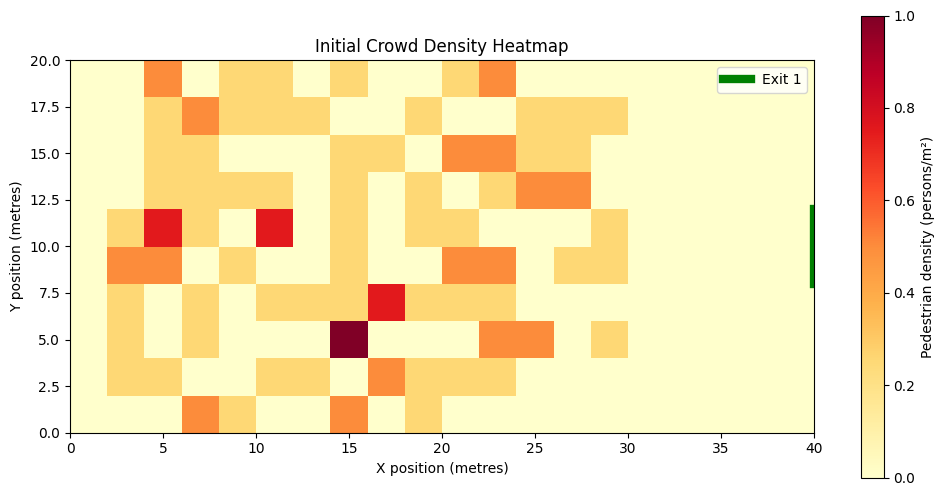

In [64]:
# Visualise initial crowd density

fig, ax = plt.subplots(figsize=(12, 6))

image = ax.imshow(
    initial_density,
    origin="lower",
    extent=[0, WIDTH, 0, HEIGHT],
    aspect="equal",
    cmap="YlOrRd",
    interpolation="nearest"
)

# Add colour bar
colour_bar = plt.colorbar(image, ax=ax)

colour_bar.set_label(
    "Pedestrian density (persons/m²)"
)

# Draw exit opening
ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MIN, EXIT_Y_MAX],
    color="green",
    linewidth=6,
    label="Exit 1"
)

ax.set_xlabel("X position (metres)")
ax.set_ylabel("Y position (metres)")

ax.set_title("Initial Crowd Density Heatmap")

ax.set_xlim(0, WIDTH)
ax.set_ylim(0, HEIGHT)

ax.legend()
plt.show()

In [65]:
# Calculate crowd density at every simulation time step

history_array = np.array(simulation_history)

density_history = []

maximum_density_history = []

average_occupied_density_history = []

high_density_area_history = []

# Illustrative analysis threshold, not a safety standard
HIGH_DENSITY_THRESHOLD = 1.0

for step in range(len(history_array)):

    current_time = time_history[step]

    # Identify pedestrians still inside at this time
    active_mask = (
        np.isnan(exit_times)
        | (exit_times > current_time + 1e-12)
    )

    # Get positions of active pedestrians only
    active_positions = history_array[step][active_mask]

    # Calculate density
    density_grid, counts_grid = calculate_crowd_density(
        active_positions
    )

    # Save density grid
    density_history.append(density_grid)

    # Maximum density in any cell
    maximum_density_history.append(
        np.max(density_grid)
    )

    # Average density of occupied cells
    occupied_cells = density_grid > 0

    if np.any(occupied_cells):

        average_density = np.mean(
            density_grid[occupied_cells]
        )

    else:

        average_density = 0.0

    average_occupied_density_history.append(
        average_density
    )

    # Calculate the fraction of area above our illustrative threshold
    high_density_cells = (
        density_grid >= HIGH_DENSITY_THRESHOLD
    )

    high_density_area_fraction = (
        np.sum(high_density_cells)
        * CELL_AREA
        / (WIDTH * HEIGHT)
    )

    high_density_area_history.append(
        high_density_area_fraction
    )


# Convert results into NumPy arrays
density_history = np.array(density_history)

maximum_density_history = np.array(
    maximum_density_history
)

average_occupied_density_history = np.array(
    average_occupied_density_history
)

high_density_area_history = np.array(
    high_density_area_history
)

print("Density calculation completed!")
print("Density history shape:", density_history.shape)
print("Number of recorded time steps:", len(density_history))

Density calculation completed!
Density history shape: (956, 10, 20)
Number of recorded time steps: 956


In [66]:
# Find the highest local crowd density

peak_step = np.argmax(maximum_density_history)

peak_time = time_history[peak_step]

peak_density = maximum_density_history[peak_step]

print("PEAK CROWD DENSITY")
print("----------------------------")

print("Time of peak density:", round(peak_time, 2), "seconds")

print("Maximum local density:",
      round(peak_density, 3),
      "pedestrians/m²")

print("Step number:", peak_step)

PEAK CROWD DENSITY
----------------------------
Time of peak density: 11.9 seconds
Maximum local density: 1.25 pedestrians/m²
Step number: 238


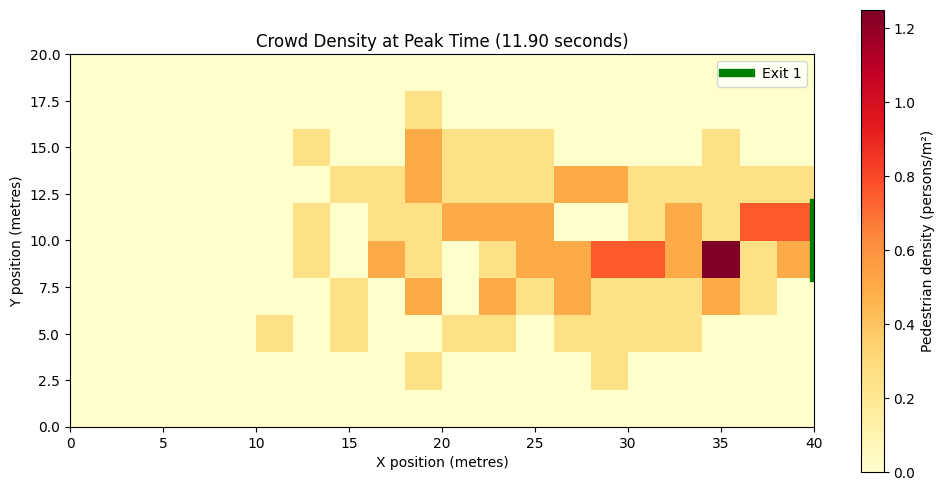

In [67]:
# Display the heatmap at the peak-density time

peak_density_grid = density_history[peak_step]

fig, ax = plt.subplots(figsize=(12, 6))

image = ax.imshow(
    peak_density_grid,
    origin="lower",
    extent=[0, WIDTH, 0, HEIGHT],
    aspect="equal",
    cmap="YlOrRd",
    interpolation="nearest"
)

colour_bar = plt.colorbar(image, ax=ax)

colour_bar.set_label(
    "Pedestrian density (persons/m²)"
)

# Draw exit opening
ax.plot(
    [WIDTH, WIDTH],
    [EXIT_Y_MIN, EXIT_Y_MAX],
    color="green",
    linewidth=6,
    label="Exit 1"
)

ax.set_xlabel("X position (metres)")
ax.set_ylabel("Y position (metres)")

ax.set_title(
    f"Crowd Density at Peak Time ({peak_time:.2f} seconds)"
)

ax.set_xlim(0, WIDTH)
ax.set_ylim(0, HEIGHT)

ax.legend()
plt.show()

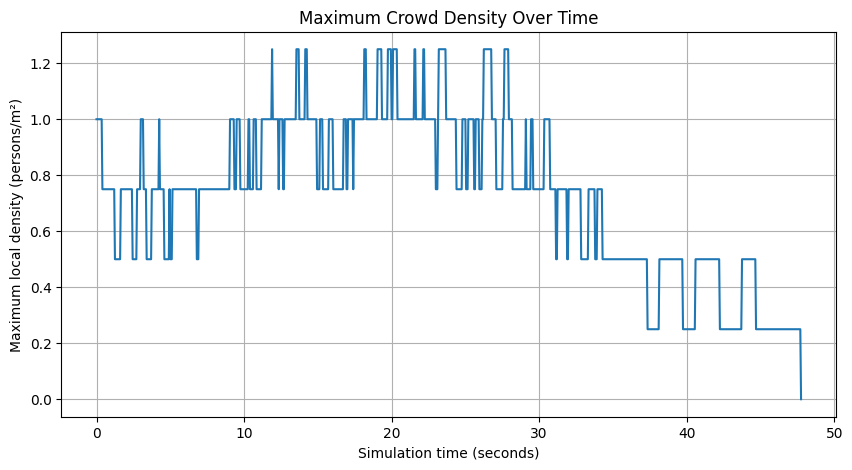

In [68]:
# Plot maximum local density over time

plt.figure(figsize=(10, 5))

plt.plot(
    time_history,
    maximum_density_history
)

plt.xlabel("Simulation time (seconds)")

plt.ylabel(
    "Maximum local density (persons/m²)"
)

plt.title("Maximum Crowd Density Over Time")

plt.grid(True)

plt.show()

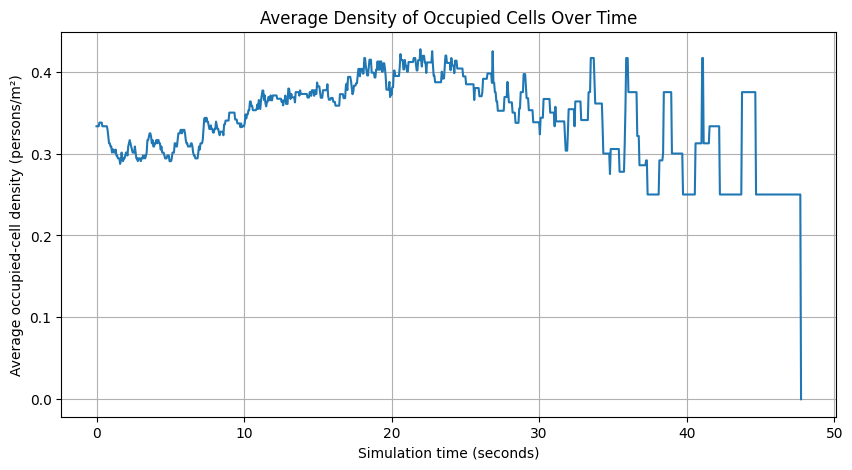

In [69]:
# Plot average density in occupied cells

plt.figure(figsize=(10, 5))

plt.plot(
    time_history,
    average_occupied_density_history
)

plt.xlabel("Simulation time (seconds)")

plt.ylabel(
    "Average occupied-cell density (persons/m²)"
)

plt.title("Average Density of Occupied Cells Over Time")

plt.grid(True)

plt.show()

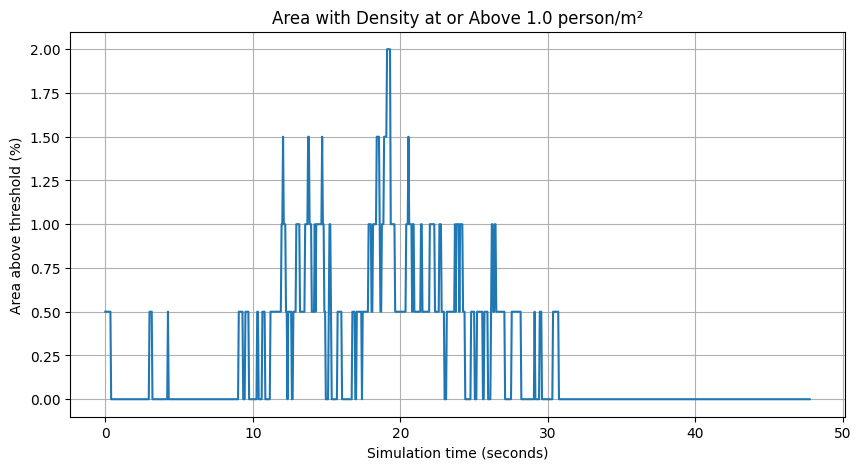

In [70]:
# Plot the fraction of the environment above the illustrative threshold

plt.figure(figsize=(10, 5))

plt.plot(
    time_history,
    high_density_area_history * 100
)

plt.xlabel("Simulation time (seconds)")

plt.ylabel("Area above threshold (%)")

plt.title(
    "Area with Density at or Above "
    f"{HIGH_DENSITY_THRESHOLD} person/m²"
)

plt.grid(True)

plt.show()

In [71]:
# Lesson 9: Crowd density verification

history_array = np.array(simulation_history)

# Check the dimensions of density history
assert density_history.shape == (
    len(history_array),
    NUMBER_OF_Y_CELLS,
    NUMBER_OF_X_CELLS
)

# Check all density values are finite
assert np.all(np.isfinite(density_history))

# Check density values are non-negative
assert np.all(density_history >= 0)

# Check the number of pedestrians counted in every time step
for step in range(len(history_array)):

    current_time = time_history[step]

    active_mask = (
        np.isnan(exit_times)
        | (exit_times > current_time + 1e-12)
    )

    active_positions = history_array[step][active_mask]

    density_grid, counts_grid = calculate_crowd_density(
        active_positions
    )

    # Density multiplied by cell area should equal pedestrian count
    estimated_count = np.sum(density_grid) * CELL_AREA

    actual_count = len(active_positions)

    assert np.isclose(
        estimated_count,
        actual_count
    )

# Check high-density area fractions
assert np.all(high_density_area_history >= 0)

assert np.all(high_density_area_history <= 1)

print("LESSON 9 VERIFICATION")
print("-----------------------------")
print("Density history dimensions: PASS")
print("All density values are finite: PASS")
print("Density values are non-negative: PASS")
print("Pedestrian counting consistency: PASS")
print("High-density area calculation: PASS")

print("-----------------------------")
print("Peak local density:",
      round(np.max(maximum_density_history), 3),
      "persons/m²")

print("Peak density time:",
      round(time_history[np.argmax(maximum_density_history)], 2),
      "seconds")

LESSON 9 VERIFICATION
-----------------------------
Density history dimensions: PASS
All density values are finite: PASS
Density values are non-negative: PASS
Pedestrian counting consistency: PASS
High-density area calculation: PASS
-----------------------------
Peak local density: 1.25 persons/m²
Peak density time: 11.9 seconds


In [72]:
# Lesson 10: Exit configuration experiments

# Environment dimensions
WIDTH = 40
HEIGHT = 20

# Define exit configurations as (lower_y, upper_y)
exit_scenarios = {

    "One Exit": [
        (8, 12)
    ],

    "Two Exits": [
        (4, 8),
        (12, 16)
    ],

    "Three Exits": [
        (2, 6),
        (8, 12),
        (14, 18)
    ]
}

# Simulation settings
dt = 0.05
total_steps = 2000

tau = 0.5

MAX_SPEED = 2.0
MAX_ACCELERATION = 4.0

# Grid settings for density measurement
CELL_WIDTH = 2.0
CELL_HEIGHT = 2.0
CELL_AREA = CELL_WIDTH * CELL_HEIGHT

x_edges = np.arange(0, WIDTH + CELL_WIDTH, CELL_WIDTH)
y_edges = np.arange(0, HEIGHT + CELL_HEIGHT, CELL_HEIGHT)

print("EXIT CONFIGURATIONS")
print("----------------------------")

for name, exits in exit_scenarios.items():

    print(name, ":", len(exits), "exit(s)")
    print("Exit locations:", exits)

EXIT CONFIGURATIONS
----------------------------
One Exit : 1 exit(s)
Exit locations: [(8, 12)]
Two Exits : 2 exit(s)
Exit locations: [(4, 8), (12, 16)]
Three Exits : 3 exit(s)
Exit locations: [(2, 6), (8, 12), (14, 18)]


In [73]:
# Calculate desired acceleration towards the nearest exit

def calculate_multi_exit_desired_acceleration(
    positions,
    velocities,
    desired_speeds,
    exits
):

    # Calculate the centre point of each exit
    exit_centres = np.array([
        [WIDTH, (lower + upper) / 2]
        for lower, upper in exits
    ])

    # Calculate distances from each pedestrian to each exit centre
    differences = (
        exit_centres[np.newaxis, :, :]
        - positions[:, np.newaxis, :]
    )

    distances = np.linalg.norm(
        differences,
        axis=2
    )

    # Find the nearest exit for each pedestrian
    nearest_exit_indices = np.argmin(
        distances,
        axis=1
    )

    # Select the nearest exit target
    nearest_targets = exit_centres[nearest_exit_indices]

    # Calculate direction towards the selected exit
    directions = nearest_targets - positions

    direction_lengths = np.linalg.norm(
        directions,
        axis=1,
        keepdims=True
    )

    direction_lengths = np.maximum(
        direction_lengths,
        1e-12
    )

    desired_directions = directions / direction_lengths

    # Calculate individual desired velocities
    desired_velocities = (
        desired_speeds[:, np.newaxis]
        * desired_directions
    )

    # Calculate desired acceleration
    desired_accelerations = (
        desired_velocities - velocities
    ) / tau

    return desired_accelerations, nearest_exit_indices

In [74]:
# Calculate pedestrian interactions

def calculate_multi_exit_pedestrian_interactions(
    positions,
    radii
):

    differences = (
        positions[:, np.newaxis, :]
        - positions[np.newaxis, :, :]
    )

    distances = np.linalg.norm(
        differences,
        axis=2
    )

    # Avoid self-interaction
    np.fill_diagonal(distances, np.inf)

    safe_distances = np.where(
        np.isfinite(distances),
        distances,
        1.0
    )

    directions = (
        differences / safe_distances[:, :, np.newaxis]
    )

    A = 2.0
    B = 0.5

    combined_radii = (
        radii[:, np.newaxis]
        + radii[np.newaxis, :]
    )

    strengths = A * np.exp(
        (combined_radii - distances) / B
    )

    np.fill_diagonal(strengths, 0.0)

    interaction_accelerations = np.sum(
        strengths[:, :, np.newaxis] * directions,
        axis=1
    )

    return interaction_accelerations

In [75]:
# Calculate wall interactions for different exit configurations

def calculate_multi_exit_wall_interactions(
    positions,
    radii,
    exits
):

    A_wall = 2.0
    B_wall = 0.5

    wall_accelerations = np.zeros_like(positions)

    x = positions[:, 0]
    y = positions[:, 1]

    # Left wall
    left_strength = A_wall * np.exp(
        (radii - x) / B_wall
    )

    wall_accelerations[:, 0] += left_strength

    # Bottom wall
    bottom_strength = A_wall * np.exp(
        (radii - y) / B_wall
    )

    wall_accelerations[:, 1] += bottom_strength

    # Top wall
    top_strength = A_wall * np.exp(
        (radii - (HEIGHT - y)) / B_wall
    )

    wall_accelerations[:, 1] -= top_strength

    # Identify pedestrians outside all exit openings
    in_any_exit = np.zeros(len(positions), dtype=bool)

    for lower, upper in exits:

        in_this_exit = (
            (y >= lower) & (y <= upper)
        )

        in_any_exit |= in_this_exit

    # Right wall repels pedestrians outside exit openings
    blocked_right = ~in_any_exit

    right_strength = A_wall * np.exp(
        (radii - (WIDTH - x)) / B_wall
    )

    wall_accelerations[blocked_right, 0] -= (
        right_strength[blocked_right]
    )

    return wall_accelerations

In [76]:
# Test multi-exit acceleration calculations

test_positions = crowd_positions[:5].copy()

test_velocities = crowd_velocities[:5].copy()

test_speeds = crowd_desired_speeds[:5].copy()

test_radii = crowd_radii[:5].copy()

# Use the three-exit configuration for testing
test_exits = exit_scenarios["Three Exits"]

# Desired acceleration
test_desired_acc, test_exit_choices = (
    calculate_multi_exit_desired_acceleration(
        test_positions,
        test_velocities,
        test_speeds,
        test_exits
    )
)

# Pedestrian interactions
test_pedestrian_acc = (
    calculate_multi_exit_pedestrian_interactions(
        test_positions,
        test_radii
    )
)

# Wall interactions
test_wall_acc = (
    calculate_multi_exit_wall_interactions(
        test_positions,
        test_radii,
        test_exits
    )
)

# Total acceleration
test_total_acc = (
    test_desired_acc
    + test_pedestrian_acc
    + test_wall_acc
)

print("MULTI-EXIT ACCELERATION TEST")
print("-----------------------------")

print("Desired acceleration:", test_desired_acc.shape)
print("Pedestrian interaction:", test_pedestrian_acc.shape)
print("Wall interaction:", test_wall_acc.shape)
print("Total acceleration:", test_total_acc.shape)

print("\nSelected exit for each test pedestrian:")

for i, exit_index in enumerate(test_exit_choices):

    print(
        f"Pedestrian {i + 1}: Exit {exit_index + 1}"
    )

MULTI-EXIT ACCELERATION TEST
-----------------------------
Desired acceleration: (5, 2)
Pedestrian interaction: (5, 2)
Wall interaction: (5, 2)
Total acceleration: (5, 2)

Selected exit for each test pedestrian:
Pedestrian 1: Exit 2
Pedestrian 2: Exit 3
Pedestrian 3: Exit 3
Pedestrian 4: Exit 3
Pedestrian 5: Exit 2


In [77]:

# Lesson 10: Run one pedestrian dispersal scenario

def run_exit_scenario(exits):

    # Start with the same original crowd for every scenario
    positions = crowd_positions.copy()
    velocities = crowd_velocities.copy()
    desired_speeds = crowd_desired_speeds.copy()
    radii = crowd_radii.copy()

    number_of_agents = len(positions)

    # Track pedestrian exit status
    exited = np.zeros(number_of_agents, dtype=bool)

    exit_times = np.full(number_of_agents, np.nan)

    # Track which exit each pedestrian actually uses
    exit_used = np.full(number_of_agents, -1, dtype=int)

    # Store simulation history
    exit_count_history = [0]
    time_history = [0.0]

    maximum_density_history = []

    # Calculate initial density
    initial_counts, _, _ = np.histogram2d(
        positions[:, 1],
        positions[:, 0],
        bins=[y_edges, x_edges]
    )

    initial_density = initial_counts / CELL_AREA

    maximum_density_history.append(
        np.max(initial_density)
    )

    # Run the simulation
    for step in range(total_steps):

        # Find pedestrians who have not exited
        active_indices = np.where(~exited)[0]

        # Stop if everyone has exited
        if len(active_indices) == 0:
            break

        # Get information about active pedestrians
        active_positions = positions[active_indices]
        active_velocities = velocities[active_indices]
        active_speeds = desired_speeds[active_indices]
        active_radii = radii[active_indices]

        # 1. Calculate desired acceleration
        desired_acc, selected_exits = (
            calculate_multi_exit_desired_acceleration(
                active_positions,
                active_velocities,
                active_speeds,
                exits
            )
        )

        # 2. Calculate pedestrian interactions
        pedestrian_acc = (
            calculate_multi_exit_pedestrian_interactions(
                active_positions,
                active_radii
            )
        )

        # 3. Calculate wall interactions
        wall_acc = calculate_multi_exit_wall_interactions(
            active_positions,
            active_radii,
            exits
        )

        # 4. Combine all acceleration components
        total_acc = (
            desired_acc
            + pedestrian_acc
            + wall_acc
        )

        # Limit maximum acceleration
        acceleration_magnitudes = np.linalg.norm(
            total_acc,
            axis=1
        )

        acceleration_scales = np.minimum(
            1.0,
            MAX_ACCELERATION / np.maximum(
                acceleration_magnitudes,
                1e-12
            )
        )

        total_acc *= acceleration_scales[:, np.newaxis]

        # 5. Update velocity
        new_velocities = (
            active_velocities + total_acc * dt
        )

        # Limit maximum speed
        speed_magnitudes = np.linalg.norm(
            new_velocities,
            axis=1
        )

        speed_scales = np.minimum(
            1.0,
            MAX_SPEED / np.maximum(
                speed_magnitudes,
                1e-12
            )
        )

        new_velocities *= speed_scales[:, np.newaxis]

        # 6. Update positions using old velocities
        new_positions = (
            active_positions + active_velocities * dt
        )

        # Check exits and environment boundaries
        for local_index, agent_index in enumerate(active_indices):

            x = new_positions[local_index, 0]
            y = new_positions[local_index, 1]

            radius = radii[agent_index]

            # Find the actual exit opening crossed
            actual_exit_index = next(
                (
                    j for j, (lower, upper) in enumerate(exits)
                    if lower <= y <= upper
                ),
                None
            )

            # Check whether the pedestrian crossed an exit
            if x >= WIDTH and actual_exit_index is not None:

                exited[agent_index] = True

                exit_times[agent_index] = (step + 1) * dt

                exit_used[agent_index] = actual_exit_index

                positions[agent_index] = [WIDTH, y]

                velocities[agent_index] = [0.0, 0.0]

            else:

                # Left boundary
                if x < radius:
                    x = radius

                    new_velocities[local_index, 0] = max(
                        0.0,
                        new_velocities[local_index, 0]
                    )

                # Bottom boundary
                if y < radius:
                    y = radius

                    new_velocities[local_index, 1] = max(
                        0.0,
                        new_velocities[local_index, 1]
                    )

                # Top boundary
                if y > HEIGHT - radius:
                    y = HEIGHT - radius

                    new_velocities[local_index, 1] = min(
                        0.0,
                        new_velocities[local_index, 1]
                    )

                # Check whether pedestrian is inside any exit opening
                in_any_exit = any(
                    lower <= y <= upper
                    for lower, upper in exits
                )

                # Solid right-hand wall
                if not in_any_exit and x > WIDTH - radius:
                    x = WIDTH - radius

                    new_velocities[local_index, 0] = min(
                        0.0,
                        new_velocities[local_index, 0]
                    )

                # Save updated position and velocity
                positions[agent_index] = [x, y]

                velocities[agent_index] = (
                    new_velocities[local_index]
                )

        # 7. Store exit progress
        current_time = (step + 1) * dt

        exit_count_history.append(
            int(np.sum(exited))
        )

        time_history.append(current_time)

        # 8. Calculate density of pedestrians still inside
        active_positions_after_update = positions[~exited]

        if len(active_positions_after_update) > 0:

            counts, _, _ = np.histogram2d(
                active_positions_after_update[:, 1],
                active_positions_after_update[:, 0],
                bins=[y_edges, x_edges]
            )

            density_grid = counts / CELL_AREA

            maximum_density_history.append(
                np.max(density_grid)
            )

        else:

            maximum_density_history.append(0.0)

    # 9. Calculate T95
    required_exits = int(
        np.ceil(0.95 * number_of_agents)
    )

    t95_indices = np.where(
        np.array(exit_count_history) >= required_exits
    )[0]

    if len(t95_indices) > 0:
        t95 = time_history[t95_indices[0]]
    else:
        t95 = np.nan

    # 10. Calculate total clearance time
    if np.all(exited):
        clearance_time = np.max(exit_times)
    else:
        clearance_time = np.nan

    # 11. Count pedestrians using each exit
    exit_utilisation = np.bincount(
        exit_used[exit_used >= 0],
        minlength=len(exits)
    )

    # 12. Return all simulation results
    return {
        "exits": exits,
        "positions": positions,
        "velocities": velocities,
        "exited": exited,
        "exit_times": exit_times,
        "exit_used": exit_used,
        "exit_utilisation": exit_utilisation,
        "exit_count_history": np.array(exit_count_history),
        "time_history": np.array(time_history),
        "maximum_density_history": np.array(
            maximum_density_history
        ),
        "t95": t95,
        "clearance_time": clearance_time,
        "peak_density": np.max(maximum_density_history),
        "peak_density_time": time_history[
            np.argmax(maximum_density_history)
        ]
    }


print("Corrected multi-exit simulation function created successfully!")


Corrected multi-exit simulation function created successfully!


In [78]:
# Scenario A: One exit

scenario_A_results = run_exit_scenario(
    exit_scenarios["One Exit"]
)

print("SCENARIO A - ONE EXIT")
print("-----------------------------")

print("Total pedestrians:", len(crowd_positions))

print(
    "Exited:",
    np.sum(scenario_A_results["exited"])
)

print(
    "Remaining:",
    np.sum(~scenario_A_results["exited"])
)

print(
    "T95:",
    scenario_A_results["t95"]
)

print(
    "Clearance time:",
    scenario_A_results["clearance_time"]
)

print(
    "Peak local density:",
    scenario_A_results["peak_density"],
    "persons/m²"
)

SCENARIO A - ONE EXIT
-----------------------------
Total pedestrians: 100
Exited: 100
Remaining: 0
T95: 40.2
Clearance time: 47.75
Peak local density: 1.25 persons/m²


In [79]:
# Scenario B: Two exits

scenario_B_results = run_exit_scenario(
    exit_scenarios["Two Exits"]
)

print("SCENARIO B - TWO EXITS")
print("-----------------------------")

print("Total pedestrians:", len(crowd_positions))

print(
    "Exited:",
    np.sum(scenario_B_results["exited"])
)

print(
    "Remaining:",
    np.sum(~scenario_B_results["exited"])
)

print(
    "T95:",
    scenario_B_results["t95"]
)

print(
    "Clearance time:",
    scenario_B_results["clearance_time"]
)

print(
    "Peak local density:",
    scenario_B_results["peak_density"],
    "persons/m²"
)

SCENARIO B - TWO EXITS
-----------------------------
Total pedestrians: 100
Exited: 100
Remaining: 0
T95: 40.2
Clearance time: 46.550000000000004
Peak local density: 1.0 persons/m²


In [80]:
# Scenario C: Three exits

scenario_C_results = run_exit_scenario(
    exit_scenarios["Three Exits"]
)

print("SCENARIO C - THREE EXITS")
print("-----------------------------")

print("Total pedestrians:", len(crowd_positions))

print(
    "Exited:",
    np.sum(scenario_C_results["exited"])
)

print(
    "Remaining:",
    np.sum(~scenario_C_results["exited"])
)

print(
    "T95:",
    scenario_C_results["t95"]
)

print(
    "Clearance time:",
    scenario_C_results["clearance_time"]
)

print(
    "Peak local density:",
    scenario_C_results["peak_density"],
    "persons/m²"
)

SCENARIO C - THREE EXITS
-----------------------------
Total pedestrians: 100
Exited: 100
Remaining: 0
T95: 39.85
Clearance time: 45.2
Peak local density: 1.0 persons/m²


In [81]:
# Compare the three exit scenarios

scenario_results = {
    "One Exit": scenario_A_results,
    "Two Exits": scenario_B_results,
    "Three Exits": scenario_C_results
}

print("SCENARIO COMPARISON")
print("------------------------------------------------")

print(
    f"{'Scenario':<15}"
    f"{'Exited':<10}"
    f"{'T95 (s)':<12}"
    f"{'Clearance (s)':<16}"
    f"{'Peak density':<15}"
)

print("------------------------------------------------")

for name, result in scenario_results.items():

    exited_count = np.sum(result["exited"])

    t95 = result["t95"]
    clearance = result["clearance_time"]
    peak_density = result["peak_density"]

    t95_text = (
        f"{t95:.2f}" if np.isfinite(t95) else "Not reached"
    )

    clearance_text = (
        f"{clearance:.2f}"
        if np.isfinite(clearance)
        else "Not reached"
    )

    print(
        f"{name:<15}"
        f"{exited_count:<10}"
        f"{t95_text:<12}"
        f"{clearance_text:<16}"
        f"{peak_density:<15.3f}"
    )

SCENARIO COMPARISON
------------------------------------------------
Scenario       Exited    T95 (s)     Clearance (s)   Peak density   
------------------------------------------------
One Exit       100       40.20       47.75           1.250          
Two Exits      100       40.20       46.55           1.000          
Three Exits    100       39.85       45.20           1.000          


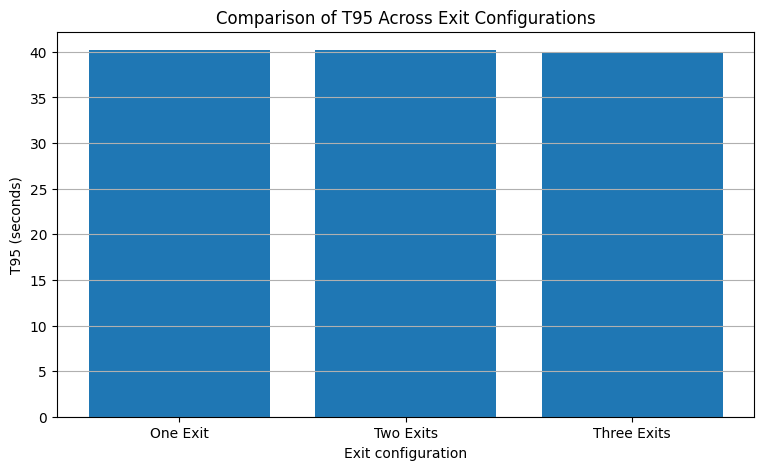

In [82]:
# Compare T95 between scenarios

scenario_names = list(scenario_results.keys())

t95_values = [
    scenario_results[name]["t95"]
    for name in scenario_names
]

plt.figure(figsize=(9, 5))

plt.bar(
    scenario_names,
    t95_values
)

plt.xlabel("Exit configuration")

plt.ylabel("T95 (seconds)")

plt.title("Comparison of T95 Across Exit Configurations")

plt.grid(axis="y")

plt.show()

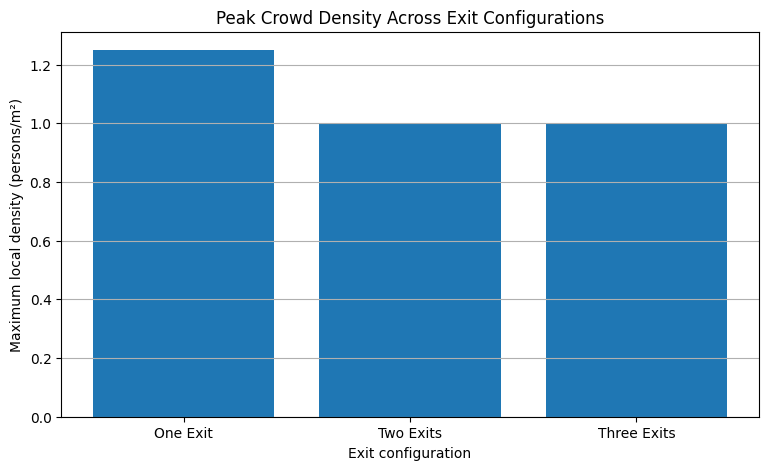

In [83]:
# Compare peak crowd density

peak_density_values = [
    scenario_results[name]["peak_density"]
    for name in scenario_names
]

plt.figure(figsize=(9, 5))

plt.bar(
    scenario_names,
    peak_density_values
)

plt.xlabel("Exit configuration")

plt.ylabel("Maximum local density (persons/m²)")

plt.title("Peak Crowd Density Across Exit Configurations")

plt.grid(axis="y")

plt.show()

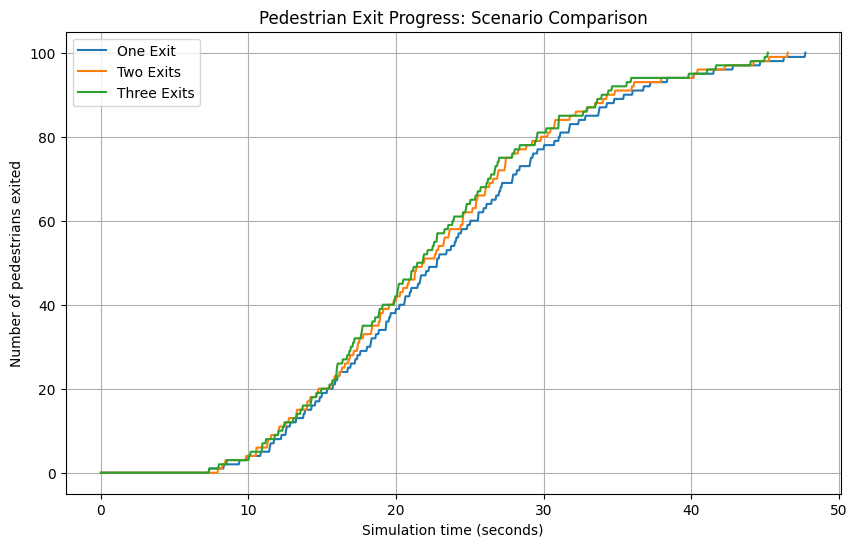

In [84]:
# Compare pedestrian exit progress

plt.figure(figsize=(10, 6))

for name, result in scenario_results.items():

    plt.plot(
        result["time_history"],
        result["exit_count_history"],
        label=name
    )

plt.xlabel("Simulation time (seconds)")

plt.ylabel("Number of pedestrians exited")

plt.title("Pedestrian Exit Progress: Scenario Comparison")

plt.legend()

plt.grid(True)

plt.show()

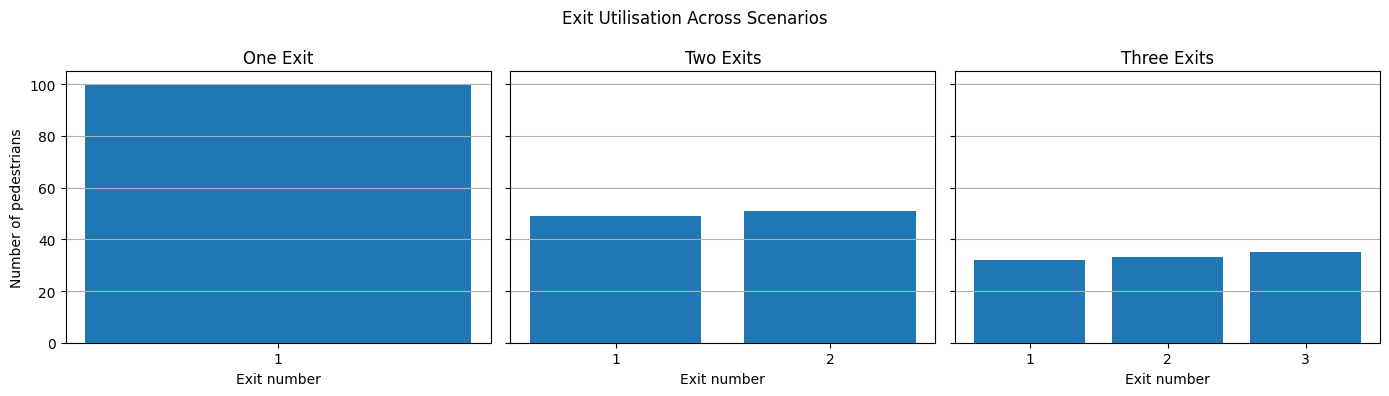

In [85]:
# Compare how many pedestrians used each exit

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4),
    sharey=True
)

for ax, (name, result) in zip(
    axes,
    scenario_results.items()
):

    exit_numbers = np.arange(
        1,
        len(result["exit_utilisation"]) + 1
    )

    ax.bar(
        exit_numbers,
        result["exit_utilisation"]
    )

    ax.set_title(name)
    ax.set_xlabel("Exit number")
    ax.set_xticks(exit_numbers)
    ax.grid(axis="y")

axes[0].set_ylabel("Number of pedestrians")

fig.suptitle("Exit Utilisation Across Scenarios")

plt.tight_layout()
plt.show()

In [86]:
# Lesson 10: Scenario verification

for name, result in scenario_results.items():

    print("\n", name)
    print("-----------------------------")

    number_of_agents = len(crowd_positions)

    # Check pedestrian count
    assert len(result["exited"]) == number_of_agents

    # Check all final positions are finite
    assert np.all(np.isfinite(result["positions"]))

    # Check exit count never decreases
    assert np.all(
        np.diff(result["exit_count_history"]) >= 0
    )

    # Check exit count is within valid limits
    assert np.all(
        result["exit_count_history"] <= number_of_agents
    )

    # Check agent status conservation
    assert (
        np.sum(result["exited"])
        + np.sum(~result["exited"])
        == number_of_agents
    )

    # Check exit-time records
    assert np.all(
        np.isfinite(result["exit_times"][result["exited"]])
    )

    assert np.all(
        np.isnan(result["exit_times"][~result["exited"]])
    )

    # Check exit utilisation
    assert (
        np.sum(result["exit_utilisation"])
        == np.sum(result["exited"])
    )

    # Check density values
    assert np.all(
        np.isfinite(result["maximum_density_history"])
    )

    assert np.all(
        result["maximum_density_history"] >= 0
    )

    print("Pedestrian count: PASS")
    print("Position values: PASS")
    print("Exit progress: PASS")
    print("Agent status conservation: PASS")
    print("Exit-time records: PASS")
    print("Exit utilisation: PASS")
    print("Density values: PASS")

print("\nALL SCENARIO VERIFICATION CHECKS COMPLETED")


 One Exit
-----------------------------
Pedestrian count: PASS
Position values: PASS
Exit progress: PASS
Agent status conservation: PASS
Exit-time records: PASS
Exit utilisation: PASS
Density values: PASS

 Two Exits
-----------------------------
Pedestrian count: PASS
Position values: PASS
Exit progress: PASS
Agent status conservation: PASS
Exit-time records: PASS
Exit utilisation: PASS
Density values: PASS

 Three Exits
-----------------------------
Pedestrian count: PASS
Position values: PASS
Exit progress: PASS
Agent status conservation: PASS
Exit-time records: PASS
Exit utilisation: PASS
Density values: PASS

ALL SCENARIO VERIFICATION CHECKS COMPLETED


In [87]:
# Calculate T95 improvement compared with one exit

baseline_t95 = scenario_A_results["t95"]

print("T95 IMPROVEMENT")
print("-----------------------------")

if np.isfinite(baseline_t95) and baseline_t95 > 0:

    for name, result in scenario_results.items():

        scenario_t95 = result["t95"]

        if np.isfinite(scenario_t95):

            improvement = (
                (baseline_t95 - scenario_t95)
                / baseline_t95
            ) * 100

            print(
                name,
                ":",
                round(improvement, 2),
                "%"
            )

        else:

            print(name, ": T95 not reached")

else:

    print("Baseline T95 was not reached.")
    print("Percentage improvement cannot be calculated.")

T95 IMPROVEMENT
-----------------------------
One Exit : 0.0 %
Two Exits : 0.0 %
Three Exits : 0.87 %


In [88]:
# Lesson 11: Save the original Lesson 7 crowd

lesson7_original_positions = crowd_positions.copy()

lesson7_original_velocities = crowd_velocities.copy()

lesson7_original_speeds = crowd_desired_speeds.copy()

lesson7_original_radii = crowd_radii.copy()

print("Original Lesson 7 crowd saved successfully!")

print("Number of pedestrians:",
      len(lesson7_original_positions))

Original Lesson 7 crowd saved successfully!
Number of pedestrians: 100


In [89]:
# Generate a new random crowd for Monte Carlo experiments

def generate_random_crowd(seed, number_of_agents=100):

    # Create a random number generator
    rng = np.random.default_rng(seed)

    # Set pedestrian parameters
    pedestrian_radius = 0.3
    minimum_separation = 0.65

    # Create empty position array
    positions = np.zeros((number_of_agents, 2))

    # Generate pedestrian positions
    for i in range(number_of_agents):

        placed = False

        # Try to find a valid position
        for attempt in range(10000):

            # Generate positions inside the smaller spectator region
            candidate = np.array([
                rng.uniform(
                    START_X_MIN,
                    START_X_MAX
                ),

                rng.uniform(
                    START_Y_MIN,
                    START_Y_MAX
                )
            ])

            # Check distance from existing pedestrians
            if i == 0:

                positions[i] = candidate
                placed = True
                break

            distances = np.linalg.norm(
                positions[:i] - candidate,
                axis=1
            )

            if np.all(distances >= minimum_separation):

                positions[i] = candidate
                placed = True
                break

        if not placed:

            raise RuntimeError(
                "Could not place pedestrian. "
                "Try increasing the environment size."
            )

    # Generate individual walking speeds
    desired_speeds = rng.uniform(
        0.8,
        1.6,
        number_of_agents
    )

    # Initial velocities are zero
    velocities = np.zeros(
        (number_of_agents, 2)
    )

    # Give every pedestrian the same assumed radius
    radii = np.full(
        number_of_agents,
        pedestrian_radius
    )

    return positions, velocities, desired_speeds, radii


print("Random crowd generator created successfully!")




Random crowd generator created successfully!


In [90]:
# Test the corrected random crowd generator

test_positions, test_velocities, test_speeds, test_radii = (
    generate_random_crowd(seed=1234, number_of_agents=100)
)

print("Number of pedestrians:", len(test_positions))

print("First five pedestrian positions:")
print(test_positions[:5])

print("\nMinimum X:", np.min(test_positions[:, 0]))
print("Maximum X:", np.max(test_positions[:, 0]))

print("Minimum Y:", np.min(test_positions[:, 1]))
print("Maximum Y:", np.max(test_positions[:, 1]))

print("\nMinimum pedestrian separation:")

distances = []

for i in range(len(test_positions)):
    for j in range(i + 1, len(test_positions)):
        distances.append(
            np.linalg.norm(test_positions[i] - test_positions[j])
        )

print(min(distances), "metres")

Number of pedestrians: 100
First five pedestrian positions:
[[29.34759347  7.84352323]
 [27.85089455  5.71046363]
 [10.93471764  3.12564219]
 [ 8.76945621  6.73361072]
 [28.99421886  5.74569648]]

Minimum X: 2.0877040488192216
Maximum X: 29.76196389101252
Minimum Y: 1.0372793812493257
Maximum Y: 18.860666130777144

Minimum pedestrian separation:
0.6523937804344762 metres


In [91]:
# Test the random crowd generator

test_positions, test_velocities, test_speeds, test_radii = (
    generate_random_crowd(seed=101)
)

print("RANDOM CROWD TEST")
print("-----------------------------")

print("Number of pedestrians:", len(test_positions))

print("Position array shape:", test_positions.shape)

print("Velocity array shape:", test_velocities.shape)

print("Walking speed array shape:", test_speeds.shape)

print("Radius array shape:", test_radii.shape)

# Calculate minimum pedestrian separation
differences = (
    test_positions[:, np.newaxis, :]
    - test_positions[np.newaxis, :, :]
)

distances = np.linalg.norm(
    differences,
    axis=2
)

np.fill_diagonal(distances, np.inf)

minimum_distance = np.min(distances)

print("Minimum pedestrian separation:",
      round(minimum_distance, 4),
      "metres")

print("Minimum walking speed:",
      round(np.min(test_speeds), 3),
      "m/s")

print("Maximum walking speed:",
      round(np.max(test_speeds), 3),
      "m/s")

RANDOM CROWD TEST
-----------------------------
Number of pedestrians: 100
Position array shape: (100, 2)
Velocity array shape: (100, 2)
Walking speed array shape: (100,)
Radius array shape: (100,)
Minimum pedestrian separation: 0.654 metres
Minimum walking speed: 0.802 m/s
Maximum walking speed: 1.59 m/s


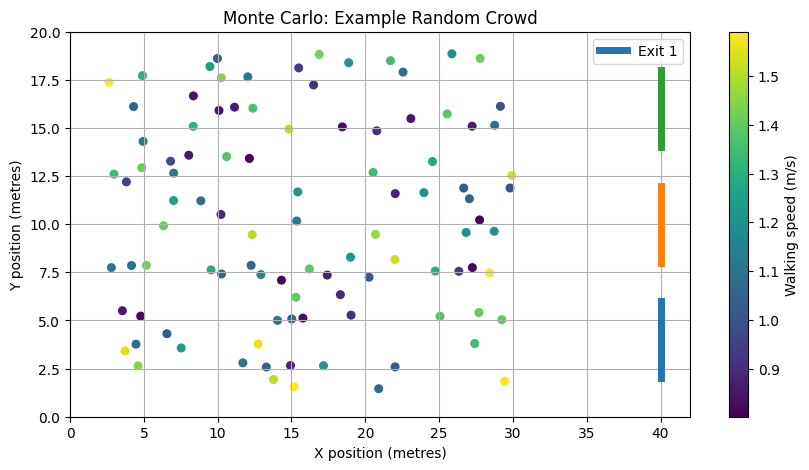

In [92]:
# Visualise the generated random crowd

plt.figure(figsize=(10, 5))

scatter = plt.scatter(
    test_positions[:, 0],
    test_positions[:, 1],
    c=test_speeds,
    cmap="viridis",
    s=30
)

# Draw exit locations for reference
for i, (lower, upper) in enumerate(
    exit_scenarios["Three Exits"]
):

    plt.plot(
        [WIDTH, WIDTH],
        [lower, upper],
        linewidth=5,
        label=f"Exit {i + 1}" if i == 0 else None
    )

colour_bar = plt.colorbar(scatter)

colour_bar.set_label("Walking speed (m/s)")

plt.xlim(0, WIDTH + 2)
plt.ylim(0, HEIGHT)

plt.xlabel("X position (metres)")
plt.ylabel("Y position (metres)")

plt.title("Monte Carlo: Example Random Crowd")

plt.grid(True)
plt.legend()
plt.show()

In [93]:
# Monte Carlo experiment settings

BASE_SEED = 1000

# Start with 5 runs to test the experiment
N_REPLICATIONS = 30  #N_REPLICATIONS = 5 - initial

# Store the three exit configurations
monte_carlo_scenarios = {
    "One Exit": exit_scenarios["One Exit"],
    "Two Exits": exit_scenarios["Two Exits"],
    "Three Exits": exit_scenarios["Three Exits"]
}

# Create empty result storage
monte_carlo_results = {
    name: []
    for name in monte_carlo_scenarios
}

print("MONTE CARLO SETTINGS")
print("-----------------------------")

print("Number of replications:", N_REPLICATIONS)

print("Number of scenarios:", len(monte_carlo_scenarios))

print(
    "Total simulations:",
    N_REPLICATIONS * len(monte_carlo_scenarios)
)

MONTE CARLO SETTINGS
-----------------------------
Number of replications: 30
Number of scenarios: 3
Total simulations: 90


In [94]:
# Run Monte Carlo experiments

for replication in range(N_REPLICATIONS):

    print(
        f"\nStarting replication "
        f"{replication + 1}/{N_REPLICATIONS}"
    )

    # Generate a new random crowd
    positions, velocities, speeds, radii = (
        generate_random_crowd(
            seed=BASE_SEED + replication
        )
    )

    # Use this same crowd for all three scenarios
    crowd_positions = positions.copy()

    crowd_velocities = velocities.copy()

    crowd_desired_speeds = speeds.copy()

    crowd_radii = radii.copy()

    # Run each exit configuration
    for scenario_name, exits in monte_carlo_scenarios.items():

        print("Running:", scenario_name)

        result = run_exit_scenario(exits)

        # Save the result
        monte_carlo_results[scenario_name].append({
            "replication": replication + 1,
            "seed": BASE_SEED + replication,
            "t95": result["t95"],
            "clearance_time": result["clearance_time"],
            "peak_density": result["peak_density"],
            "exited": int(np.sum(result["exited"])),
            "remaining": int(np.sum(~result["exited"])),
            "exit_utilisation": result["exit_utilisation"].copy()
        })

    print(
        f"Replication {replication + 1} completed."
    )

print("\nALL MONTE CARLO EXPERIMENTS COMPLETED!")


Starting replication 1/30
Running: One Exit
Running: Two Exits
Running: Three Exits
Replication 1 completed.

Starting replication 2/30
Running: One Exit
Running: Two Exits
Running: Three Exits
Replication 2 completed.

Starting replication 3/30
Running: One Exit
Running: Two Exits
Running: Three Exits
Replication 3 completed.

Starting replication 4/30
Running: One Exit
Running: Two Exits
Running: Three Exits
Replication 4 completed.

Starting replication 5/30
Running: One Exit
Running: Two Exits
Running: Three Exits
Replication 5 completed.

Starting replication 6/30
Running: One Exit
Running: Two Exits
Running: Three Exits
Replication 6 completed.

Starting replication 7/30
Running: One Exit
Running: Two Exits
Running: Three Exits
Replication 7 completed.

Starting replication 8/30
Running: One Exit
Running: Two Exits
Running: Three Exits
Replication 8 completed.

Starting replication 9/30
Running: One Exit
Running: Two Exits
Running: Three Exits
Replication 9 completed.

Starting 

In [95]:
# Display individual Monte Carlo results

import pandas as pd

all_results = []

for scenario_name, results in monte_carlo_results.items():

    for result in results:

        all_results.append({
            "Scenario": scenario_name,
            "Replication": result["replication"],
            "Seed": result["seed"],
            "T95 (s)": result["t95"],
            "Clearance time (s)": result["clearance_time"],
            "Peak density": result["peak_density"],
            "Exited": result["exited"],
            "Remaining": result["remaining"]
        })

replication_df = pd.DataFrame(all_results)

display(replication_df)

,Scenario,Replication,Seed,T95 (s),Clearance time (s),Peak density,Exited,Remaining
0,One Exit,1,1000,39.15,44.55,1.5,100,0
1,One Exit,2,1001,39.35,46.40,1.5,100,0
2,One Exit,3,1002,36.70,46.55,1.5,100,0
3,One Exit,4,1003,38.25,46.70,1.5,100,0
4,One Exit,5,1004,39.65,49.65,1.5,100,0
...,...,...,...,...,...,...,...,...
85,Three Exits,26,1025,39.10,45.55,1.0,100,0
86,Three Exits,27,1026,34.70,42.70,1.0,100,0
87,Three Exits,28,1027,36.15,45.25,1.0,100,0
88,Three Exits,29,1028,35.10,38.90,1.0,100,0


In [96]:
# Calculate Monte Carlo statistical summaries

from scipy.stats import t

def calculate_statistics(values):

    # Convert values to a NumPy array
    values = np.array(values, dtype=float)

    # Remove missing values
    valid_values = values[np.isfinite(values)]

    n = len(valid_values)

    if n == 0:

        return {
            "n": 0,
            "mean": np.nan,
            "std": np.nan,
            "ci_lower": np.nan,
            "ci_upper": np.nan
        }

    # Calculate mean
    mean_value = np.mean(valid_values)

    # Calculate sample standard deviation
    if n > 1:

        std_value = np.std(
            valid_values,
            ddof=1
        )

        # Calculate 95% confidence interval
        standard_error = std_value / np.sqrt(n)

        critical_value = t.ppf(
            0.975,
            df=n - 1
        )

        margin_of_error = (
            critical_value * standard_error
        )

        ci_lower = mean_value - margin_of_error

        ci_upper = mean_value + margin_of_error

    else:

        std_value = np.nan
        ci_lower = np.nan
        ci_upper = np.nan

    return {
        "n": n,
        "mean": mean_value,
        "std": std_value,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper
    }


print("Statistical summary function created successfully!")

Statistical summary function created successfully!


In [97]:
# Summarise Monte Carlo results

summary_rows = []

for scenario_name, results in monte_carlo_results.items():

    t95_values = [
        r["t95"] for r in results
    ]

    clearance_values = [
        r["clearance_time"] for r in results
    ]

    density_values = [
        r["peak_density"] for r in results
    ]

    exited_values = [
        r["exited"] for r in results
    ]

    # Calculate statistics
    t95_stats = calculate_statistics(t95_values)

    clearance_stats = calculate_statistics(clearance_values)

    density_stats = calculate_statistics(density_values)

    # Check how many runs evacuated everyone
    successful_runs = sum(
        r["remaining"] == 0
        for r in results
    )

    summary_rows.append({

        "Scenario": scenario_name,

        "Successful runs": successful_runs,

        "Mean T95": t95_stats["mean"],

        "T95 SD": t95_stats["std"],

        "T95 CI lower": t95_stats["ci_lower"],

        "T95 CI upper": t95_stats["ci_upper"],

        "Mean clearance": clearance_stats["mean"],

        "Clearance SD": clearance_stats["std"],

        "Mean peak density": density_stats["mean"],

        "Peak density SD": density_stats["std"]

    })


monte_carlo_summary = pd.DataFrame(summary_rows)

display(
    monte_carlo_summary.round(3)
)

,Scenario,Successful runs,Mean T95,T95 SD,T95 CI lower,T95 CI upper,Mean clearance,Clearance SD,Mean peak density,Peak density SD
0,One Exit,30,37.953,1.521,37.385,38.521,45.588,2.320,1.392,0.126
1,Two Exits,30,37.025,1.519,36.458,37.592,44.815,2.380,1.042,0.095
2,Three Exits,30,36.790,1.733,36.143,37.437,44.487,2.569,0.967,0.086


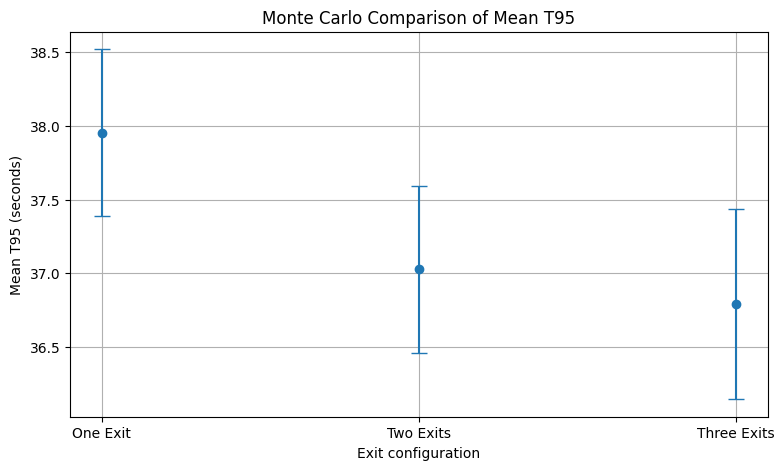

In [98]:
# Plot mean T95 with 95% confidence intervals

scenario_names = monte_carlo_summary["Scenario"]

means = monte_carlo_summary["Mean T95"].to_numpy()

lower = monte_carlo_summary["T95 CI lower"].to_numpy()

upper = monte_carlo_summary["T95 CI upper"].to_numpy()

lower_errors = means - lower

upper_errors = upper - means

plt.figure(figsize=(9, 5))

plt.errorbar(
    scenario_names,
    means,
    yerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=6
)

plt.xlabel("Exit configuration")

plt.ylabel("Mean T95 (seconds)")

plt.title("Monte Carlo Comparison of Mean T95")

plt.grid(True)

plt.show()

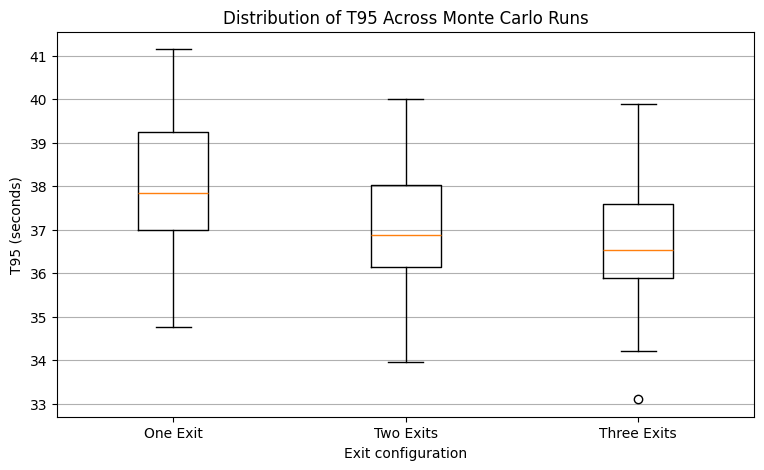

In [99]:
# Plot T95 distributions

t95_data = []

labels = []

for scenario_name, results in monte_carlo_results.items():

    values = [
        r["t95"]
        for r in results
        if np.isfinite(r["t95"])
    ]

    t95_data.append(values)

    labels.append(scenario_name)


plt.figure(figsize=(9, 5))

plt.boxplot(
    t95_data,
    tick_labels=labels
)

plt.xlabel("Exit configuration")

plt.ylabel("T95 (seconds)")

plt.title("Distribution of T95 Across Monte Carlo Runs")

plt.grid(axis="y")

plt.show()

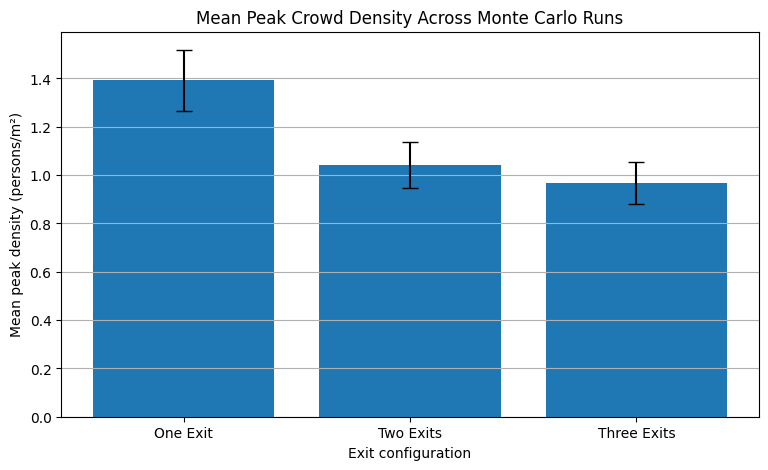

In [100]:
# Compare mean peak density across scenarios

density_means = monte_carlo_summary[
    "Mean peak density"
].to_numpy()

density_sd = monte_carlo_summary[
    "Peak density SD"
].to_numpy()

scenario_names = monte_carlo_summary["Scenario"]

plt.figure(figsize=(9, 5))

plt.bar(
    scenario_names,
    density_means,
    yerr=density_sd,
    capsize=6
)

plt.xlabel("Exit configuration")

plt.ylabel("Mean peak density (persons/m²)")

plt.title("Mean Peak Crowd Density Across Monte Carlo Runs")

plt.grid(axis="y")

plt.show()

In [101]:
# Save Monte Carlo experiment results

replication_df.to_csv(
    "lesson11_monte_carlo_results.csv",
    index=False
)

monte_carlo_summary.to_csv(
    "lesson11_monte_carlo_summary.csv",
    index=False
)

print("Monte Carlo results saved successfully!")

print("1. lesson11_monte_carlo_results.csv")

print("2. lesson11_monte_carlo_summary.csv")

Monte Carlo results saved successfully!
1. lesson11_monte_carlo_results.csv
2. lesson11_monte_carlo_summary.csv


In [102]:
# Lesson 11: Paired comparison between exit configurations

from scipy.stats import t, ttest_rel
import numpy as np

comparisons = [
    ("One Exit", "Two Exits"),
    ("One Exit", "Three Exits"),
    ("Two Exits", "Three Exits")
]

for first_name, second_name in comparisons:

    first_results = monte_carlo_results[first_name]
    second_results = monte_carlo_results[second_name]

    # Extract T95 values in matching replication order
    first_values = np.array([
        r["t95"] for r in first_results
    ])

    second_values = np.array([
        r["t95"] for r in second_results
    ])

    # Calculate paired differences
    differences = first_values - second_values

    # Remove invalid pairs if any
    valid = (
        np.isfinite(first_values)
        & np.isfinite(second_values)
    )

    differences = differences[valid]

    n = len(differences)

    mean_difference = np.mean(differences)

    sd_difference = np.std(
        differences,
        ddof=1
    )

    standard_error = sd_difference / np.sqrt(n)

    critical_value = t.ppf(
        0.975,
        df=n - 1
    )

    margin = critical_value * standard_error

    ci_lower = mean_difference - margin
    ci_upper = mean_difference + margin

    # Paired t-test
    test = ttest_rel(
        first_values[valid],
        second_values[valid]
    )

    print("\n", first_name, "vs", second_name)
    print("-----------------------------------")

    print("Number of paired runs:", n)

    print(
        "Mean T95 difference:",
        round(mean_difference, 3),
        "seconds"
    )

    print(
        "95% CI:",
        round(ci_lower, 3),
        "to",
        round(ci_upper, 3)
    )

    print(
        "Paired t-test p-value:",
         f"{test.pvalue:.6e}"
    )


 One Exit vs Two Exits
-----------------------------------
Number of paired runs: 30
Mean T95 difference: 0.928 seconds
95% CI: 0.692 to 1.164
Paired t-test p-value: 7.207690e-09

 One Exit vs Three Exits
-----------------------------------
Number of paired runs: 30
Mean T95 difference: 1.163 seconds
95% CI: 0.874 to 1.452
Paired t-test p-value: 4.457086e-09

 Two Exits vs Three Exits
-----------------------------------
Number of paired runs: 30
Mean T95 difference: 0.235 seconds
95% CI: 0.034 to 0.436
Paired t-test p-value: 2.356342e-02


In [103]:
# Lesson 11: Monte Carlo verification

expected_replications = 30
expected_agents = 100

print("MONTE CARLO VERIFICATION")
print("-------------------------------")

for scenario_name, results in monte_carlo_results.items():

    assert len(results) == expected_replications

    assert all(
        result["exited"] == expected_agents
        for result in results
    )

    assert all(
        result["remaining"] == 0
        for result in results
    )

    assert all(
        np.isfinite(result["t95"])
        for result in results
    )

    assert all(
        np.isfinite(result["clearance_time"])
        for result in results
    )

    print("\n", scenario_name)
    print("Number of replications: PASS")
    print("All pedestrians exited: PASS")
    print("No remaining pedestrians: PASS")
    print("T95 values are finite: PASS")
    print("Clearance times are finite: PASS")

# Check that all configurations used the same seeds
reference_seeds = [
    result["seed"]
    for result in monte_carlo_results["One Exit"]
]

for scenario_name, results in monte_carlo_results.items():

    current_seeds = [
        result["seed"]
        for result in results
    ]

    assert current_seeds == reference_seeds

print("\nPaired random seeds: PASS")
print("\nALL MONTE CARLO VERIFICATION CHECKS PASSED!")

MONTE CARLO VERIFICATION
-------------------------------

 One Exit
Number of replications: PASS
All pedestrians exited: PASS
No remaining pedestrians: PASS
T95 values are finite: PASS
Clearance times are finite: PASS

 Two Exits
Number of replications: PASS
All pedestrians exited: PASS
No remaining pedestrians: PASS
T95 values are finite: PASS
Clearance times are finite: PASS

 Three Exits
Number of replications: PASS
All pedestrians exited: PASS
No remaining pedestrians: PASS
T95 values are finite: PASS
Clearance times are finite: PASS

Paired random seeds: PASS

ALL MONTE CARLO VERIFICATION CHECKS PASSED!


In [104]:
# Lesson 12: Define crowd-size scenarios

crowd_sizes = [100, 200, 300]

print("CROWD-SIZE EXPERIMENT SETTINGS")
print("--------------------------------")

for size in crowd_sizes:
    print("Number of pedestrians:", size)

print("\nTotal crowd-size scenarios:", len(crowd_sizes))

CROWD-SIZE EXPERIMENT SETTINGS
--------------------------------
Number of pedestrians: 100
Number of pedestrians: 200
Number of pedestrians: 300

Total crowd-size scenarios: 3


In [105]:
# Test random crowd generation for different crowd sizes

crowd_generation_tests = {}

for number_of_agents in crowd_sizes:

    print(f"\nTesting {number_of_agents} pedestrians...")

    try:

        positions, velocities, speeds, radii = (
            generate_random_crowd(
                seed=2000 + number_of_agents,
                number_of_agents=number_of_agents
            )
        )

        # Calculate minimum pedestrian separation
        differences = (
            positions[:, np.newaxis, :]
            - positions[np.newaxis, :, :]
        )

        distances = np.linalg.norm(
            differences,
            axis=2
        )

        np.fill_diagonal(distances, np.inf)

        minimum_distance = np.min(distances)

        # Save generated crowd
        crowd_generation_tests[number_of_agents] = {
            "positions": positions,
            "velocities": velocities,
            "speeds": speeds,
            "radii": radii,
            "minimum_distance": minimum_distance
        }

        print("Crowd generation: PASS")
        print("Generated pedestrians:", len(positions))
        print(
            "Minimum separation:",
            round(minimum_distance, 4),
            "metres"
        )

    except Exception as error:

        print("Crowd generation: FAILED")
        print("Error:", error)


Testing 100 pedestrians...
Crowd generation: PASS
Generated pedestrians: 100
Minimum separation: 0.6637 metres

Testing 200 pedestrians...
Crowd generation: PASS
Generated pedestrians: 200
Minimum separation: 0.6527 metres

Testing 300 pedestrians...
Crowd generation: PASS
Generated pedestrians: 300
Minimum separation: 0.6515 metres


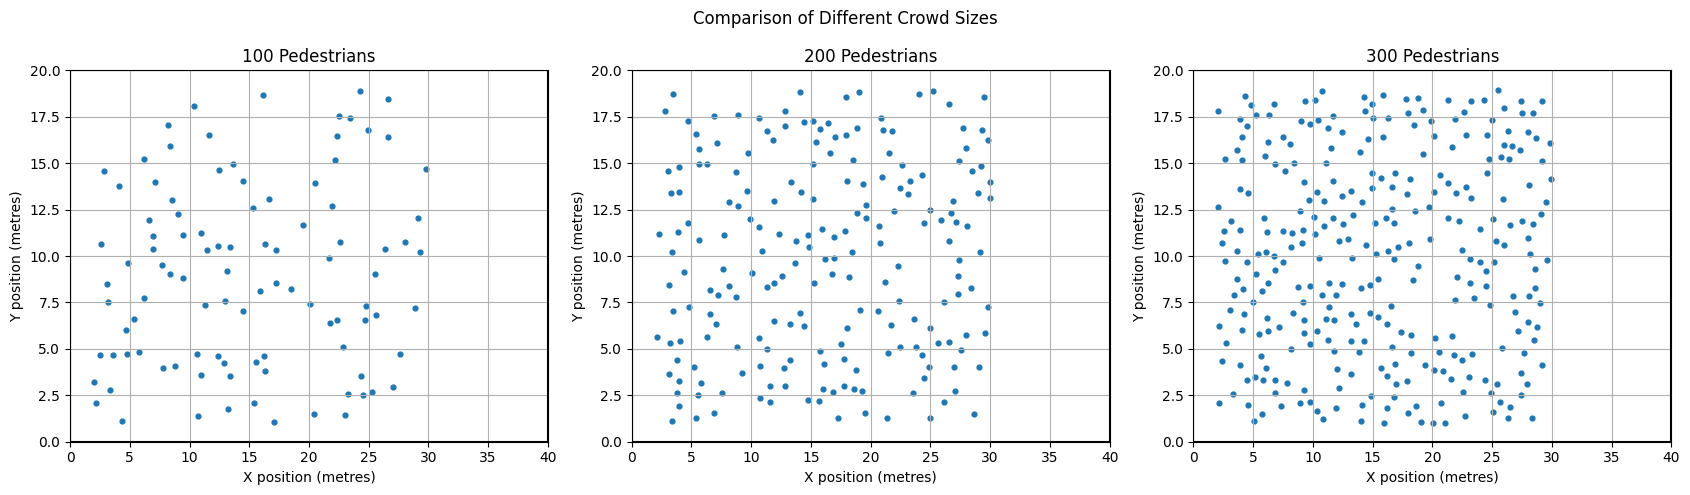

In [106]:
# Visualise different crowd sizes

fig, axes = plt.subplots(
    1,
    len(crowd_sizes),
    figsize=(17, 5)
)

for ax, number_of_agents in zip(axes, crowd_sizes):

    positions = crowd_generation_tests[
        number_of_agents
    ]["positions"]

    ax.scatter(
        positions[:, 0],
        positions[:, 1],
        s=12
    )

    # Draw environment boundaries
    ax.plot([0, WIDTH], [0, 0], color="black")
    ax.plot([0, WIDTH], [HEIGHT, HEIGHT], color="black")
    ax.plot([0, 0], [0, HEIGHT], color="black")
    ax.plot([WIDTH, WIDTH], [0, HEIGHT], color="black")

    ax.set_xlim(0, WIDTH)
    ax.set_ylim(0, HEIGHT)

    ax.set_xlabel("X position (metres)")
    ax.set_ylabel("Y position (metres)")

    ax.set_title(
        f"{number_of_agents} Pedestrians"
    )

    ax.grid(True)

plt.suptitle("Comparison of Different Crowd Sizes")

plt.tight_layout()

plt.show()

In [107]:
# Lesson 12: Initial crowd-size sensitivity experiments

lesson12_scenarios = {
    "One Exit": exit_scenarios["One Exit"],
    "Two Exits": exit_scenarios["Two Exits"],
    "Three Exits": exit_scenarios["Three Exits"]
}

lesson12_initial_results = []

for number_of_agents in crowd_sizes:

    print(
        f"\nTesting crowd size: {number_of_agents}"
    )

    # Get the previously generated crowd
    crowd_data = crowd_generation_tests[
        number_of_agents
    ]

    # Set the simulation's global crowd arrays
    crowd_positions = crowd_data["positions"].copy()

    crowd_velocities = crowd_data["velocities"].copy()

    crowd_desired_speeds = crowd_data["speeds"].copy()

    crowd_radii = crowd_data["radii"].copy()

    # Run all exit configurations with this same crowd
    for scenario_name, exits in lesson12_scenarios.items():

        print("Running:", scenario_name)

        result = run_exit_scenario(exits)

        lesson12_initial_results.append({

            "Crowd size": number_of_agents,

            "Exit configuration": scenario_name,

            "T95 (s)": result["t95"],

            "Clearance time (s)": result["clearance_time"],

            "Peak density (persons/m²)": result["peak_density"],

            "Exited": int(np.sum(result["exited"])),

            "Remaining": int(np.sum(~result["exited"]))

        })

        print(
            "Exited:",
            int(np.sum(result["exited"]))
        )

print("\nINITIAL CROWD-SIZE EXPERIMENTS COMPLETED!")


Testing crowd size: 100
Running: One Exit
Exited: 100
Running: Two Exits
Exited: 100
Running: Three Exits
Exited: 100

Testing crowd size: 200
Running: One Exit
Exited: 200
Running: Two Exits
Exited: 200
Running: Three Exits
Exited: 200

Testing crowd size: 300
Running: One Exit
Exited: 300
Running: Two Exits
Exited: 300
Running: Three Exits
Exited: 300

INITIAL CROWD-SIZE EXPERIMENTS COMPLETED!


In [108]:
# Display crowd-size sensitivity results

lesson12_initial_df = pd.DataFrame(
    lesson12_initial_results
)

display(
    lesson12_initial_df.round(3)
)

,Crowd size,Exit configuration,T95 (s),Clearance time (s),Peak density (persons/m²),Exited,Remaining
0,100,One Exit,34.35,41.45,1.25,100,0
1,100,Two Exits,32.75,41.35,1.25,100,0
2,100,Three Exits,32.30,41.05,1.00,100,0
3,200,One Exit,39.05,48.60,1.75,200,0
4,200,Two Exits,36.65,47.75,1.50,200,0
5,200,Three Exits,35.90,47.55,1.25,200,0
6,300,One Exit,44.45,53.65,2.25,300,0
7,300,Two Exits,40.80,50.00,1.75,300,0
8,300,Three Exits,39.05,48.70,1.25,300,0


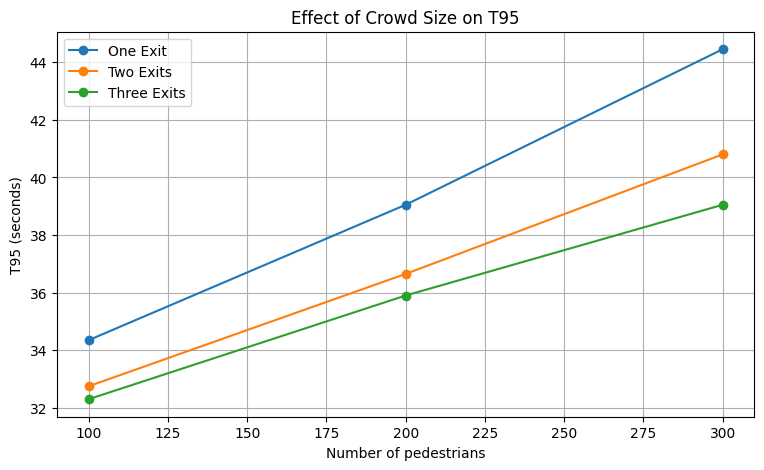

In [109]:
# Plot T95 against crowd size

plt.figure(figsize=(9, 5))

for scenario_name in lesson12_scenarios:

    scenario_data = lesson12_initial_df[
        lesson12_initial_df["Exit configuration"]
        == scenario_name
    ]

    plt.plot(
        scenario_data["Crowd size"],
        scenario_data["T95 (s)"],
        marker="o",
        label=scenario_name
    )

plt.xlabel("Number of pedestrians")

plt.ylabel("T95 (seconds)")

plt.title("Effect of Crowd Size on T95")

plt.legend()

plt.grid(True)

plt.show()

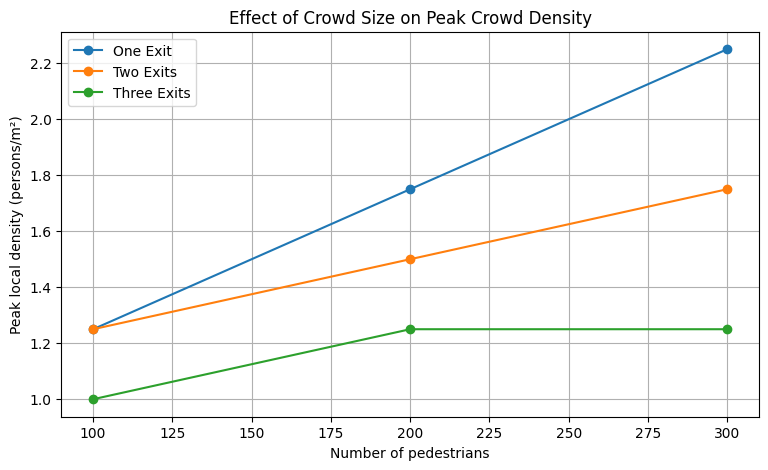

In [110]:
# Plot peak density against crowd size

plt.figure(figsize=(9, 5))

for scenario_name in lesson12_scenarios:

    scenario_data = lesson12_initial_df[
        lesson12_initial_df["Exit configuration"]
        == scenario_name
    ]

    plt.plot(
        scenario_data["Crowd size"],
        scenario_data["Peak density (persons/m²)"],
        marker="o",
        label=scenario_name
    )

plt.xlabel("Number of pedestrians")

plt.ylabel("Peak local density (persons/m²)")

plt.title("Effect of Crowd Size on Peak Crowd Density")

plt.legend()

plt.grid(True)

plt.show()

In [111]:
# Generate uncertain crowd sizes

rng = np.random.default_rng(12345)

minimum_crowd = 100

most_likely_crowd = 300

maximum_crowd = 500

number_of_samples = 1000

sampled_crowd_sizes = rng.triangular(
    minimum_crowd,
    most_likely_crowd,
    maximum_crowd,
    number_of_samples
)

# Convert sampled values into whole pedestrians
sampled_crowd_sizes = np.rint(
    sampled_crowd_sizes
).astype(int)

print("UNCERTAIN CROWD SIZE GENERATION")
print("--------------------------------")

print("Number of samples:", len(sampled_crowd_sizes))

print("Minimum sampled crowd:", np.min(sampled_crowd_sizes))

print("Maximum sampled crowd:", np.max(sampled_crowd_sizes))

print("Average sampled crowd:", round(np.mean(sampled_crowd_sizes), 2))

UNCERTAIN CROWD SIZE GENERATION
--------------------------------
Number of samples: 1000
Minimum sampled crowd: 106
Maximum sampled crowd: 492
Average sampled crowd: 298.24


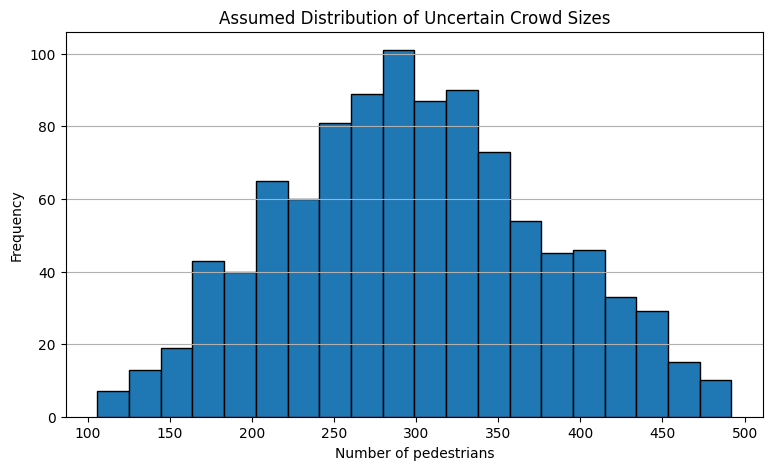

In [112]:
# Plot uncertain crowd-size distribution

plt.figure(figsize=(9, 5))

plt.hist(
    sampled_crowd_sizes,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Number of pedestrians")

plt.ylabel("Frequency")

plt.title("Assumed Distribution of Uncertain Crowd Sizes")

plt.grid(axis="y")

plt.show()

In [113]:
# Lesson 12: Test larger crowd sizes

larger_crowd_tests = {}

for number_of_agents in [400, 500]:

    print(f"\nTesting {number_of_agents} pedestrians...")

    try:

        positions, velocities, speeds, radii = (
            generate_random_crowd(
                seed=3000 + number_of_agents,
                number_of_agents=number_of_agents
            )
        )

        differences = (
            positions[:, np.newaxis, :]
            - positions[np.newaxis, :, :]
        )

        distances = np.linalg.norm(
            differences,
            axis=2
        )

        np.fill_diagonal(distances, np.inf)

        minimum_distance = np.min(distances)

        larger_crowd_tests[number_of_agents] = {
            "positions": positions,
            "velocities": velocities,
            "speeds": speeds,
            "radii": radii,
            "minimum_distance": minimum_distance
        }

        print("Crowd generation: PASS")
        print("Generated pedestrians:", len(positions))
        print(
            "Minimum separation:",
            round(minimum_distance, 4),
            "metres"
        )

    except Exception as error:

        print("Crowd generation: FAILED")
        print("Error:", error)


Testing 400 pedestrians...
Crowd generation: PASS
Generated pedestrians: 400
Minimum separation: 0.6507 metres

Testing 500 pedestrians...
Crowd generation: PASS
Generated pedestrians: 500
Minimum separation: 0.6511 metres


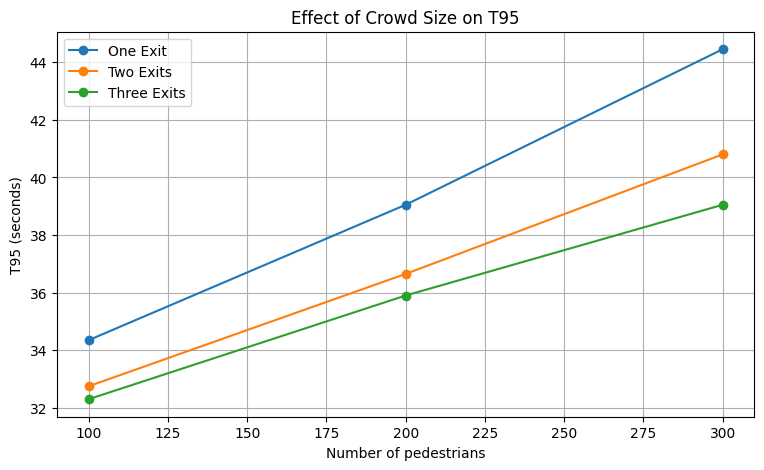

In [114]:
# Lesson 12: T95 versus crowd size

plt.figure(figsize=(9, 5))

for scenario_name in lesson12_scenarios:

    scenario_data = lesson12_initial_df[
        lesson12_initial_df["Exit configuration"]
        == scenario_name
    ]

    plt.plot(
        scenario_data["Crowd size"],
        scenario_data["T95 (s)"],
        marker="o",
        label=scenario_name
    )

plt.xlabel("Number of pedestrians")
plt.ylabel("T95 (seconds)")

plt.title("Effect of Crowd Size on T95")

plt.legend()
plt.grid(True)
plt.show()

In [115]:
# Main crowd-size sensitivity experiment

lesson12_crowd_sizes = [100, 200, 300, 400, 500]

lesson12_replications = 30

lesson12_exit_scenarios = {
    "One Exit": exit_scenarios["One Exit"],
    "Two Exits": exit_scenarios["Two Exits"],
    "Three Exits": exit_scenarios["Three Exits"]
}

print("LESSON 12 MAIN EXPERIMENT")
print("-------------------------")

print("Crowd sizes:", lesson12_crowd_sizes)

print("Replications:", lesson12_replications)

print("Exit configurations:", len(lesson12_exit_scenarios))

total_runs = (
    len(lesson12_crowd_sizes)
    * lesson12_replications
    * len(lesson12_exit_scenarios)
)

print("Total planned simulations:", total_runs)

LESSON 12 MAIN EXPERIMENT
-------------------------
Crowd sizes: [100, 200, 300, 400, 500]
Replications: 30
Exit configurations: 3
Total planned simulations: 450


In [116]:
# Lesson 12: Run repeated crowd-size sensitivity experiments

lesson12_main_results = []

for crowd_size in lesson12_crowd_sizes:

    print("\n" + "=" * 45)
    print(f"CROWD SIZE: {crowd_size}")
    print("=" * 45)

    for replication in range(1, lesson12_replications + 1):

        print(
            f"\nReplication {replication}/{lesson12_replications}"
        )

        # Generate one crowd for this replication
        seed = 500000 + crowd_size * 100 + replication

        positions, velocities, speeds, radii = (
            generate_random_crowd(
                seed=seed,
                number_of_agents=crowd_size
            )
        )

        # Keep a copy of the same initial crowd
        initial_positions = positions.copy()
        initial_velocities = velocities.copy()
        initial_speeds = speeds.copy()
        initial_radii = radii.copy()

        # Run each exit configuration using the same initial crowd
        for scenario_name, exits in lesson12_exit_scenarios.items():

            print("Running:", scenario_name)

            # Reset the global simulation inputs
            crowd_positions = initial_positions.copy()
            crowd_velocities = initial_velocities.copy()
            crowd_desired_speeds = initial_speeds.copy()
            crowd_radii = initial_radii.copy()

            result = run_exit_scenario(exits)

            exited_count = int(np.sum(result["exited"]))
            remaining_count = crowd_size - exited_count

            lesson12_main_results.append({

                "Crowd size": crowd_size,

                "Replication": replication,

                "Seed": seed,

                "Exit configuration": scenario_name,

                "T95 (s)": result["t95"],

                "Clearance time (s)": result["clearance_time"],

                "Peak density (persons/m²)": result["peak_density"],

                "Exited": exited_count,

                "Remaining": remaining_count

            })

            print(
                f"Exited: {exited_count}/{crowd_size}"
            )

    print(f"\nCompleted crowd size: {crowd_size}")

print("\nALL LESSON 12 EXPERIMENTS FINISHED!")


CROWD SIZE: 100

Replication 1/30
Running: One Exit
Exited: 100/100
Running: Two Exits
Exited: 100/100
Running: Three Exits
Exited: 100/100

Replication 2/30
Running: One Exit
Exited: 100/100
Running: Two Exits
Exited: 100/100
Running: Three Exits
Exited: 100/100

Replication 3/30
Running: One Exit
Exited: 100/100
Running: Two Exits
Exited: 100/100
Running: Three Exits
Exited: 100/100

Replication 4/30
Running: One Exit
Exited: 100/100
Running: Two Exits
Exited: 100/100
Running: Three Exits
Exited: 100/100

Replication 5/30
Running: One Exit
Exited: 100/100
Running: Two Exits
Exited: 100/100
Running: Three Exits
Exited: 100/100

Replication 6/30
Running: One Exit
Exited: 100/100
Running: Two Exits
Exited: 100/100
Running: Three Exits
Exited: 100/100

Replication 7/30
Running: One Exit
Exited: 100/100
Running: Two Exits
Exited: 100/100
Running: Three Exits
Exited: 100/100

Replication 8/30
Running: One Exit
Exited: 100/100
Running: Two Exits
Exited: 100/100
Running: Three Exits
Exited:

In [117]:
# Display individual simulation results

lesson12_results_df = pd.DataFrame(
    lesson12_main_results
)

display(lesson12_results_df.round(3))

# Save individual results
lesson12_results_df.to_csv(
    "lesson12_crowd_size_results.csv",
    index=False
)

print("Individual results saved successfully!")

,Crowd size,Replication,Seed,Exit configuration,T95 (s),Clearance time (s),Peak density (persons/m²),Exited,Remaining
0,100,1,510001,One Exit,37.30,43.90,1.50,100,0
1,100,1,510001,Two Exits,35.55,43.60,1.25,100,0
2,100,1,510001,Three Exits,35.90,42.75,1.00,100,0
3,100,2,510002,One Exit,39.80,46.40,1.25,100,0
4,100,2,510002,Two Exits,39.50,44.50,1.00,100,0
...,...,...,...,...,...,...,...,...,...
445,500,29,550029,Two Exits,41.10,51.65,2.00,500,0
446,500,29,550029,Three Exits,38.85,50.20,1.75,500,0
447,500,30,550030,One Exit,46.80,57.80,2.75,500,0
448,500,30,550030,Two Exits,41.20,51.00,2.25,500,0


Individual results saved successfully!


In [118]:
# Lesson 12: Statistical summary

from scipy import stats

# A run is successful only if all pedestrians exited
lesson12_results_df["Successful"] = (
    (lesson12_results_df["Exited"] == lesson12_results_df["Crowd size"])
    & (lesson12_results_df["Remaining"] == 0)
    & np.isfinite(lesson12_results_df["T95 (s)"])
    & np.isfinite(lesson12_results_df["Clearance time (s)"])
    & np.isfinite(lesson12_results_df["Peak density (persons/m²)"])
)

summary_rows = []

for (crowd_size, scenario), group in lesson12_results_df.groupby(
    ["Crowd size", "Exit configuration"]
):

    successful = group[group["Successful"]]

    t95_values = successful["T95 (s)"].dropna()
    clearance_values = successful["Clearance time (s)"].dropna()
    density_values = successful["Peak density (persons/m²)"].dropna()

    n = len(t95_values)

    if n >= 2:

        mean_t95 = t95_values.mean()
        sd_t95 = t95_values.std(ddof=1)

        margin = stats.t.ppf(
            0.975,
            df=n - 1
        ) * sd_t95 / np.sqrt(n)

        ci_lower = mean_t95 - margin
        ci_upper = mean_t95 + margin

    else:

        mean_t95 = t95_values.mean() if n == 1 else np.nan
        sd_t95 = np.nan
        ci_lower = np.nan
        ci_upper = np.nan

    summary_rows.append({

        "Crowd size": crowd_size,

        "Exit configuration": scenario,

        "Successful runs": n,

        "Total runs": len(group),

        "Mean T95 (s)": mean_t95,

        "T95 SD (s)": sd_t95,

        "T95 CI lower": ci_lower,

        "T95 CI upper": ci_upper,

        "Mean clearance (s)": clearance_values.mean(),

        "Mean peak density": density_values.mean(),

        "Peak density SD": density_values.std(ddof=1)

    })

lesson12_summary_df = pd.DataFrame(summary_rows)

display(lesson12_summary_df.round(3))

lesson12_summary_df.to_csv(
    "lesson12_crowd_size_summary.csv",
    index=False
)

print("Statistical summary saved successfully!")

,Crowd size,Exit configuration,Successful runs,Total runs,Mean T95 (s),T95 SD (s),T95 CI lower,T95 CI upper,Mean clearance (s),Mean peak density,Peak density SD
0,100,One Exit,30,30,37.257,1.850,36.566,37.947,45.308,1.408,0.139
1,100,Three Exits,30,30,35.912,2.195,35.092,36.731,44.283,1.000,0.066
2,100,Two Exits,30,30,36.182,2.208,35.357,37.006,44.547,1.050,0.121
3,200,One Exit,30,30,39.622,1.203,39.172,40.071,48.043,1.917,0.165
4,200,Three Exits,30,30,36.525,1.469,35.977,37.073,45.902,1.242,0.080
5,200,Two Exits,30,30,37.217,1.408,36.691,37.742,46.323,1.450,0.121
6,300,One Exit,30,30,42.102,1.154,41.671,42.533,50.832,2.342,0.123
7,300,Three Exits,30,30,37.020,1.310,36.531,37.509,46.970,1.475,0.101
8,300,Two Exits,30,30,38.112,1.304,37.625,38.598,47.448,1.758,0.103
9,400,One Exit,30,30,44.345,0.766,44.059,44.631,54.188,2.650,0.125


Statistical summary saved successfully!


In [119]:

# X5: Confidence intervals for all main performance measures

from scipy import stats
import numpy as np
import pandas as pd

x5_summary_rows = []

for (crowd_size, scenario), group in lesson12_results_df.groupby(
    ["Crowd size", "Exit configuration"]
):

    successful = group[group["Successful"]]

    metrics = {
        "T95": successful["T95 (s)"].dropna().to_numpy(),
        "Clearance": successful["Clearance time (s)"].dropna().to_numpy(),
        "Peak density": successful["Peak density (persons/m²)"].dropna().to_numpy()
    }

    row = {
        "Crowd size": crowd_size,
        "Exit configuration": scenario,
        "Successful runs": len(successful)
    }

    for metric_name, values in metrics.items():

        n = len(values)

        mean_value = np.mean(values)
        standard_deviation = np.std(values, ddof=1)

        margin = (
            stats.t.ppf(0.975, df=n - 1)
            * standard_deviation
            / np.sqrt(n)
        )

        row[f"Mean {metric_name}"] = mean_value
        row[f"{metric_name} CI lower"] = mean_value - margin
        row[f"{metric_name} CI upper"] = mean_value + margin

    x5_summary_rows.append(row)

x5_summary_df = pd.DataFrame(x5_summary_rows)

display(x5_summary_df.round(3))

# Confirm that all 15 scenario groups contain 30 successful runs
assert len(x5_summary_df) == 15
assert (x5_summary_df["Successful runs"] == 30).all()

print("X5 confidence interval calculations completed.")
print("All 15 scenario groups contain 30 successful runs.")


,Crowd size,Exit configuration,Successful runs,Mean T95,T95 CI lower,T95 CI upper,Mean Clearance,Clearance CI lower,Clearance CI upper,Mean Peak density,Peak density CI lower,Peak density CI upper
0,100,One Exit,30,37.257,36.566,37.947,45.308,44.394,46.223,1.408,1.356,1.460
1,100,Three Exits,30,35.912,35.092,36.731,44.283,43.320,45.246,1.000,0.975,1.025
2,100,Two Exits,30,36.182,35.357,37.006,44.547,43.601,45.492,1.050,1.005,1.095
3,200,One Exit,30,39.622,39.172,40.071,48.043,47.322,48.764,1.917,1.855,1.978
4,200,Three Exits,30,36.525,35.977,37.073,45.902,44.924,46.880,1.242,1.212,1.272
5,200,Two Exits,30,37.217,36.691,37.742,46.323,45.386,47.261,1.450,1.405,1.495
6,300,One Exit,30,42.102,41.671,42.533,50.832,50.388,51.275,2.342,2.296,2.387
7,300,Three Exits,30,37.020,36.531,37.509,46.970,46.281,47.659,1.475,1.437,1.513
8,300,Two Exits,30,38.112,37.625,38.598,47.448,46.785,48.112,1.758,1.720,1.797
9,400,One Exit,30,44.345,44.059,44.631,54.188,53.789,54.588,2.650,2.603,2.697


X5 confidence interval calculations completed.
All 15 scenario groups contain 30 successful runs.



### X5 - Sensitivity and Uncertainty Analysis

A systematic parameter study was conducted to investigate how crowd size and exit availability influence pedestrian dispersal performance. Five crowd sizes (100, 200, 300, 400 and 500 pedestrians) and three exit configurations (one, two and three exits) were examined. Each combination was evaluated using 30 simulation replications, resulting in 450 simulation runs.

The analysis calculated mean T95, total clearance time and peak local density for each scenario. The corresponding 95% confidence intervals were calculated to represent uncertainty in the estimated mean performance measures.

#### Results and Interpretation

The results show that crowd size has a clear influence on pedestrian dispersal. As the initial crowd increased from 100 to 500 pedestrians, mean T95 increased from 37.257 to 46.717 seconds for one exit, from 36.182 to 40.897 seconds for two exits, and from 35.912 to 38.885 seconds for three exits.

Exit availability also influenced the results. The three-exit configuration produced the lowest mean T95 across all five crowd sizes. The difference between the one-exit and three-exit configurations increased as crowd size increased, indicating that additional exits provided greater improvements in dispersal time under larger simulated crowds.

Peak local density also increased with crowd size. For the one-exit configuration, mean peak density increased from 1.408 persons/m² at 100 pedestrians to 2.958 persons/m² at 500 pedestrians. The three-exit configuration produced lower mean peak density values, ranging from 1.000 to 1.817 persons/m² across the tested crowd sizes.

The confidence intervals provide an indication of the uncertainty associated with the estimated mean values. Overall, the results identify crowd size and exit availability as important factors influencing dispersal time and congestion within the simulated environment.

These findings are limited to the assumed parameters, synthetic pedestrian information and hypothetical environment used in this study. They should not be interpreted as direct predictions of actual crowd behaviour at the Kandy Esala Perahera.


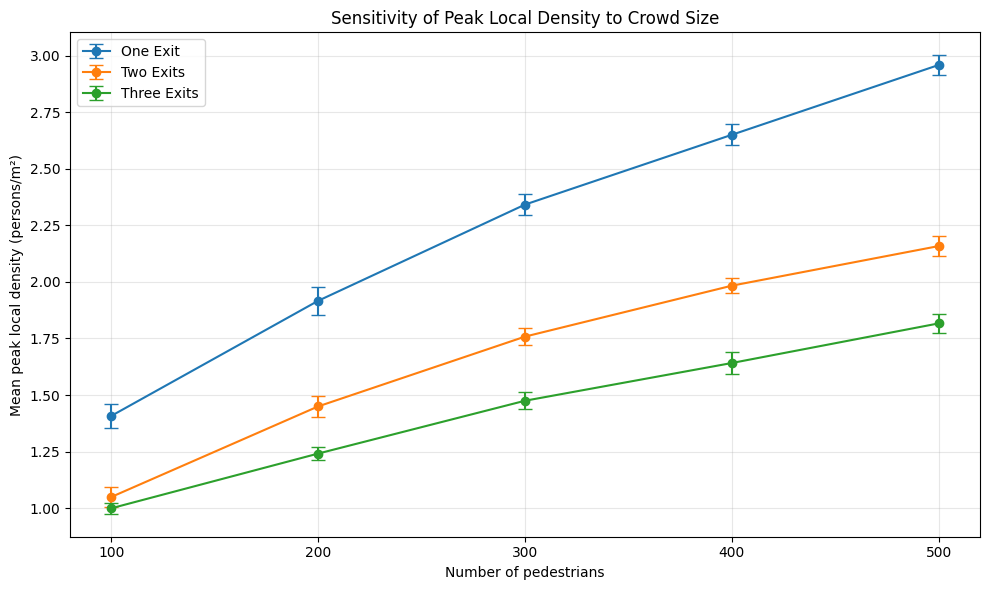

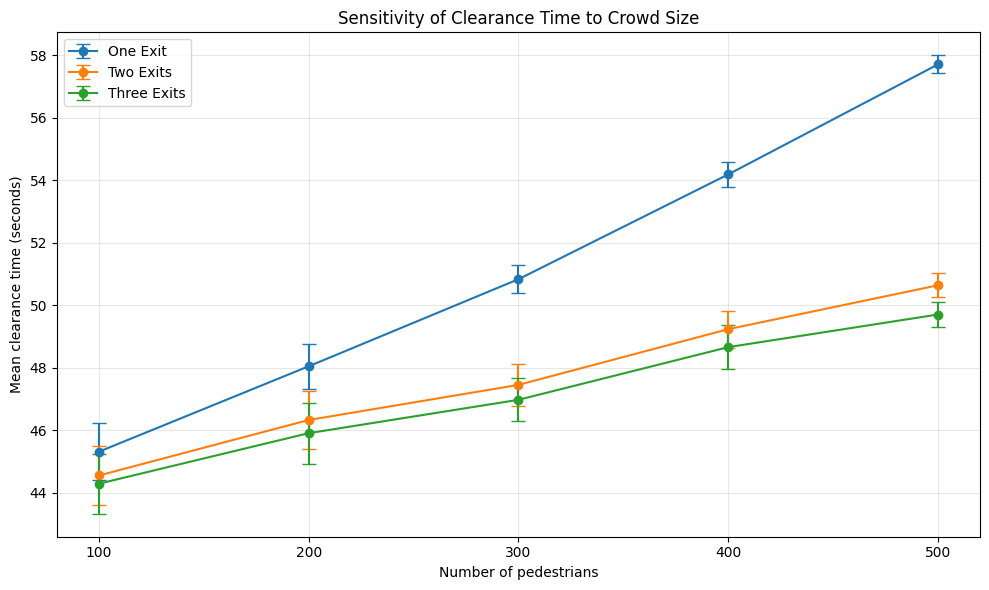

Both X5 sensitivity plots generated successfully.
Figures saved in the figures/ directory.


In [135]:

# X5: Visualisation of Sensitivity Analysis with 95% Confidence Intervals

import matplotlib.pyplot as plt
import os

# Create figures directory if it does not exist
os.makedirs("figures", exist_ok=True)

# Define exit configurations
exit_configurations = [
    "One Exit",
    "Two Exits",
    "Three Exits"
]

# Sort crowd sizes
crowd_sizes = sorted(x5_summary_df["Crowd size"].unique())


# --------------------------------------------------
# Plot 1: Mean Peak Density with 95% Confidence Intervals
# --------------------------------------------------

plt.figure(figsize=(10, 6))

for scenario in exit_configurations:

    data = x5_summary_df[
        x5_summary_df["Exit configuration"] == scenario
    ].sort_values("Crowd size")

    mean_values = data["Mean Peak density"]

    lower_errors = (
        mean_values - data["Peak density CI lower"]
    )

    upper_errors = (
        data["Peak density CI upper"] - mean_values
    )

    plt.errorbar(
        data["Crowd size"],
        mean_values,
        yerr=[lower_errors, upper_errors],
        marker="o",
        capsize=5,
        label=scenario
    )

plt.xlabel("Number of pedestrians")
plt.ylabel("Mean peak local density (persons/m²)")
plt.title("Sensitivity of Peak Local Density to Crowd Size")
plt.xticks(crowd_sizes)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/x5_peak_density_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# Plot 2: Mean Clearance Time with 95% Confidence Intervals
# --------------------------------------------------

plt.figure(figsize=(10, 6))

for scenario in exit_configurations:

    data = x5_summary_df[
        x5_summary_df["Exit configuration"] == scenario
    ].sort_values("Crowd size")

    mean_values = data["Mean Clearance"]

    lower_errors = (
        mean_values - data["Clearance CI lower"]
    )

    upper_errors = (
        data["Clearance CI upper"] - mean_values
    )

    plt.errorbar(
        data["Crowd size"],
        mean_values,
        yerr=[lower_errors, upper_errors],
        marker="o",
        capsize=5,
        label=scenario
    )

plt.xlabel("Number of pedestrians")
plt.ylabel("Mean clearance time (seconds)")
plt.title("Sensitivity of Clearance Time to Crowd Size")
plt.xticks(crowd_sizes)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/x5_clearance_time_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("Both X5 sensitivity plots generated successfully.")
print("Figures saved in the figures/ directory.")


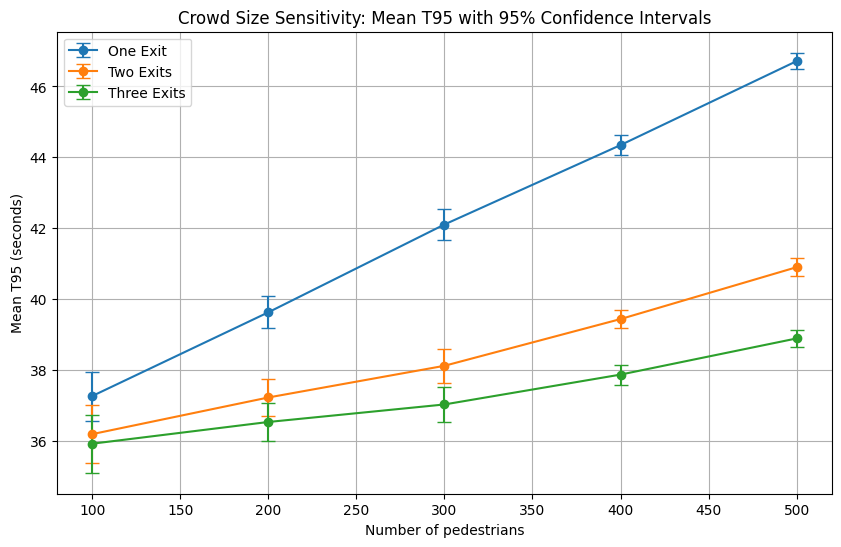

In [120]:
# Mean T95 with 95% confidence intervals

plt.figure(figsize=(10, 6))

for scenario in lesson12_exit_scenarios:

    data = lesson12_summary_df[
        lesson12_summary_df["Exit configuration"] == scenario
    ].sort_values("Crowd size")

    errors = [
        data["Mean T95 (s)"] - data["T95 CI lower"],
        data["T95 CI upper"] - data["Mean T95 (s)"]
    ]

    plt.errorbar(
        data["Crowd size"],
        data["Mean T95 (s)"],
        yerr=errors,
        marker="o",
        capsize=5,
        label=scenario
    )

plt.xlabel("Number of pedestrians")
plt.ylabel("Mean T95 (seconds)")

plt.title("Crowd Size Sensitivity: Mean T95 with 95% Confidence Intervals")

plt.legend()
plt.grid(True)
plt.show()

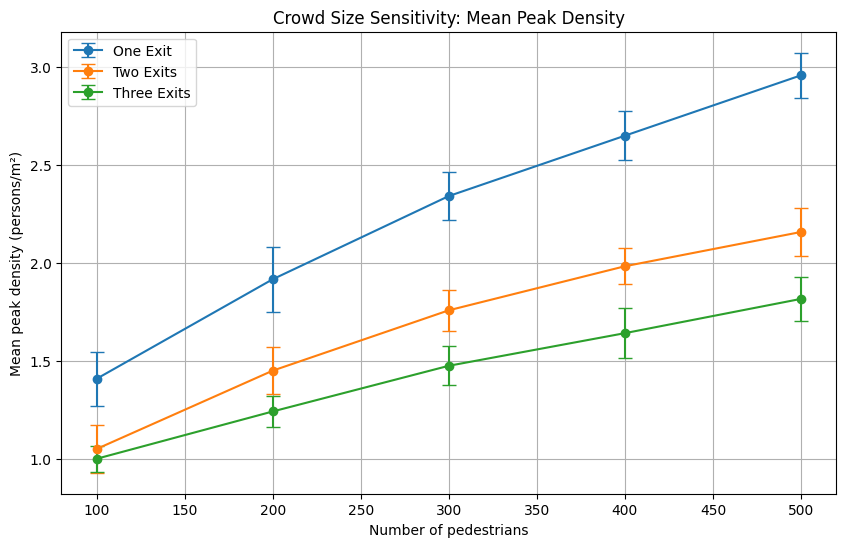

In [121]:
# Mean peak density with standard deviation

plt.figure(figsize=(10, 6))

for scenario in lesson12_exit_scenarios:

    data = lesson12_summary_df[
        lesson12_summary_df["Exit configuration"] == scenario
    ].sort_values("Crowd size")

    plt.errorbar(
        data["Crowd size"],
        data["Mean peak density"],
        yerr=data["Peak density SD"],
        marker="o",
        capsize=5,
        label=scenario
    )

plt.xlabel("Number of pedestrians")
plt.ylabel("Mean peak density (persons/m²)")

plt.title("Crowd Size Sensitivity: Mean Peak Density")

plt.legend()
plt.grid(True)
plt.show()

In [122]:
# Lesson 12: Paired statistical comparisons
# Apply Holm correction for multiple comparisons

import numpy as np
import pandas as pd
from scipy.stats import t, ttest_rel

comparisons = [
    ("One Exit", "Two Exits"),
    ("One Exit", "Three Exits"),
    ("Two Exits", "Three Exits")
]

paired_results = []

for crowd_size in lesson12_crowd_sizes:

    crowd_data = lesson12_results_df[
        (lesson12_results_df["Crowd size"] == crowd_size)
        & (lesson12_results_df["Successful"] == True)
    ]

    # Arrange matched replications into columns
    pivot = crowd_data.pivot(
        index="Replication",
        columns="Exit configuration",
        values="T95 (s)"
    )

    for first, second in comparisons:

        paired = pivot[[first, second]].dropna()

        first_values = paired[first].to_numpy()
        second_values = paired[second].to_numpy()

        # Positive difference means the second configuration
        # has a lower T95.
        differences = first_values - second_values

        n = len(differences)

        mean_difference = np.mean(differences)
        sd_difference = np.std(differences, ddof=1)

        standard_error = sd_difference / np.sqrt(n)

        critical_value = t.ppf(
            0.975,
            df=n - 1
        )

        margin = critical_value * standard_error

        ci_lower = mean_difference - margin
        ci_upper = mean_difference + margin

        test = ttest_rel(
            first_values,
            second_values
        )

        paired_results.append({

            "Crowd size": crowd_size,

            "Comparison": f"{first} vs {second}",

            "Paired runs": n,

            "Mean difference (s)": mean_difference,

            "CI lower": ci_lower,

            "CI upper": ci_upper,

            "Raw p-value": test.pvalue

        })

paired_df = pd.DataFrame(paired_results)

# Holm multiple-comparison correction
p_values = paired_df["Raw p-value"].to_numpy()

order = np.argsort(p_values)

adjusted = np.empty(len(p_values))

running_max = 0

m = len(p_values)

for rank, index in enumerate(order):

    adjusted_value = min(
        1.0,
        (m - rank) * p_values[index]
    )

    running_max = max(
        running_max,
        adjusted_value
    )

    adjusted[index] = running_max

paired_df["Holm adjusted p"] = adjusted

paired_df["Significant (5%)"] = (
    paired_df["Holm adjusted p"] < 0.05
)

display(paired_df.round(5))

paired_df.to_csv(
    "lesson12_paired_comparisons.csv",
    index=False
)

print("Paired comparisons completed and saved!")

,Crowd size,Comparison,Paired runs,Mean difference (s),CI lower,CI upper,Raw p-value,Holm adjusted p,Significant (5%)
0,100,One Exit vs Two Exits,30,1.07500,0.81570,1.33430,0.00000,0.00000,True
1,100,One Exit vs Three Exits,30,1.34500,1.02254,1.66746,0.00000,0.00000,True
2,100,Two Exits vs Three Exits,30,0.27000,0.02122,0.51878,0.03442,0.03442,True
3,200,One Exit vs Two Exits,30,2.40500,2.22087,2.58913,0.00000,0.00000,True
4,200,One Exit vs Three Exits,30,3.09667,2.85112,3.34221,0.00000,0.00000,True
5,200,Two Exits vs Three Exits,30,0.69167,0.52582,0.85751,0.00000,0.00000,True
6,300,One Exit vs Two Exits,30,3.99000,3.86896,4.11104,0.00000,0.00000,True
7,300,One Exit vs Three Exits,30,5.08167,4.92924,5.23409,0.00000,0.00000,True
8,300,Two Exits vs Three Exits,30,1.09167,0.98650,1.19684,0.00000,0.00000,True
9,400,One Exit vs Two Exits,30,4.91333,4.78766,5.03900,0.00000,0.00000,True


Paired comparisons completed and saved!


In [123]:
# Display exact p-values in scientific notation

display_paired = paired_df.copy()

display_paired["Raw p-value"] = (
    display_paired["Raw p-value"].map(
        lambda x: f"{x:.6e}"
    )
)

display_paired["Holm adjusted p"] = (
    display_paired["Holm adjusted p"].map(
        lambda x: f"{x:.6e}"
    )
)

display(display_paired)

,Crowd size,Comparison,Paired runs,Mean difference (s),CI lower,CI upper,Raw p-value,Holm adjusted p,Significant (5%)
0,100,One Exit vs Two Exits,30,1.075000,0.815705,1.334295,2.418857e-09,8.521944e-09,True
1,100,One Exit vs Three Exits,30,1.345000,1.022538,1.667462,2.130486e-09,8.521944e-09,True
2,100,Two Exits vs Three Exits,30,0.270000,0.021216,0.518784,3.442136e-02,3.442136e-02,True
3,200,One Exit vs Two Exits,30,2.405000,2.220867,2.589133,5.674625e-22,3.972237e-21,True
4,200,One Exit vs Three Exits,30,3.096667,2.851125,3.342208,1.506351e-21,9.038109e-21,True
5,200,Two Exits vs Three Exits,30,0.691667,0.525824,0.857509,2.134986e-09,8.521944e-09,True
6,300,One Exit vs Two Exits,30,3.990000,3.868963,4.111037,1.985731e-33,1.985731e-32,True
7,300,One Exit vs Three Exits,30,5.081667,4.929239,5.234095,1.435648e-33,1.579213e-32,True
8,300,Two Exits vs Three Exits,30,1.091667,0.986498,1.196835,3.238021e-19,1.619011e-18,True
9,400,One Exit vs Two Exits,30,4.913333,4.787664,5.039002,1.446691e-35,1.736030e-34,True


In [124]:
# LESSON 12 PART 3
# Generate random crowd sizes

import numpy as np
import matplotlib.pyplot as plt

# Create a reproducible random generator
rng = np.random.default_rng(2026)

# Triangular distribution parameters
MIN_CROWD = 100
MOST_LIKELY_CROWD = 300
MAX_CROWD = 500

# Number of uncertainty experiment replications
NUMBER_OF_SAMPLES = 30

# Generate random crowd sizes
uncertain_crowd_sizes = rng.triangular(
    MIN_CROWD,
    MOST_LIKELY_CROWD,
    MAX_CROWD,
    size=NUMBER_OF_SAMPLES
)

# Convert crowd sizes into whole pedestrians
uncertain_crowd_sizes = np.rint(
    uncertain_crowd_sizes
).astype(int)

# Display results
print("UNCERTAIN CROWD SIZE GENERATION")
print("--------------------------------")

print("Number of samples:", len(uncertain_crowd_sizes))

print("Generated crowd sizes:")
print(uncertain_crowd_sizes)

print("Minimum crowd:", np.min(uncertain_crowd_sizes))

print("Maximum crowd:", np.max(uncertain_crowd_sizes))

print("Average crowd:", np.mean(uncertain_crowd_sizes))

UNCERTAIN CROWD SIZE GENERATION
--------------------------------
Number of samples: 30
Generated crowd sizes:
[220 330 293 272 269 371 413 219 333 254 449 420 329 359 303 382 289 265
 249 235 305 286 336 132 289 271 225 320 287 255]
Minimum crowd: 132
Maximum crowd: 449
Average crowd: 298.6666666666667


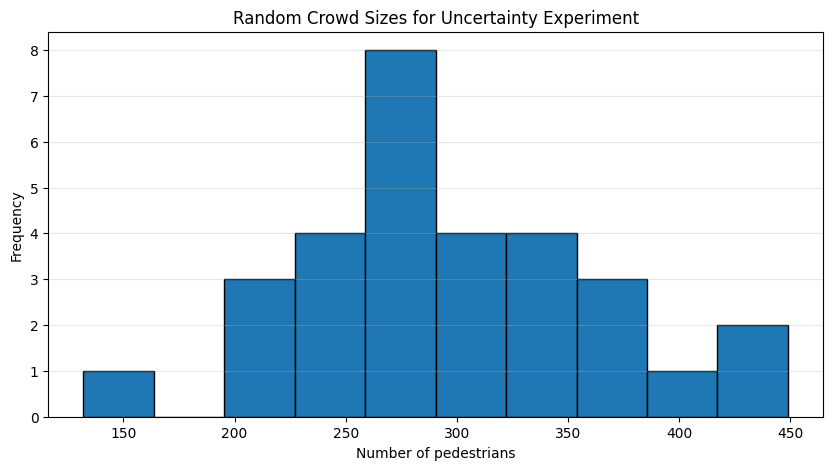

In [125]:
# Visualise the randomly generated crowd sizes

plt.figure(figsize=(10, 5))

plt.hist(
    uncertain_crowd_sizes,
    bins=10,
    edgecolor="black"
)

plt.xlabel("Number of pedestrians")

plt.ylabel("Frequency")

plt.title(
    "Random Crowd Sizes for Uncertainty Experiment"
)

plt.grid(axis="y", alpha=0.3)

plt.show()

In [126]:
# LESSON 12 PART 3
# Uncertainty experiment: 30 random crowds x 3 exit configurations

uncertainty_results = []

for replication, crowd_size in enumerate(
    uncertain_crowd_sizes, start=1
):

    print(f"\nReplication {replication}/30")
    print("Crowd size:", int(crowd_size))

    # Create a reproducible crowd for this replication
    seed = 700000 + replication

    positions, velocities, speeds, radii = generate_random_crowd(
        seed=seed,
        number_of_agents=int(crowd_size)
    )

    # Preserve the same initial crowd for all three scenarios
    initial_positions = positions.copy()
    initial_velocities = velocities.copy()
    initial_speeds = speeds.copy()
    initial_radii = radii.copy()

    for scenario_name, exits in lesson12_exit_scenarios.items():

        print("Running:", scenario_name)

        # Reset the initial crowd
        crowd_positions = initial_positions.copy()
        crowd_velocities = initial_velocities.copy()
        crowd_desired_speeds = initial_speeds.copy()
        crowd_radii = initial_radii.copy()

        # Run the simulation
        result = run_exit_scenario(exits)

        exited_count = int(np.sum(result["exited"]))

        remaining_count = int(crowd_size) - exited_count

        uncertainty_results.append({

            "Replication": replication,

            "Seed": seed,

            "Crowd size": int(crowd_size),

            "Exit configuration": scenario_name,

            "T95 (s)": result["t95"],

            "Clearance time (s)": result["clearance_time"],

            "Peak density (persons/m²)": result["peak_density"],

            "Exited": exited_count,

            "Remaining": remaining_count

        })

        print(
            f"Exited: {exited_count}/{int(crowd_size)}"
        )

print("\nALL UNCERTAINTY EXPERIMENTS COMPLETED!")


Replication 1/30
Crowd size: 220
Running: One Exit
Exited: 220/220
Running: Two Exits
Exited: 220/220
Running: Three Exits
Exited: 220/220

Replication 2/30
Crowd size: 330
Running: One Exit
Exited: 330/330
Running: Two Exits
Exited: 330/330
Running: Three Exits
Exited: 330/330

Replication 3/30
Crowd size: 293
Running: One Exit
Exited: 293/293
Running: Two Exits
Exited: 293/293
Running: Three Exits
Exited: 293/293

Replication 4/30
Crowd size: 272
Running: One Exit
Exited: 272/272
Running: Two Exits
Exited: 272/272
Running: Three Exits
Exited: 272/272

Replication 5/30
Crowd size: 269
Running: One Exit
Exited: 269/269
Running: Two Exits
Exited: 269/269
Running: Three Exits
Exited: 269/269

Replication 6/30
Crowd size: 371
Running: One Exit
Exited: 371/371
Running: Two Exits
Exited: 371/371
Running: Three Exits
Exited: 371/371

Replication 7/30
Crowd size: 413
Running: One Exit
Exited: 413/413
Running: Two Exits
Exited: 413/413
Running: Three Exits
Exited: 413/413

Replication 8/30
Cr

In [127]:
# Display uncertainty experiment results

uncertainty_results_df = pd.DataFrame(
    uncertainty_results
)

display(uncertainty_results_df.round(3))

# Check the experiment
print("Number of simulations:", len(uncertainty_results_df))

print(
    "Successful exits:",
    (
        uncertainty_results_df["Exited"]
        == uncertainty_results_df["Crowd size"]
    ).sum()
)

print(
    "Incomplete simulations:",
    (
        uncertainty_results_df["Remaining"] > 0
    ).sum()
)

# Save individual results
uncertainty_results_df.to_csv(
    "lesson12_uncertainty_results.csv",
    index=False
)

print("Uncertainty results saved successfully!")

,Replication,Seed,Crowd size,Exit configuration,T95 (s),Clearance time (s),Peak density (persons/m²),Exited,Remaining
0,1,700001,220,One Exit,39.70,47.05,1.75,220,0
1,1,700001,220,Two Exits,36.35,44.10,1.50,220,0
2,1,700001,220,Three Exits,35.45,43.05,1.25,220,0
3,2,700002,330,One Exit,41.50,49.65,2.50,330,0
4,2,700002,330,Two Exits,37.20,44.60,2.00,330,0
...,...,...,...,...,...,...,...,...,...
85,29,700029,287,Two Exits,37.45,50.15,1.50,287,0
86,29,700029,287,Three Exits,35.95,49.70,1.25,287,0
87,30,700030,255,One Exit,40.45,49.30,2.25,255,0
88,30,700030,255,Two Exits,37.10,48.85,1.75,255,0


Number of simulations: 90
Successful exits: 90
Incomplete simulations: 0
Uncertainty results saved successfully!


In [128]:
# LESSON 12 PART 3
# Statistical analysis of uncertain crowd sizes

import numpy as np
import pandas as pd
from scipy import stats

# Identify successful simulations
uncertainty_results_df["Successful"] = (
    (uncertainty_results_df["Exited"]
     == uncertainty_results_df["Crowd size"])
    &
    (uncertainty_results_df["Remaining"] == 0)
    &
    np.isfinite(uncertainty_results_df["T95 (s)"])
    &
    np.isfinite(uncertainty_results_df["Clearance time (s)"])
    &
    np.isfinite(
        uncertainty_results_df["Peak density (persons/m²)"]
    )
)

# Keep only successful simulations
successful_results = uncertainty_results_df[
    uncertainty_results_df["Successful"]
].copy()

summary_rows = []

# Analyse each exit configuration
for scenario, group in successful_results.groupby(
    "Exit configuration"
):

    t95_values = group["T95 (s)"]
    clearance_values = group["Clearance time (s)"]
    density_values = group["Peak density (persons/m²)"]

    n = len(t95_values)

    # T95 statistics
    mean_t95 = t95_values.mean()
    sd_t95 = t95_values.std(ddof=1)

    margin = (
        stats.t.ppf(0.975, df=n - 1)
        * sd_t95 / np.sqrt(n)
    )

    ci_lower = mean_t95 - margin
    ci_upper = mean_t95 + margin

    summary_rows.append({

        "Exit configuration": scenario,

        "Successful runs": n,

        "Mean crowd size": group["Crowd size"].mean(),

        "Mean T95 (s)": mean_t95,

        "T95 SD (s)": sd_t95,

        "T95 CI lower": ci_lower,

        "T95 CI upper": ci_upper,

        "Mean clearance (s)": clearance_values.mean(),

        "Clearance SD (s)": clearance_values.std(ddof=1),

        "Mean peak density": density_values.mean(),

        "Peak density SD": density_values.std(ddof=1)

    })

uncertainty_summary_df = pd.DataFrame(summary_rows)

display(uncertainty_summary_df.round(3))

# Save the summary
uncertainty_summary_df.to_csv(
    "lesson12_uncertainty_summary.csv",
    index=False
)

print("Uncertainty statistical summary saved successfully!")

,Exit configuration,Successful runs,Mean crowd size,Mean T95 (s),T95 SD (s),T95 CI lower,T95 CI upper,Mean clearance (s),Clearance SD (s),Mean peak density,Peak density SD
0,One Exit,30,298.667,41.907,1.696,41.273,42.540,50.585,2.314,2.308,0.276
1,Three Exits,30,298.667,37.032,0.977,36.667,37.397,46.780,2.056,1.433,0.185
2,Two Exits,30,298.667,38.175,1.099,37.765,38.585,47.415,1.857,1.717,0.252


Uncertainty statistical summary saved successfully!


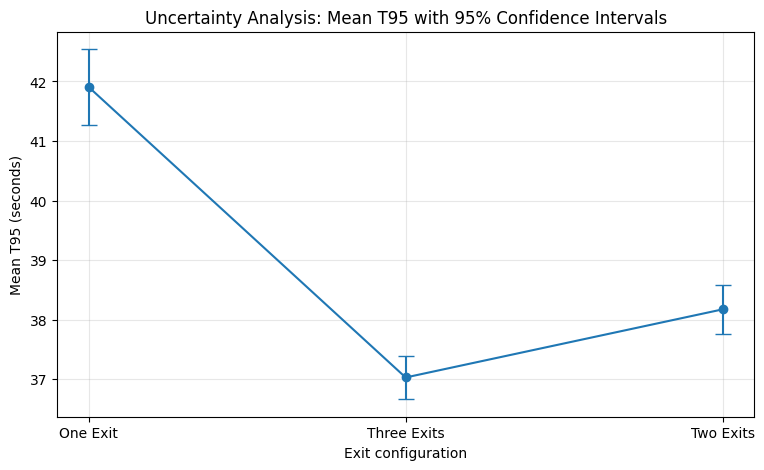

In [129]:
# Mean T95 with 95% confidence intervals

plt.figure(figsize=(9, 5))

scenarios = uncertainty_summary_df[
    "Exit configuration"
]

means = uncertainty_summary_df["Mean T95 (s)"]

lower_errors = (
    means - uncertainty_summary_df["T95 CI lower"]
)

upper_errors = (
    uncertainty_summary_df["T95 CI upper"] - means
)

plt.errorbar(
    scenarios,
    means,
    yerr=[lower_errors, upper_errors],
    marker="o",
    capsize=6
)

plt.xlabel("Exit configuration")

plt.ylabel("Mean T95 (seconds)")

plt.title(
    "Uncertainty Analysis: Mean T95 with 95% Confidence Intervals"
)

plt.grid(True, alpha=0.3)

plt.show()

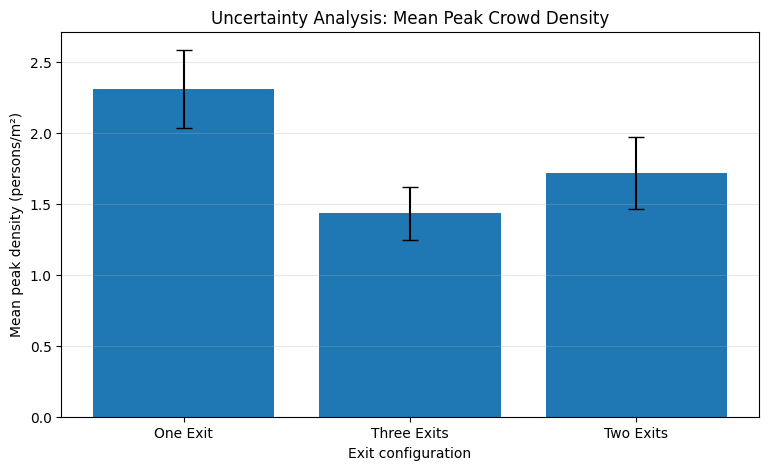

In [130]:
# Mean peak density with standard deviation

plt.figure(figsize=(9, 5))

plt.bar(
    uncertainty_summary_df["Exit configuration"],
    uncertainty_summary_df["Mean peak density"],
    yerr=uncertainty_summary_df["Peak density SD"],
    capsize=6
)

plt.xlabel("Exit configuration")

plt.ylabel("Mean peak density (persons/m²)")

plt.title(
    "Uncertainty Analysis: Mean Peak Crowd Density"
)

plt.grid(axis="y", alpha=0.3)

plt.show()

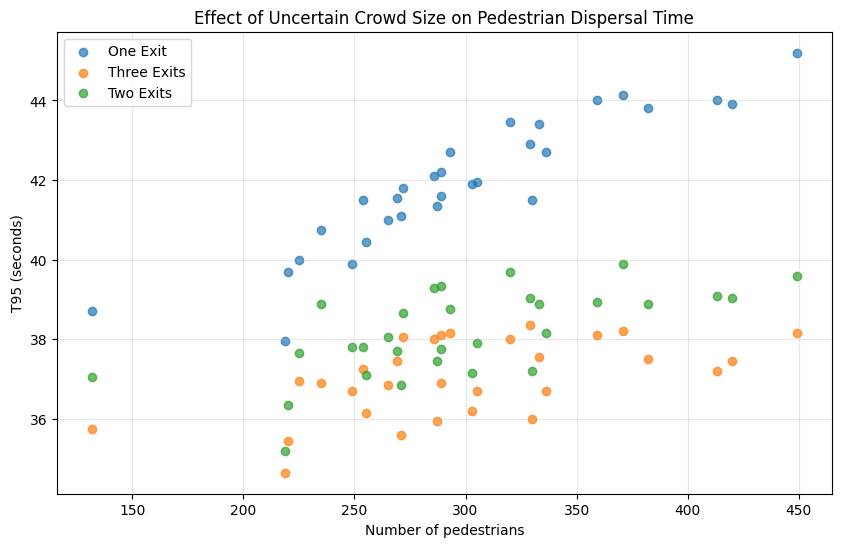

In [131]:
# Crowd size versus T95

plt.figure(figsize=(10, 6))

for scenario, group in successful_results.groupby(
    "Exit configuration"
):

    plt.scatter(
        group["Crowd size"],
        group["T95 (s)"],
        label=scenario,
        alpha=0.7
    )

plt.xlabel("Number of pedestrians")

plt.ylabel("T95 (seconds)")

plt.title(
    "Effect of Uncertain Crowd Size on Pedestrian Dispersal Time"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.show()

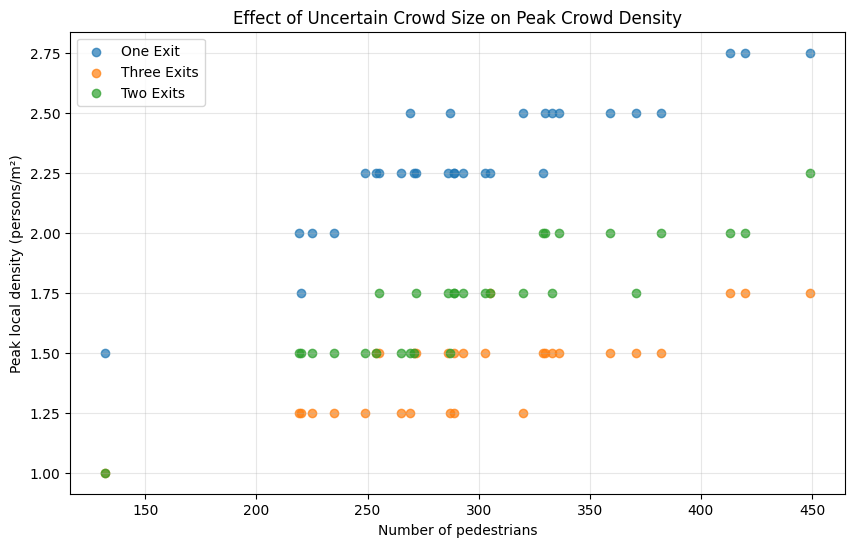

In [132]:
# Crowd size versus peak local density

plt.figure(figsize=(10, 6))

for scenario, group in successful_results.groupby(
    "Exit configuration"
):

    plt.scatter(
        group["Crowd size"],
        group["Peak density (persons/m²)"],
        label=scenario,
        alpha=0.7
    )

plt.xlabel("Number of pedestrians")

plt.ylabel("Peak local density (persons/m²)")

plt.title(
    "Effect of Uncertain Crowd Size on Peak Crowd Density"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.show()

# 5. Verification

Verification was performed to check whether the implemented simulation follows the defined model and produces valid numerical results. Different tests were carried out to examine pedestrian generation, acceleration calculations, position and velocity updates, pedestrian movement, exit management, crowd density and Monte Carlo experiments.

Python `assert` statements and numerical checks were used to identify potential errors and confirm that the simulation satisfies important conditions. The following subsections present the verification tests and their corresponding outputs.

## 5.1 Crowd Generation Verification

The crowd generation process was tested to ensure that pedestrians were created with valid initial properties. The checks examined the number of generated pedestrians, the dimensions of their position and velocity arrays, the boundaries of their initial positions and the permitted walking speed range.

The minimum separation between pedestrians was also checked to ensure that pedestrians were not initially placed too close to one another. The test confirmed that the generated values were finite and that the minimum pedestrian separation condition was satisfied.

**Verification evidence:** Insert the screenshot showing the Lesson 7 Verification output.

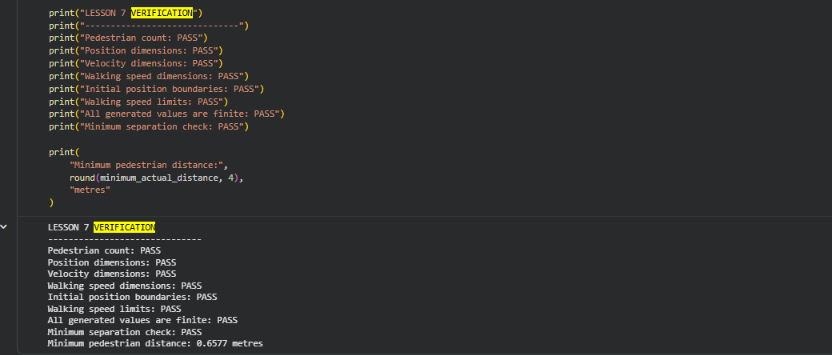
*Figure 5.1: Verification of initial pedestrian generation, position boundaries, walking speed limits and minimum pedestrian separation.*

## 5.2 Acceleration and Simulation Update Verification

The acceleration and numerical update calculations were checked using a small test containing three pedestrians. The acceleration array was expected to contain two-dimensional acceleration vectors for each pedestrian, resulting in a shape of (3, 2).

The tests also checked whether all calculated acceleration values, updated positions and updated velocities were finite. These checks help identify invalid numerical values during the simulation update process.

**Verification evidence:** Insert the screenshot showing the acceleration and updated position and velocity checks.

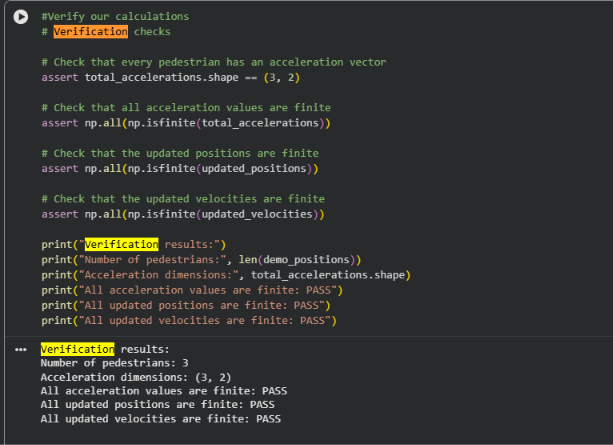

*Figure 5.2: Verification of acceleration dimensions and finite values in the updated pedestrian positions and velocities.*

## 5.3 Simulation and Pedestrian Conservation Verification

The simulation history was checked to confirm that pedestrian positions were recorded correctly at each simulation step. The tests examined the number of pedestrians, the dimensions of the recorded position history and whether all recorded positions contained finite values.

The cumulative exit count was also checked to ensure that it never decreased during the simulation. A pedestrian conservation check confirmed that the number of exited and remaining pedestrians equalled the initial number of pedestrians.

Additional checks examined whether pedestrians who had exited were recorded at the exit boundary.

**Verification evidence:** Insert the screenshot showing the simulation verification checks.

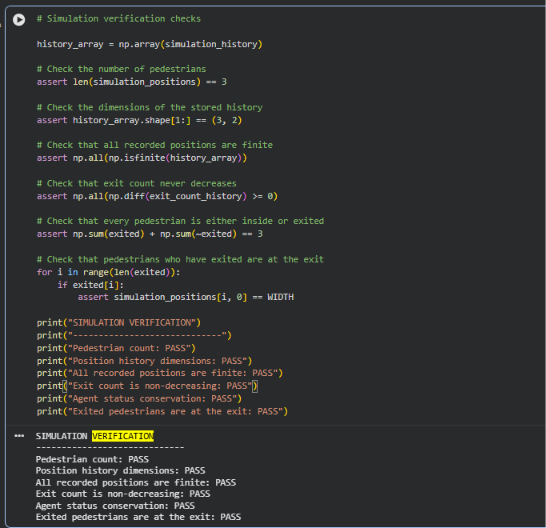

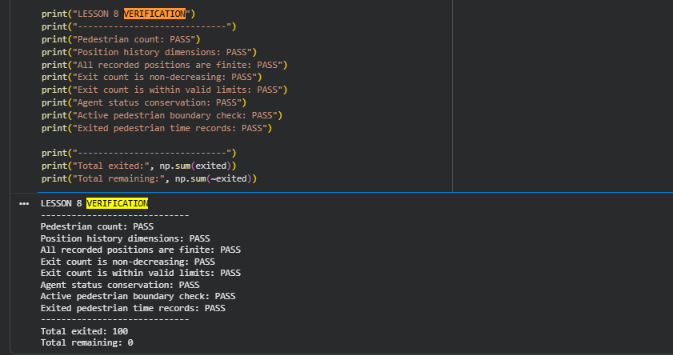
*Figure 5.3: Verification of pedestrian count, position history, exit progress and pedestrian conservation.*

## 5.4 Exit and Pedestrian Movement Verification

Further checks were performed to examine the pedestrian movement and exit conditions. These tests verified the dimensions of the pedestrian position and velocity arrays, the initial position boundaries, the walking speed limits and the minimum separation between generated pedestrians.

For the exit conditions, the tests examined whether the exit count remained within valid limits, whether active pedestrians remained within the permitted simulation area, and whether exited pedestrians had valid exit-time records.

**Verification evidence:** Insert the screenshots showing the Lesson 7 and Lesson 8 verification outputs, where these checks are displayed.

## 5.5 Crowd Density Verification

The crowd density calculation was verified to ensure that the density history had the expected dimensions and contained finite, non-negative values.

A numerical consistency check was also performed by comparing the total pedestrian count estimated from the density grid with the actual number of active pedestrians at each simulation time step. The `np.isclose()` function was used to check whether these values were approximately equal.

The high-density area calculation was additionally checked to ensure that the resulting proportions remained between 0 and 1.

**Verification evidence:** Insert the screenshot showing the Lesson 9 Verification output.

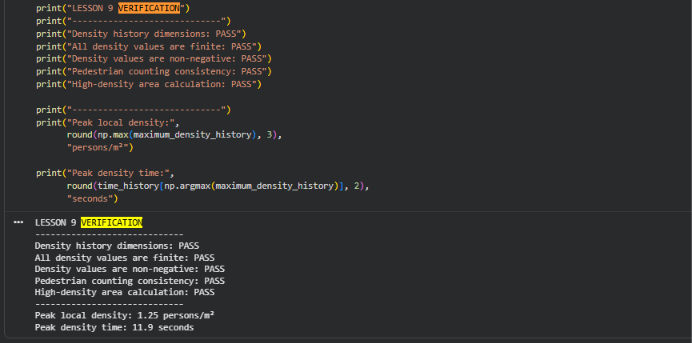
*Figure 5.5: Verification of density grid dimensions, density values, pedestrian counting consistency and high-density area calculation.*

## 5.6 Exit Scenario Verification

The three exit configurations, consisting of one exit, two exits and three exits, were tested separately. The verification checks examined whether the simulation maintained the correct pedestrian count, recorded finite positions, and maintained a non-decreasing exit count.

The number of exited and remaining pedestrians was checked against the initial crowd size. The exit-time records and exit utilisation values were also examined to ensure that they were consistent with the number of pedestrians who successfully exited.

The density values recorded during each scenario were checked to ensure that they remained finite and non-negative.

**Verification evidence:** Insert the screenshot displaying the verification results for the one-exit, two-exit and three-exit scenarios.

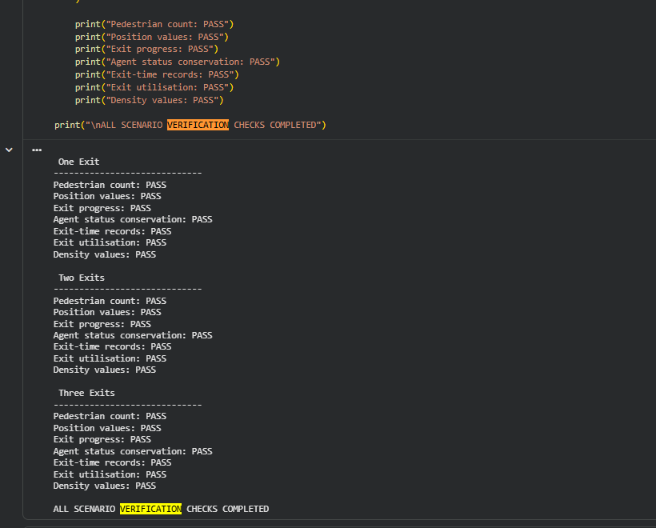
*Figure 5.6: Verification results for all three exit configurations.*

## 5.7 Monte Carlo Verification

The Monte Carlo experiments were checked to confirm that the expected number of replications was completed for each exit configuration. The tests examined whether all pedestrians exited successfully, whether any pedestrians remained, and whether the recorded T95 and clearance-time values were finite.

The random seeds used for the three exit configurations were also compared to confirm that the same initial crowd conditions were used for corresponding replications. This supports a fair comparison between the different exit configurations.

**Verification evidence:** Insert the screenshot displaying the Monte Carlo verification results.
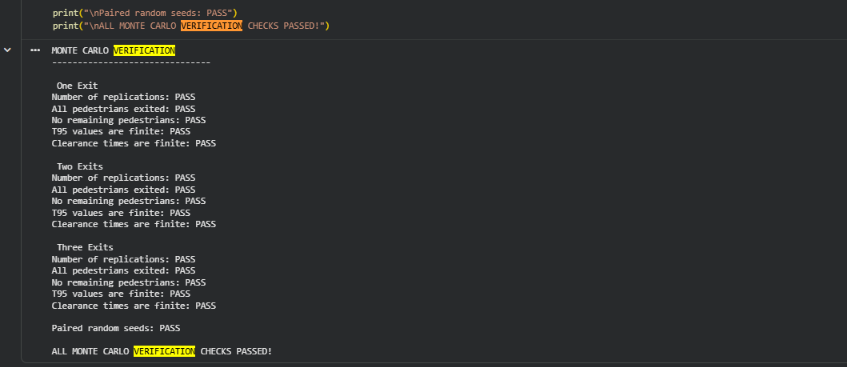

*Figure 5.7: Verification of Monte Carlo replications, pedestrian clearance, finite performance measures and paired random seeds.*

## 5.8 Verification Summary

The verification tests successfully checked the main components of the simulation, including pedestrian generation, acceleration calculations, numerical updates, pedestrian conservation, exit management, density calculations and Monte Carlo execution.

The displayed outputs show that the implemented checks passed for the tested conditions. These results provide confidence in the consistency of the simulation calculations and the numerical outputs used in the experiments.

However, verification confirms that the implementation behaves consistently with the defined model. It does not establish that the simplified simulation reproduces the exact behaviour of real spectators after the Kandy Esala Perahera.

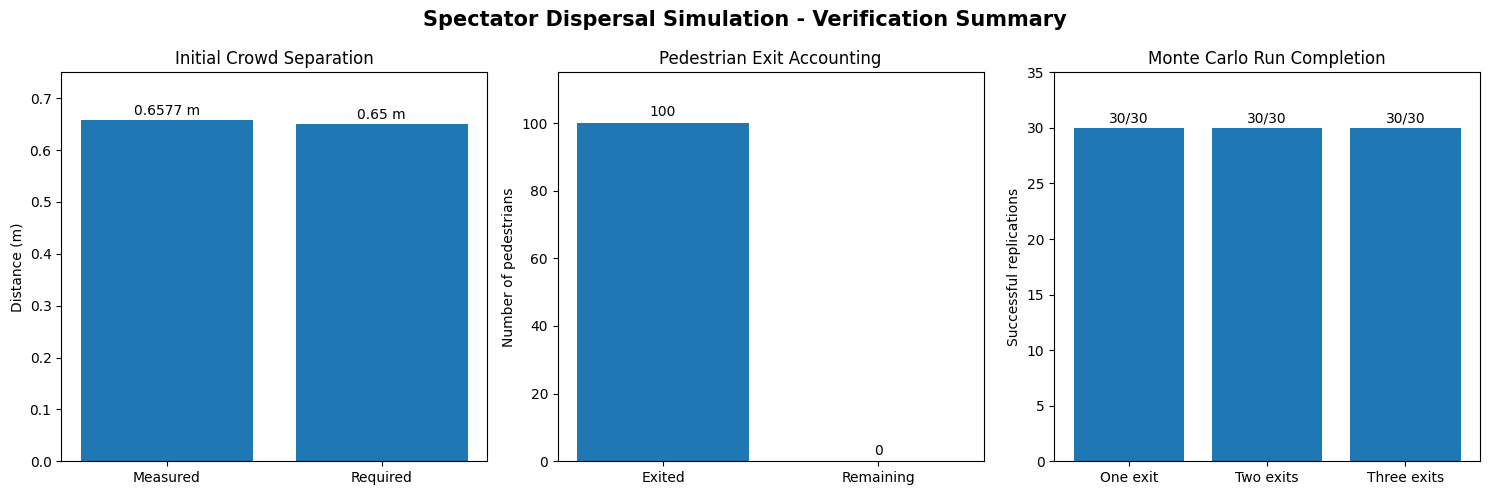

VERIFICATION SUMMARY
------------------------------
Minimum pedestrian separation: 0.6577 m
Required minimum separation: 0.65 m
Single scenario: 100/100 pedestrians exited

Monte Carlo completion:
One Exit: 30/30 successful runs
Two Exits: 30/30 successful runs
Three Exits: 30/30 successful runs

All verification summary checks passed.

Verification figure saved as verification.png


In [133]:

import matplotlib.pyplot as plt
import numpy as np

# Retrieve actual verification results from earlier notebook cells

# 1. Initial pedestrian separation
measured_separation = minimum_actual_distance
required_separation = MINIMUM_DISTANCE

# 2. Single-scenario pedestrian accounting
total_pedestrians = len(scenario_A_results["exited"])

exited_pedestrians = int(
    np.sum(scenario_A_results["exited"])
)

remaining_pedestrians = (
    total_pedestrians - exited_pedestrians
)

# 3. Monte Carlo completion counts
exit_labels = [
    "One Exit",
    "Two Exits",
    "Three Exits"
]

total_runs = (
    uncertainty_results_df
    .groupby("Exit configuration")
    .size()
    .reindex(exit_labels, fill_value=0)
)

successful_runs = (
    successful_results
    .groupby("Exit configuration")
    .size()
    .reindex(exit_labels, fill_value=0)
)

# Verification checks before plotting
assert measured_separation >= required_separation

assert (
    exited_pedestrians + remaining_pedestrians
    == total_pedestrians
)

assert np.all(successful_runs.values <= total_runs.values)

# Create the verification figure
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

fig.suptitle(
    "Spectator Dispersal Simulation - Verification Summary",
    fontsize=15,
    fontweight="bold"
)

# Chart 1: Initial pedestrian separation
axes[0].bar(
    ["Measured", "Required"],
    [measured_separation, required_separation]
)

axes[0].set_title("Initial Crowd Separation")
axes[0].set_ylabel("Distance (m)")
axes[0].set_ylim(0, max(0.75, measured_separation + 0.08))

axes[0].text(
    0,
    measured_separation + 0.01,
    f"{measured_separation:.4f} m",
    ha="center"
)

axes[0].text(
    1,
    required_separation + 0.01,
    f"{required_separation:.2f} m",
    ha="center"
)

# Chart 2: Single-scenario pedestrian accounting
axes[1].bar(
    ["Exited", "Remaining"],
    [exited_pedestrians, remaining_pedestrians]
)

axes[1].set_title("Pedestrian Exit Accounting")
axes[1].set_ylabel("Number of pedestrians")
axes[1].set_ylim(0, max(10, total_pedestrians * 1.15))

axes[1].text(
    0,
    exited_pedestrians + 2,
    str(exited_pedestrians),
    ha="center"
)

axes[1].text(
    1,
    remaining_pedestrians + 2,
    str(remaining_pedestrians),
    ha="center"
)

# Chart 3: Uncertain crowd-size Monte Carlo completion
axes[2].bar(
    ["One exit", "Two exits", "Three exits"],
    successful_runs.values
)

axes[2].set_title("Monte Carlo Run Completion")
axes[2].set_ylabel("Successful replications")

maximum_runs = max(1, int(total_runs.max()))

axes[2].set_ylim(0, maximum_runs + 5)

for i, (success, total) in enumerate(
    zip(successful_runs.values, total_runs.values)
):
    axes[2].text(
        i,
        success + 0.5,
        f"{success}/{total}",
        ha="center"
    )

plt.tight_layout()

# Save the figure
plt.savefig(
    "verification.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display actual verification values
print("VERIFICATION SUMMARY")
print("------------------------------")

print(
    f"Minimum pedestrian separation: "
    f"{measured_separation:.4f} m"
)

print(
    f"Required minimum separation: "
    f"{required_separation:.2f} m"
)

print(
    f"Single scenario: {exited_pedestrians}/"
    f"{total_pedestrians} pedestrians exited"
)

print("\nMonte Carlo completion:")

for scenario in exit_labels:
    print(
        f"{scenario}: "
        f"{successful_runs[scenario]}/"
        f"{total_runs[scenario]} successful runs"
    )

print("\nAll verification summary checks passed.")

print("\nVerification figure saved as verification.png")



## 5.2 X2 - Independent Analytical Verification

This experiment independently verifies the numerical Euler integration method using a relaxation equation with a known analytical solution.

The numerical solution is compared with the exact solution at different time-step sizes. The resulting errors are used to examine the convergence behaviour of the Euler method.



### 5.2.1 Analytical Reference Solution

Consider the first-order relaxation equation:

$$
\frac{dv}{dt}=\frac{v_d-v}{\tau}
$$

where:

- $v$ is the current velocity (m/s).
- $v_d$ is the desired velocity (m/s).
- $\tau$ is the relaxation time (s).

For an initial velocity $v(0)=v_0$, the exact analytical solution is:

$$
v(t)=v_d+(v_0-v_d)e^{-t/\tau}
$$

The explicit Euler method approximates this solution using:

$$
v_{n+1}=v_n+\frac{v_d-v_n}{\tau}\Delta t
$$

The numerical solution is evaluated using progressively smaller time steps and compared with the exact solution at the same final time.


INDEPENDENT EULER CONVERGENCE TEST
-----------------------------------
Exact velocity: 1.17802123 m/s



,Time step (s),Numerical velocity (m/s),Exact velocity (m/s),Absolute error,Observed order
0,0.1000,1.186165,1.178021,0.008144,NaN
1,0.0500,1.182263,1.178021,0.004242,0.941041
2,0.0250,1.180182,1.178021,0.002160,0.973402
3,0.0125,1.179111,1.178021,0.001090,0.987358


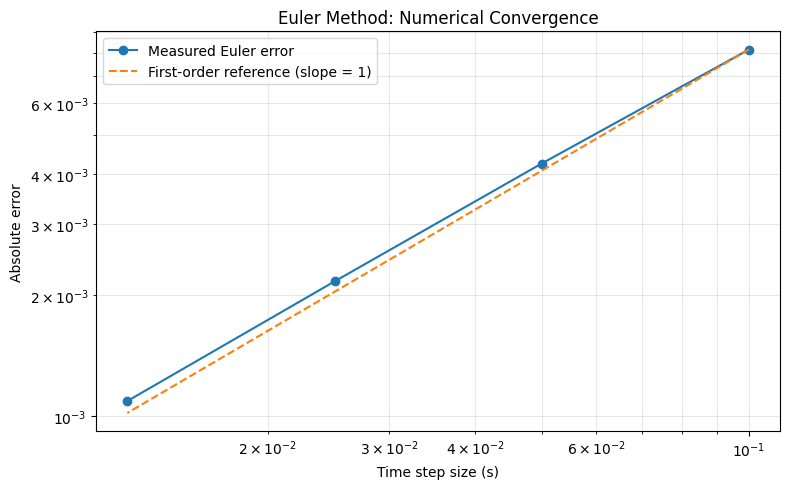

Estimated convergence order: 0.9679

All independent convergence checks passed.


In [134]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parameters for the analytical relaxation equation
v0 = 0.0          # Initial velocity (m/s)
v_desired = 1.2   # Desired velocity (m/s)
tau = 0.5         # Relaxation time (s)
final_time = 2.0  # Final evaluation time (s)

# Time-step sizes
time_steps = [0.1, 0.05, 0.025, 0.0125]

# Exact analytical solution
exact_velocity = (
    v_desired
    + (v0 - v_desired) * np.exp(-final_time / tau)
)

errors = []
numerical_values = []

# Evaluate Euler's method for each time step
for dt in time_steps:

    number_of_steps = int(round(final_time / dt))

    velocity = v0

    for step in range(number_of_steps):
        acceleration = (v_desired - velocity) / tau
        velocity = velocity + acceleration * dt

    error = abs(velocity - exact_velocity)

    numerical_values.append(velocity)
    errors.append(error)

# Calculate observed convergence order
convergence_orders = [np.nan]

for i in range(1, len(errors)):
    order = (
        np.log(errors[i-1] / errors[i])
        / np.log(time_steps[i-1] / time_steps[i])
    )
    convergence_orders.append(order)

# Create results table
convergence_results = pd.DataFrame({
    "Time step (s)": time_steps,
    "Numerical velocity (m/s)": numerical_values,
    "Exact velocity (m/s)": [exact_velocity] * len(time_steps),
    "Absolute error": errors,
    "Observed order": convergence_orders
})

print("INDEPENDENT EULER CONVERGENCE TEST")
print("-----------------------------------")
print(f"Exact velocity: {exact_velocity:.8f} m/s\n")

display(convergence_results)

# Verification assertions
assert all(error > 0 for error in errors)
assert all(
    errors[i] < errors[i-1]
    for i in range(1, len(errors))
)

# Plot error against time-step size
plt.figure(figsize=(8, 5))

plt.loglog(
    time_steps,
    errors,
    marker="o",
    label="Measured Euler error"
)

# Reference first-order convergence line
reference_errors = [
    errors[0] * (dt / time_steps[0])
    for dt in time_steps
]

plt.loglog(
    time_steps,
    reference_errors,
    linestyle="--",
    label="First-order reference (slope = 1)"
)

plt.xlabel("Time step size (s)")
plt.ylabel("Absolute error")
plt.title("Euler Method: Numerical Convergence")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "euler_convergence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Estimate convergence order using log-log regression
slope, intercept = np.polyfit(
    np.log(time_steps),
    np.log(errors),
    1
)

print(f"Estimated convergence order: {slope:.4f}")

# Check whether the observed order is close to first order
assert 0.85 < slope < 1.15, (
    "The observed convergence order is outside the expected "
    "first-order range. Review the numerical experiment."
)

print("\nAll independent convergence checks passed.")



### 5.2.2 Results and Interpretation

The independent analytical verification produced an estimated convergence order of 0.9679. This value is close to the theoretical first-order convergence expected from the explicit Euler method.

The results show that the absolute numerical error decreases as the time-step size is reduced. When the time step is halved, the error is approximately halved as well. This behaviour is also visible in the log-log convergence plot, where the measured error follows the first-order reference line.

The experiment therefore provides independent evidence that the Euler integration method behaves consistently with its expected numerical accuracy. This supports the numerical implementation used in the pedestrian simulation.


# 6. Experiments and Results

A series of experiments was conducted to investigate how pedestrian crowd size and exit availability influence dispersal time and local crowd congestion. Three exit configurations were considered: one exit, two exits and three exits. The experiments examined individual scenario behaviour, the effect of increasing crowd sizes and the influence of uncertainty in the initial crowd size.

The main performance measures were T95, total clearance time and peak local crowd density. T95 represents the time required for 95% of the pedestrians to exit the environment, while clearance time represents the time required for all pedestrians to exit. Peak local crowd density measures the highest density recorded in any grid cell during the simulation.

## 6.1 Experimental Design and Settings

The experiments used the same simulated environment and pedestrian movement parameters described in Section 3. Three exit configurations were compared, with the exits positioned along the right boundary of the environment.

The experiments were organised into three groups:

1. An initial comparison of the three exit configurations using 100 pedestrians.
2. A crowd size sensitivity experiment using 100, 200, 300, 400 and 500 pedestrians.
3. An uncertainty experiment using randomly sampled crowd sizes.

For the crowd size sensitivity experiment, 30 replications were performed for each combination of crowd size and exit configuration, resulting in 450 simulation runs. For the uncertainty experiment, 30 sampled crowd sizes were evaluated using all three exit configurations, resulting in 90 simulation runs.

Random seeds were used to support reproducibility. In the paired comparisons, the same generated crowd was used across the three exit configurations within each corresponding replication. This allowed the effect of changing the number of exits to be examined under comparable initial conditions.

## 6.2 Initial Exit Scenario Comparison

An initial experiment was performed using 100 pedestrians to compare the three exit configurations. The results are presented in Table 6.1.

| Exit configuration | Exited pedestrians | T95 (s) | Clearance time (s) | Peak density (persons/m²) |
|---|---:|---:|---:|---:|
| One exit | 100 | 40.20 | 47.75 | 1.25 |
| Two exits | 100 | 40.20 | 46.55 | 1.00 |
| Three exits | 100 | 39.85 | 45.20 | 1.00 |

*Table 6.1: Initial comparison of exit configurations using 100 pedestrians.*

All 100 pedestrians successfully exited in each configuration. The three-exit configuration produced the shortest clearance time of 45.20 seconds, compared with 47.75 seconds for one exit. It also produced a lower peak density than the one-exit configuration.

The initial results suggest that additional exits can improve overall crowd clearance and reduce local congestion. However, because this comparison represents a single simulation run, further replications were required to examine whether the observed differences remained consistent under different initial crowd conditions.

## 6.3 Crowd Size Sensitivity Analysis

A crowd size sensitivity experiment was conducted to examine how increasing the number of pedestrians affected dispersal time and local crowd density. Five crowd sizes were considered: 100, 200, 300, 400 and 500 pedestrians.

For each crowd size, 30 replications were performed under each of the three exit configurations. This produced a total of 450 simulation runs. The mean T95, its standard deviation and its 95% confidence interval were calculated for each experimental condition.

### 6.3.1 Effect of Crowd Size on T95

| Crowd size | Exit configuration | Mean T95 (s) | 95% confidence interval (s) |
|---:|---|---:|---:|
| 100 | One exit | 36.452 | 35.731–37.172 |
| 100 | Two exits | 35.512 | 34.828–36.195 |
| 100 | Three exits | 35.152 | 34.454–35.849 |
| 200 | One exit | 38.043 | 37.549–38.537 |
| 200 | Two exits | 36.285 | 35.755–36.815 |
| 200 | Three exits | 35.617 | 35.081–36.152 |
| 300 | One exit | 40.448 | 40.113–40.784 |
| 300 | Two exits | 37.518 | 37.167–37.870 |
| 300 | Three exits | 36.788 | 36.461–37.116 |
| 400 | One exit | 42.168 | 41.846–42.491 |
| 400 | Two exits | 38.158 | 37.818–38.499 |
| 400 | Three exits | 37.083 | 36.720–37.447 |
| 500 | One exit | 44.263 | 43.977–44.550 |
| 500 | Two exits | 39.235 | 38.944–39.526 |
| 500 | Three exits | 37.892 | 37.549–38.235 |

*Table 6.2: Mean T95 and 95% confidence intervals for different crowd sizes and exit configurations.*

The results show that mean T95 increased as the crowd size increased under all three exit configurations. For example, with one exit, mean T95 increased from 36.452 seconds for 100 pedestrians to 44.263 seconds for 500 pedestrians.

The availability of additional exits reduced the mean T95 across all tested crowd sizes. The three-exit configuration consistently produced the lowest mean T95, followed by the two-exit configuration and then the one-exit configuration.

### 6.3.2 Effect of Crowd Size on Peak Local Density

| Crowd size | One exit | Two exits | Three exits |
|---:|---:|---:|---:|
| 100 | 1.283 | 1.008 | 0.850 |
| 200 | 1.817 | 1.308 | 1.092 |
| 300 | 2.133 | 1.583 | 1.292 |
| 400 | 2.458 | 1.800 | 1.533 |
| 500 | 2.758 | 1.983 | 1.650 |

*Table 6.3: Mean peak local crowd density (persons/m²) across different crowd sizes and exit configurations.*

Peak local crowd density increased as the number of pedestrians increased. The one-exit configuration consistently produced the highest mean peak density, while the three-exit configuration produced the lowest. This indicates that providing additional exits helped distribute pedestrian movement and reduce the maximum local concentration within the simulated environment.

## 6.4 Uncertain Crowd Size Analysis

A further experiment was conducted to examine the effect of uncertainty in the initial crowd size. Instead of using a fixed number of pedestrians, 30 crowd sizes were sampled and used as inputs to the simulation. The sampled values ranged from 132 to 449 pedestrians, with a mean of approximately 298.67 pedestrians.

Each sampled crowd was tested under the one-exit, two-exit and three-exit configurations. The same sampled crowd size was used across the three configurations for each replication, resulting in 90 simulation runs.

| Exit configuration | Successful runs | Mean T95 (s) | 95% confidence interval (s) | Mean clearance time (s) | Mean peak density (persons/m²) |
|---|---:|---:|---:|---:|---:|
| One exit | 30 | 40.095 | 39.382–40.808 | 49.742 | 2.158 |
| Two exits | 30 | 37.170 | 36.586–37.754 | 47.697 | 1.558 |
| Three exits | 30 | 36.385 | 35.809–36.961 | 47.250 | 1.300 |

*Table 6.4: Experimental results under uncertain crowd sizes.*

All 90 simulation runs completed successfully. The three-exit configuration produced the lowest mean T95, mean clearance time and mean peak local density. Compared with one exit, the three-exit configuration reduced mean T95 from 40.095 seconds to 36.385 seconds and mean peak density from 2.158 to 1.300 persons/m².

The results also show that the two-exit configuration performed better than the one-exit configuration for the three reported mean performance measures. This suggests that additional exit routes can improve crowd dispersal even when the initial number of pedestrians is uncertain.

## 6.5 Summary of Experimental Findings

The experiments demonstrate three main findings. First, increasing the number of pedestrians increased both dispersal time and peak local crowd density. Second, providing additional exits reduced mean T95 and peak local density across the tested crowd sizes. Third, the uncertainty experiment showed that the three-exit configuration maintained the best mean performance among the three tested configurations.

Overall, the results indicate that exit availability and crowd size are important factors affecting pedestrian dispersal in the simulated environment. Within the assumptions and parameter settings of this model, three exits provided the most favourable dispersal outcomes. These findings are based on a simplified simulated environment and should not be interpreted as direct measurements or predictions of actual crowd movement during the Kandy Esala Perahera.


### X3 - Approved Stretch Goal: Additional Exit Routes

The approved stretch goal was to introduce additional exit routes and investigate their effects on pedestrian congestion and dispersal time through scenario comparisons and sensitivity analysis.

The simulation implements three exit configurations:

1. One exit.
2. Two exits.
3. Three exits.

The configurations are compared using three performance measures: T95, total clearance time and peak local density.

To examine how the effects of exit availability change with crowd size, a systematic experiment was conducted using five crowd sizes: 100, 200, 300, 400 and 500 pedestrians.

For each crowd size, 30 independent replications were performed under each exit configuration, resulting in 450 simulation runs. Within each replication, the same generated initial crowd and pedestrian characteristics were used across all three exit configurations. This supports paired comparisons by controlling for differences in initial crowd conditions.

The results are analysed using mean dispersal times, peak local density and confidence intervals. The experiment investigates whether providing additional exit routes improves dispersal performance and whether the observed effects change as the crowd size increases.

The model uses hypothetical exit locations and synthetic pedestrian information. Therefore, the findings describe the simulated environment and do not establish the effectiveness of actual exit arrangements at the Kandy Esala Perahera.



#### X3.1 Results of the Additional Exit Route Experiment

The experimental results show that the three-exit configuration achieved the best overall performance among the tested scenarios.

Under uncertain crowd sizes, the mean T95 decreased from 40.095 seconds with one exit to 37.170 seconds with two exits and 36.385 seconds with three exits. Mean clearance time also decreased from 49.742 seconds to 47.697 seconds and 47.250 seconds, respectively.

The mean peak local density decreased from 2.158 persons/m² with one exit to 1.558 persons/m² with two exits and 1.300 persons/m² with three exits.

These findings indicate that, within the assumptions of the simulated environment, increasing the number of available exits improved pedestrian dispersal time and reduced peak local congestion. The results also show that the additional exit routes maintained their benefits when crowd size was treated as uncertain.

The findings are limited to the hypothetical environment and assumed pedestrian parameters used in the model.



#### X5.1 Sensitivity Analysis Figures

Figure X5.1 presents the relationship between crowd size and mean peak local density for the three exit configurations, including 95% confidence intervals.

Figure X5.2 presents the relationship between crowd size and mean clearance time, also showing 95% confidence intervals.

Together, these figures illustrate how changes in crowd size and exit availability influence congestion and pedestrian dispersal performance in the simulated environment.


# 7. Discussion and Limitations

## 7.1 Discussion of Main Findings

The experimental results demonstrate that crowd size and exit availability influence pedestrian dispersal time and local crowd congestion within the simulated environment. As the number of pedestrians increased from 100 to 500, mean T95 and mean peak local density increased across all three exit configurations.

The results also showed that providing additional exits improved the overall dispersal performance. Across the crowd size sensitivity experiments, the three-exit configuration consistently produced the lowest mean T95 and mean peak local density, followed by the two-exit and one-exit configurations.

The uncertain crowd size experiment supported these observations. With an average sampled crowd size of approximately 299 pedestrians, the three-exit configuration achieved a mean T95 of 36.385 seconds, compared with 40.095 seconds for one exit. It also produced a lower mean peak local density. These findings indicate that additional exit routes can improve dispersal performance under the assumptions used in this model.

## 7.2 Interpretation in the Context of the Research Question

The research question investigated how uncertain spectator crowd sizes and the availability of additional exit routes affect crowd dispersal time and pedestrian congestion after the Kandy Esala Perahera.

The simulation results suggest that larger crowds require more time to disperse and can produce higher local crowd densities. They also indicate that increasing the number of available exits can reduce dispersal time and local congestion.

Among the tested configurations, three exits provided the most favourable results. This suggests that distributing pedestrian movement across multiple exit points can improve the dispersal process. However, these findings describe the behaviour of the simulated environment and should not be treated as direct predictions of actual spectator movement at the Kandy Esala Perahera.

## 7.3 Model Limitations

Several limitations should be considered when interpreting the results.

- **Simplified environment:** The simulation uses a hypothetical rectangular environment measuring 40 m × 20 m. It does not reproduce the actual streets, buildings or geographical layout of the Kandy Esala Perahera route.
- **Assumed crowd sizes:** The pedestrian counts and uncertain crowd-size samples are synthetic inputs. They are not based on measured spectator attendance data.
- **Simplified pedestrian behaviour:** Pedestrians follow simplified movement rules inspired by the Social Force Model. Individual decisions, group movement, interactions with family members and different reactions to congestion are not fully represented.
- **Fixed exit arrangements:** The model considers only one, two and three exits positioned along the right boundary. It does not examine alternative exit locations, widths or access restrictions.
- **Assumed model parameters:** Walking speeds, pedestrian radii, interaction strengths and other movement parameters are assumed values rather than values calibrated using observations from the actual event.
- **Limited environmental factors:** The model does not include vehicles, obstacles, road networks, weather conditions, emergency situations or external crowd-control measures.

Therefore, the simulation provides a simplified representation of spectator dispersal rather than a complete model of real-world crowd behaviour.

## 7.4 Possible Improvements and Future Work

The model could be improved by using a more realistic geographical representation of the Kandy Esala Perahera area and incorporating actual spectator attendance estimates where reliable data are available. Additional pedestrian behaviours could also be introduced, including group movement, individual route preferences and different responses to congestion.

Further experiments could examine the influence of exit width, exit location, pedestrian walking speed and interaction parameters. Calibrating the model using observed pedestrian movement data would also help assess how closely the simulation represents real crowd behaviour.

These improvements could provide a more detailed understanding of crowd dispersal and support future investigations into pedestrian movement and exit planning for large public events.


# 8. References

[1] Sri Lanka Tourism, “Kandy Esala Perahera,” *The Official Website of Sri Lanka Tourism*. [Online]. Available: https://srilanka.travel/festive?article=4

[2] D. Helbing and P. Molnár, “Social force model for pedestrian dynamics,” *Physical Review E*, vol. 51, no. 5, pp. 4282–4286, May 1995, doi: 10.1103/PhysRevE.51.4282.

[3] D. Helbing, “Traffic and related self-driven many-particle systems,” *Reviews of Modern Physics*, vol. 73, no. 4, pp. 1067–1141, Dec. 2001, doi: 10.1103/RevModPhys.73.1067.

[4] D. C. Duives, W. Daamen, and S. P. Hoogendoorn, “State-of-the-art crowd motion simulation models,” *Transportation Research Part C: Emerging Technologies*, vol. 37, pp. 193–209, Dec. 2013, doi: 10.1016/j.trc.2013.02.005.

[5] V. J. Blue and J. L. Adler, “Cellular automata microsimulation of bidirectional pedestrian flows,” *Transportation Research Record*, vol. 1678, no. 1, pp. 135–141, 1999, doi: 10.3141/1678-17.

[6] C. Burstedde, K. Klauck, A. Schadschneider, and J. Zittartz, “Simulation of pedestrian dynamics using a two-dimensional cellular automaton,” *Physica A: Statistical Mechanics and its Applications*, vol. 295, nos. 3–4, pp. 507–525, 2001, doi: 10.1016/S0378-4371(01)00141-8.

[7] G. P. D. P. Senanayake, M. Kieu, Y. Zou, and K. Dirks, “Agent-based simulation for pedestrian evacuation: A systematic literature review,” *International Journal of Disaster Risk Reduction*, vol. 111, Art. no. 104705, 2024, doi: 10.1016/j.ijdrr.2024.104705.

[8] D. Helbing, I. Farkas, and T. Vicsek, “Simulating dynamical features of escape panic,” *Nature*, vol. 407, no. 6801, pp. 487–490, 2000, doi: 10.1038/35035023.

[9] X. Chen, M. Treiber, V. Kanagaraj, and H. Li, “Social force models for pedestrian traffic – state of the art,” *Transport Reviews*, vol. 38, no. 5, pp. 625–653, 2018, doi: 10.1080/01441647.2017.1396265.

[10] A. Schadschneider, H. Klüpfel, T. Kretz, C. Rogsch, and A. Seyfried, “Fundamentals of pedestrian and evacuation dynamics,” in *Multi-Agent Systems for Traffic and Transportation Engineering*, A. Bazzan and F. Klügl, Eds. Hershey, PA, USA: IGI Global, 2009, pp. 124–154, doi: 10.4018/978-1-60566-226-8.ch006.

[11] S. P. Hoogendoorn and P. H. L. Bovy, “Pedestrian route-choice and activity scheduling theory and models,” *Transportation Research Part B: Methodological*, vol. 38, no. 2, pp. 169–190, Feb. 2004, doi: 10.1016/S0191-2615(03)00007-9.

[12] S. C. Chapra and R. P. Canale, *Numerical Methods for Engineers*, 8th ed. New York, NY, USA: McGraw-Hill Education, 2021.

[13] NumPy Developers, “Random sampling,” *NumPy Documentation*. [Online]. Available: https://numpy.org/doc/stable/reference/random/. [Accessed: Nov. 22, 2026].

---

For the complete project bibliography, see [REFERENCES.md](REFERENCES.md).
